# Customer Credit Risk Scoring — German Credit (end-to-end)

**FinTech Masterclass final project** · Notebook language: English · Executive report: Persian (separate PDF)

This notebook runs the whole analysis **from the raw `german.data` file to the final explanations**, in a single reproducible flow:

| Part | Content |
|---|---|
| 1 | Initial data audit (files, codes, numeric-version comparison, target mapping) |
| 2 | Data cleaning & EDA (target, numerical, outliers, categorical, associations) |
| 3 | Train/test split → leakage-free preprocessing, feature engineering, feature selection |
| 4 | Protected-type inputs: sensitivity check and exclusion decision |
| 5 | Modeling: baseline tree, Logistic Regression, Random Forest, XGBoost; Stratified CV, hyper-parameter search, nested CV, imbalance study |
| 6 | Evaluation and business cost: thresholds, expected cost, model selection, single final Test evaluation, scenarios, fairness audit |
| 7 | Explainability: SHAP (global + local), XGBoost cross-check, proxy check |
| 8 | Causality vs. correlation |
| 9 | LLM / adverse-action prompt, sample output and automatic validator |
| 10 | Summary, limitations and audit trail |

**How to run.** Place `german.data` (and optionally `german.data-numeric`) in `./data/` or next to the notebook, then *Restart & Run All*. Full run ≈ 25–35 min on one CPU core (nested CV and the imbalance study dominate). Set the environment variable `GC_FAST=1` for a quick smoke test with smaller searches (numbers will then differ from the report).

**Reproducibility.** Global `SEED = 42`; every splitter, search, bootstrap and model receives an explicit seed; models use `n_jobs=1`. No cell depends on a manually produced file.

**Rules followed throughout** (from the project brief): no invented data; no result is stated before the code that computes it; correlation, prediction and causation are kept apart; all learned preprocessing happens **inside Pipelines fitted on training folds only**; the Test set is untouched until the single final evaluation in Part 6; limitations are stated explicitly.

**Source priority** (conflict rule): PDF brief for deliverables → `german.doc` for meaning/codes → `german.data` for analysis → `german.data-numeric` only for validation.

In [1]:
# ---- Setup -----------------------------------------------------------------------------------------------
import os, sys, json, time, warnings, math, itertools, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
FAST = os.environ.get("GC_FAST", "0") == "1"          # smoke-test switch (smaller searches / fewer bootstraps)
TEST_TOUCHED = False                                    # flipped to True only by the single final Test evaluation (Part 6)

OUT = Path("outputs"); FIG = OUT / "figures"; RES = OUT / "results"; CACHE = OUT / "cache"
for p in (OUT, FIG, RES, CACHE):
    p.mkdir(parents=True, exist_ok=True)
import joblib
def cached(name, fn):
    """Checkpoint helper for the slow steps: compute once, store in outputs/cache, reuse if the notebook is re-run after an interruption.
    It only speeds things up: with an empty cache folder every step is computed from scratch with identical results."""
    p = CACHE / f"{name}{'_fast' if FAST else ''}.joblib"
    if p.exists():
        print(f"[cache] loaded '{name}'"); return joblib.load(p)
    obj = fn(); joblib.dump(obj, p); return obj

sns.set_theme(style="whitegrid", font_scale=0.95)
GOOD_C, BAD_C = "#2a9d8f", "#d62839"

def savefig(name, dpi=140):
    """Save the current matplotlib figure to outputs/figures and display it."""
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=dpi, bbox_inches="tight")
    plt.show()

def find_file(name, required=True):
    """Locate an input file in a few conventional places."""
    for base in ("data", ".", "/mnt/user-data/uploads"):
        p = Path(base) / name
        if p.exists():
            return p
    if required:
        raise FileNotFoundError(f"{name} not found (put it in ./data or next to the notebook)")
    return None

def wilson(k, n, z=1.96):
    """Wilson 95% confidence interval for a proportion k/n."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (c - h, c + h)

def cramers_v(ct, corrected=True):
    """Cramér's V (Bergsma bias-corrected by default) for a contingency table."""
    chi2 = stats.chi2_contingency(ct, correction=False)[0]; n = ct.values.sum(); r, k = ct.shape
    phi2 = chi2 / n
    if not corrected:
        return np.sqrt(phi2 / min(r - 1, k - 1))
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1)); rc = r - (r - 1)**2 / (n - 1); kc = k - (k - 1)**2 / (n - 1)
    return np.sqrt(phi2c / min(kc - 1, rc - 1))

# ---- column names / types exactly as defined in german.doc (attribute order 1..20 + class) -----------------------
COLS = ["checking_status", "duration_months", "credit_history", "purpose", "credit_amount", "savings_status",
        "employment_since", "installment_rate", "personal_status_sex", "other_debtors", "residence_since", "property",
        "age", "other_installment_plans", "housing", "existing_credits", "job", "num_dependents", "telephone",
        "foreign_worker", "target_raw"]
NUM = ["duration_months", "credit_amount", "installment_rate", "residence_since", "age", "existing_credits", "num_dependents"]
CAT = [c for c in COLS[:-1] if c not in NUM]                      # the 13 categorical attributes
LAB = {   # short readable labels (german.doc)
 "checking_status": {"A11": "<0 DM", "A12": "0-200 DM", "A13": ">=200 DM/salary", "A14": "no account"},
 "credit_history": {"A30": "no credits/all paid", "A31": "all paid (this bank)", "A32": "paid duly till now", "A33": "past delay", "A34": "critical/other credits"},
 "purpose": {"A40": "car (new)", "A41": "car (used)", "A42": "furniture", "A43": "radio/TV", "A44": "domestic appl.", "A45": "repairs", "A46": "education", "A48": "retraining", "A49": "business", "A410": "others"},
 "savings_status": {"A61": "<100 DM", "A62": "100-500", "A63": "500-1000", "A64": ">=1000", "A65": "unknown/none"},
 "employment_since": {"A71": "unemployed", "A72": "<1y", "A73": "1-4y", "A74": "4-7y", "A75": ">=7y"},
 "personal_status_sex": {"A91": "male div/sep", "A92": "female div/sep/mar", "A93": "male single", "A94": "male mar/wid"},
 "other_debtors": {"A101": "none", "A102": "co-applicant", "A103": "guarantor"},
 "property": {"A121": "real estate", "A122": "savings agr./insurance", "A123": "car/other", "A124": "unknown/none"},
 "other_installment_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
 "housing": {"A151": "rent", "A152": "own", "A153": "for free"},
 "job": {"A171": "unemployed/unskilled non-res", "A172": "unskilled resident", "A173": "skilled", "A174": "management/highly qualified"},
 "telephone": {"A191": "none", "A192": "yes"}, "foreign_worker": {"A201": "yes", "A202": "no"}}

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", __import__("scipy").__version__)
import sklearn; print("scikit-learn", sklearn.__version__, "| FAST mode:", FAST)

python 3.12.3 | numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1
scikit-learn 1.9.1 | FAST mode: False


---
# Part 1 — Initial data audit

Goal: verify the physical structure of the files, the coding against `german.doc`, and the relationship between the original and the numeric version, **before any modelling**.

In [2]:
# ---- 1.1 physical structure of german.data --------------------------------------------------------------------
DATA_PATH = find_file("german.data")
raw_bytes = DATA_PATH.read_bytes()
text = raw_bytes.decode("ascii")                                  # raises if any non-ASCII byte exists
lines = [l for l in text.split("\n") if l]
print(f"file: {DATA_PATH} | {len(raw_bytes):,} bytes | ASCII ok | CRLF: {raw_bytes.count(b'\r\n')} | tabs: {raw_bytes.count(b'\t')} | commas: {raw_bytes.count(b',')}")
print("lines:", len(lines), "| fields per line:", dict(Counter(len(l.split(' ')) for l in lines)),
      "| double spaces:", any("  " in l for l in lines), "| header present:", False)

raw = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=COLS)
print("shape:", raw.shape, "| missing cells:", int(raw.isna().sum().sum()), "| duplicate rows:", int(raw.duplicated().sum()),
      "| duplicates ignoring target:", int(raw.drop(columns="target_raw").duplicated().sum()))
assert raw.shape == (1000, 21)

file: data/german.data | 79,793 bytes | ASCII ok | CRLF: 0 | tabs: 0 | commas: 0
lines: 1000 | fields per line: {21: 1000} | double spaces: False | header present: False
shape: (1000, 21) | missing cells: 0 | duplicate rows: 0 | duplicates ignoring target: 0


In [3]:
# ---- 1.2 codes versus german.doc ----------------------------------------------------------------------------------
ALLOWED = {
 "checking_status": ["A11","A12","A13","A14"], "credit_history": ["A30","A31","A32","A33","A34"],
 "purpose": ["A40","A41","A42","A43","A44","A45","A46","A47","A48","A49","A410"], "savings_status": ["A61","A62","A63","A64","A65"],
 "employment_since": ["A71","A72","A73","A74","A75"], "personal_status_sex": ["A91","A92","A93","A94","A95"],
 "other_debtors": ["A101","A102","A103"], "property": ["A121","A122","A123","A124"], "other_installment_plans": ["A141","A142","A143"],
 "housing": ["A151","A152","A153"], "job": ["A171","A172","A173","A174"], "telephone": ["A191","A192"], "foreign_worker": ["A201","A202"]}
rows = []
for c, allowed in ALLOWED.items():
    obs = set(raw[c].unique())
    rows.append(dict(feature=c, levels_observed=len(obs), unexpected_codes=sorted(obs - set(allowed)), documented_but_never_observed=sorted(set(allowed) - obs)))
code_check = pd.DataFrame(rows).set_index("feature"); display(code_check)
assert all(len(x) == 0 for x in code_check.unexpected_codes), "undocumented codes found"

num = raw[NUM + ["target_raw"]]
print("\nnumeric ranges:"); display(num.describe().T[["min", "max"]])
print("non-integer numerics:", int((num % 1 != 0).sum().sum()), "| target values:", sorted(raw.target_raw.unique()))

,levels_observed,unexpected_codes,documented_but_never_observed
feature,,,
checking_status,4,[],[]
credit_history,5,[],[]
purpose,10,[],[A47]
savings_status,5,[],[]
employment_since,5,[],[]
personal_status_sex,4,[],[A95]
other_debtors,3,[],[]
property,4,[],[]
other_installment_plans,3,[],[]



numeric ranges:


,min,max
duration_months,4.0,72.0
credit_amount,250.0,18424.0
installment_rate,1.0,4.0
residence_since,1.0,4.0
age,19.0,75.0
existing_credits,1.0,4.0
num_dependents,1.0,2.0
target_raw,1.0,2.0


non-integer numerics: 0 | target values: [np.int64(1), np.int64(2)]


In [4]:
# ---- 1.3 original vs numeric version (validation only; never used for modelling) ---------------------------------------
NUM_PATH = find_file("german.data-numeric", required=False)
audit_numeric = {}
if NUM_PATH is None:
    print("german.data-numeric not found -> comparison skipped (not needed for the analysis)")
else:
    numv = pd.read_csv(NUM_PATH, sep=r"\s+", header=None); numv.columns = [f"n{i+1}" for i in range(numv.shape[1])]
    print("numeric version shape:", numv.shape, "(doc: 24 attributes + class)")
    def function_of(a, b):                                           # is column a a deterministic function of b ?
        return bool((pd.concat([b, a], axis=1).groupby(b.name)[a.name].nunique() == 1).all())
    ident = {"duration_months": "n2", "residence_since": "n8", "age": "n10", "existing_credits": "n12", "num_dependents": "n13"}
    audit_numeric["identical_numeric_columns"] = {k: bool((raw[k].values == numv[v].values).all()) for k, v in ident.items()}
    audit_numeric["credit_amount_is_rounded_to_100DM"] = bool((numv.n4 == np.round(raw.credit_amount / 100)).all())
    audit_numeric["unique_credit_amounts_raw_vs_numeric"] = (int(raw.credit_amount.nunique()), int(numv.n4.nunique()))
    audit_numeric["target_identical"] = bool((raw.target_raw.values == numv.n25.values).all())
    audit_numeric["installment_rate_found_in_any_column"] = any(function_of(numv[c], raw["installment_rate"].rename("installment_rate")) for c in numv.columns[:24] if numv[c].nunique() > 1 and c != "n8")
    # purpose is collapsed to three states by the two indicator columns n16/n17
    key = numv[["n16", "n17"]].astype(str).agg("".join, axis=1); audit_numeric["purpose_levels_raw_vs_numeric"] = (int(raw.purpose.nunique()), int(key.nunique()))
    print(json.dumps(audit_numeric, indent=1))
    assert audit_numeric["target_identical"]

numeric version shape: (1000, 25) (doc: 24 attributes + class)


{
 "identical_numeric_columns": {
  "duration_months": true,
  "residence_since": true,
  "age": true,
  "existing_credits": true,
  "num_dependents": true
 },
 "credit_amount_is_rounded_to_100DM": true,
 "unique_credit_amounts_raw_vs_numeric": [
  921,
  125
 ],
 "target_identical": true,
 "installment_rate_found_in_any_column": false,
 "purpose_levels_raw_vs_numeric": [
  10,
  3
 ]
}


**Audit conclusions (verified by the cells above).**
* `german.data` is clean: 1000 × 21, ASCII, single-space delimited, no missing values, no duplicates, every code is documented. Codes `A47` and `A95` are documented but never occur.
* The numeric version is *derived* from the original and carries **less** information (credit amount rounded to 100 DM, `purpose` collapsed to three states, and the installment-rate attribute is absent), while the class label is identical. **Decision: `german.data` is the analysis reference; the numeric file is used for validation only.**
* The documentation does not define what the levels 1–4 of `installment_rate` and `residence_since` mean — an unresolved ambiguity that is carried through the project (never interpreted as a business lever).

In [5]:
# ---- 1.4 target mapping (raw 1 = Good, 2 = Bad  ->  0 = Good, 1 = Bad), counts recorded BEFORE the mapping ---------
raw_counts = raw.target_raw.value_counts().sort_index().to_dict()
print("raw target counts:", raw_counts)
df = raw.copy()
df["target"] = df["target_raw"].map({1: 0, 2: 1}).astype(int)
print("mapped counts   :", df.target.value_counts().sort_index().to_dict(), "| 0 = Good, 1 = Bad")
assert raw_counts == {1: 700, 2: 300} and df.target.sum() == 300
X_all, y_all = df.drop(columns=["target", "target_raw"]), df["target"]

raw target counts: {1: 700, 2: 300}
mapped counts   : {0: 700, 1: 300} | 0 = Good, 1 = Bad


---
# Part 2 — Data cleaning & exploratory data analysis

EDA is performed on the full 1000 records, as requested in the brief. It is **descriptive only**: no data-driven decision (feature removal, level merging, thresholds) is taken from it. Every such decision is later re-made on the training data alone.

In [6]:
# ---- 2.1 structure --------------------------------------------------------------------------------------------------
print("shape", df.shape, "| dtypes:", dict(Counter(map(str, df.dtypes))), "| missing:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
print("\nnumerical (7):", NUM, "\ncategorical (13):", CAT)
print("\nordinal / discrete nature: installment_rate (4 levels), residence_since (4), existing_credits (1-4), num_dependents (1-2) -> small-integer variables;"
      " only duration, credit_amount and age are continuous.")
display(df[CAT].nunique().rename("cardinality").to_frame().T)

n0, n1 = int((df.target == 0).sum()), int((df.target == 1).sum())
lo, hi = wilson(n1, len(df))
print(f"\nTARGET: Good {n0} ({n0/10:.1f}%) | Bad {n1} ({n1/10:.1f}%) | imbalance ratio {n0/n1:.2f} : 1 | Bad-rate 95% CI [{lo:.3f}, {hi:.3f}]")

shape (1000, 22) | dtypes: {'str': 13, 'int64': 9} | missing: 0 | duplicates: 0

numerical (7): ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents'] 
categorical (13): ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment_since', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']

ordinal / discrete nature: installment_rate (4 levels), residence_since (4), existing_credits (1-4), num_dependents (1-2) -> small-integer variables; only duration, credit_amount and age are continuous.


,checking_status,credit_history,purpose,savings_status,employment_since,personal_status_sex,other_debtors,property,other_installment_plans,housing,job,telephone,foreign_worker
cardinality,4,5,10,5,5,4,3,4,3,3,4,2,2



TARGET: Good 700 (70.0%) | Bad 300 (30.0%) | imbalance ratio 2.33 : 1 | Bad-rate 95% CI [0.272, 0.329]


In [7]:
# ---- 2.2 numerical features -------------------------------------------------------------------------------------------
d = df[NUM].describe(percentiles=[.25, .5, .75]).T
d["median"] = df[NUM].median(); d["skew"] = df[NUM].skew(); d["kurtosis"] = df[NUM].kurt(); d["n_unique"] = df[NUM].nunique()
display(d[["mean", "median", "std", "min", "25%", "75%", "max", "skew", "kurtosis", "n_unique"]].round(3))
print("skew after log: credit_amount %.2f -> %.2f | duration %.2f -> %.2f" % (df.credit_amount.skew(), np.log(df.credit_amount).skew(), df.duration_months.skew(), np.log(df.duration_months).skew()))

rows = []
for c in NUM:
    a, b = df.loc[df.target == 0, c], df.loc[df.target == 1, c]; u = stats.mannwhitneyu(b, a)
    sd_p = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    rows.append(dict(feature=c, mean_good=a.mean(), mean_bad=b.mean(), median_good=a.median(), median_bad=b.median(), cohens_d=(b.mean() - a.mean()) / sd_p,
                     univariate_AUC=u.statistic / (len(a) * len(b)), p_MannWhitney=u.pvalue))
num_vs_target = pd.DataFrame(rows).set_index("feature"); display(num_vs_target.round(4))
num_vs_target.to_csv(RES / "eda_numeric_vs_target.csv")

,mean,median,std,min,25%,75%,max,skew,kurtosis,n_unique
duration_months,20.903,18.0,12.059,4.0,12.0,24.00,72.0,1.094,0.920,33
credit_amount,3271.258,2319.5,2822.737,250.0,1365.5,3972.25,18424.0,1.950,4.293,921
installment_rate,2.973,3.0,1.119,1.0,2.0,4.00,4.0,-0.531,-1.210,4
residence_since,2.845,3.0,1.104,1.0,2.0,4.00,4.0,-0.273,-1.381,4
age,35.546,33.0,11.375,19.0,27.0,42.00,75.0,1.021,0.596,53
existing_credits,1.407,1.0,0.578,1.0,1.0,2.00,4.0,1.273,1.604,4
num_dependents,1.155,1.0,0.362,1.0,1.0,1.00,2.0,1.909,1.649,2


skew after log: credit_amount 1.95 -> 0.13 | duration 1.09 -> -0.13


,mean_good,mean_bad,median_good,median_bad,cohens_d,univariate_AUC,p_MannWhitney
feature,,,,,,,
duration_months,19.2071,24.8600,18.0,24.0,0.4798,0.6286,0.0000
credit_amount,2985.4571,3938.1267,2244.0,2574.5,0.3414,0.5549,0.0059
installment_rate,2.9200,3.0967,3.0,4.0,0.1583,0.5434,0.0199
residence_since,2.8429,2.8500,3.0,3.0,0.0065,0.5015,0.9358
age,36.2243,33.9633,34.0,31.0,-0.1995,0.4294,0.0004
existing_credits,1.4243,1.3667,1.0,1.0,-0.0998,0.4749,0.1348
num_dependents,1.1557,1.1533,1.0,1.0,-0.0066,0.4988,0.9242


In [8]:
# ---- 2.3 outliers: IQR rule + economic reading; NOTHING is removed -----------------------------------------------------
rows = []
for c in ["duration_months", "credit_amount", "age", "existing_credits", "num_dependents", "installment_rate", "residence_since"]:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1; lo_f, hi_f = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df[(df[c] < lo_f) | (df[c] > hi_f)]
    rows.append(dict(feature=c, lower_fence=lo_f, upper_fence=hi_f, n_outliers=len(out), bad_rate_among_outliers=out.target.mean() if len(out) else np.nan, max=out[c].max() if len(out) else np.nan))
outl = pd.DataFrame(rows).set_index("feature"); display(outl.round(3))
la = np.log(df.credit_amount); q1, q3 = la.quantile([.25, .75])
print("credit_amount outliers on log scale:", int(((la < q1 - 1.5 * (q3 - q1)) | (la > q3 + 1.5 * (q3 - q1))).sum()))
print("num_dependents 'outliers' are an artefact of IQR=0 (Q1=Q3=1), not real extremes.")
apm = df.credit_amount / df.duration_months
print("amount per month: max %.0f DM; rows >= 1000 DM/month: %d (bad rate %.2f)" % (apm.max(), (apm >= 1000).sum(), df[apm >= 1000].target.mean()))
print("DECISION: long durations / large amounts are economically plausible and informative (their bad rate is high) -> kept as-is.")

,lower_fence,upper_fence,n_outliers,bad_rate_among_outliers,max
feature,,,,,
duration_months,-6.000,42.000,70,0.571,72.0
credit_amount,-2544.625,7882.375,72,0.542,18424.0
age,4.500,64.500,23,0.261,75.0
existing_credits,-0.500,3.500,6,0.333,4.0
num_dependents,1.000,1.000,155,0.297,2.0
installment_rate,-1.000,7.000,0,NaN,NaN
residence_since,-1.000,7.000,0,NaN,NaN


credit_amount outliers on log scale: 1
num_dependents 'outliers' are an artefact of IQR=0 (Q1=Q3=1), not real extremes.
amount per month: max 2483 DM; rows >= 1000 DM/month: 3 (bad rate 0.67)
DECISION: long durations / large amounts are economically plausible and informative (their bad rate is high) -> kept as-is.


In [9]:
# ---- 2.4 categorical features: frequency, percentage, cardinality, bad rate with Wilson CI ----------------------------
long = []
for c in CAT:
    g = df.groupby(c).target.agg(["count", "sum"]).reset_index()
    for _, r in g.iterrows():
        lo, hi = wilson(r["sum"], r["count"])
        long.append(dict(feature=c, code=r[c], label=LAB[c][r[c]], n=int(r["count"]), pct=r["count"] / 10, n_bad=int(r["sum"]), bad_rate=r["sum"] / r["count"], ci_lo=lo, ci_hi=hi))
cat_profile = pd.DataFrame(long); cat_profile.to_csv(RES / "eda_categorical_profile.csv", index=False)
rare = cat_profile[cat_profile.n < 20][["feature", "code", "label", "n", "n_bad"]]
print("categories with fewer than 20 customers (unstable estimates):"); display(rare)
for c in ["checking_status", "credit_history"]:
    print(f"\n[{c}]"); display(cat_profile[cat_profile.feature == c][["code", "label", "n", "pct", "bad_rate", "ci_lo", "ci_hi"]].round(3))

categories with fewer than 20 customers (unstable estimates):


,feature,code,label,n,n_bad
11,purpose,A410,others,12,5
14,purpose,A44,domestic appl.,12,4
17,purpose,A48,retraining,9,1



[checking_status]


,code,label,n,pct,bad_rate,ci_lo,ci_hi
0,A11,<0 DM,274,27.4,0.493,0.434,0.552
1,A12,0-200 DM,269,26.9,0.390,0.334,0.450
2,A13,>=200 DM/salary,63,6.3,0.222,0.137,0.339
3,A14,no account,394,39.4,0.117,0.089,0.152



[credit_history]


,code,label,n,pct,bad_rate,ci_lo,ci_hi
4,A30,no credits/all paid,40,4.0,0.625,0.470,0.758
5,A31,all paid (this bank),49,4.9,0.571,0.433,0.700
6,A32,paid duly till now,530,53.0,0.319,0.281,0.360
7,A33,past delay,88,8.8,0.318,0.230,0.421
8,A34,critical/other credits,293,29.3,0.171,0.132,0.218


In [10]:
# ---- 2.5 association with the target: chi-square, Cramér's V, Benjamini-Hochberg across 17 tests -------------------------
from statsmodels.stats.multitest import multipletests
rows = []
for c in CAT + ["installment_rate", "residence_since", "existing_credits", "num_dependents"]:
    ct = pd.crosstab(df[c], df.target); chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
    rows.append(dict(feature=c, kind="categorical" if c in CAT else "discrete", levels=ct.shape[0], chi2=chi2, p=p, V_biascorr=cramers_v(ct), cells_expected_lt5=int((exp < 5).sum())))
assoc = pd.DataFrame(rows); assoc["p_BH"] = multipletests(assoc.p, method="fdr_bh")[1]; assoc["p_Bonferroni"] = np.minimum(1, assoc.p * len(assoc))
assoc = assoc.sort_values("V_biascorr", ascending=False).reset_index(drop=True); assoc.to_csv(RES / "eda_association_with_target.csv", index=False)
display(assoc.round(4))

# permutation p-values where expected counts are small (purpose, existing_credits)
def chi2_codes(x, yv):
    ct = np.zeros((x.max() + 1, 2)); np.add.at(ct, (x, yv), 1); e = ct.sum(1, keepdims=True) * ct.sum(0, keepdims=True) / ct.sum(); m = e > 0
    return (((ct - e) ** 2)[m] / e[m]).sum()
rng = np.random.default_rng(SEED); yv = df.target.values.copy(); B_perm = 500 if FAST else 5000
for c in ["purpose", "existing_credits"]:
    codes = pd.factorize(df[c])[0]; obs = chi2_codes(codes, yv); yp = yv.copy(); cnt = 0
    for _ in range(B_perm):
        rng.shuffle(yp); cnt += chi2_codes(codes, yp) >= obs
    print(f"permutation p-value {c}: {(cnt + 1) / (B_perm + 1):.4f}")
for c in ["foreign_worker", "telephone"]:
    print(f"Fisher exact {c}: p={stats.fisher_exact(pd.crosstab(df[c], df.target))[1]:.4f}")

,feature,kind,levels,chi2,p,V_biascorr,cells_expected_lt5,p_BH,p_Bonferroni
0,checking_status,categorical,4,123.7209,0.0000,0.3476,0,0.0000,0.0000
1,credit_history,categorical,5,61.6914,0.0000,0.2403,0,0.0000,0.0000
2,savings_status,categorical,5,36.0989,0.0000,0.1792,0,0.0000,0.0000
3,purpose,categorical,10,33.3564,0.0001,0.1561,3,0.0003,0.0020
4,property,categorical,4,23.7196,0.0000,0.1440,0,0.0001,0.0005
5,housing,categorical,3,18.1998,0.0001,0.1273,0,0.0003,0.0019
6,employment_since,categorical,5,18.3683,0.0010,0.1199,0,0.0025,0.0178
7,other_installment_plans,categorical,3,12.8392,0.0016,0.1042,0,0.0035,0.0277
8,personal_status_sex,categorical,4,9.6052,0.0222,0.0813,0,0.0378,0.3780
9,foreign_worker,categorical,2,6.7370,0.0094,0.0758,0,0.0178,0.1605


permutation p-value purpose: 0.0002


permutation p-value existing_credits: 0.4575
Fisher exact foreign_worker: p=0.0094
Fisher exact telephone: p=0.2610


Spearman(duration, credit_amount) = 0.625  (Pearson on logs 0.622)


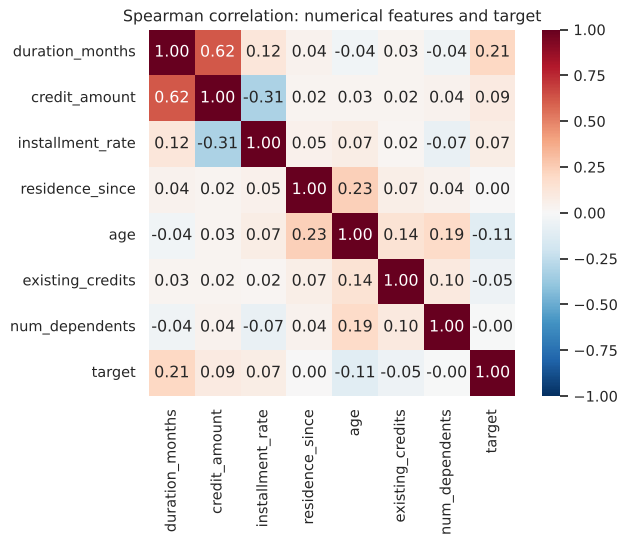

Cramér's V among key categoricals (redundancy check):


,checking_status,credit_history,savings_status,property,other_installment_plans,housing
checking_status,1.00,0.13,0.16,0.05,0.00,0.08
credit_history,0.13,1.00,0.03,0.05,0.21,0.07
savings_status,0.16,0.03,1.00,0.05,0.00,0.00
property,0.05,0.05,0.05,1.00,0.06,0.55
other_installment_plans,0.00,0.21,0.00,0.06,1.00,0.08
housing,0.08,0.07,0.00,0.55,0.08,1.00


In [11]:
# ---- 2.6 correlations among numerical features and with the target ------------------------------------------------------
cm = df[NUM + ["target"]].corr(method="spearman"); cm.to_csv(RES / "eda_spearman_matrix.csv")
print("Spearman(duration, credit_amount) = %.3f  (Pearson on logs %.3f)" % (cm.loc["duration_months", "credit_amount"], np.log(df.credit_amount).corr(np.log(df.duration_months))))
fig, ax = plt.subplots(figsize=(7, 5.6)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, square=True); ax.set_title("Spearman correlation: numerical features and target")
savefig("fig05_correlation_spearman.png")

keys = ["checking_status", "credit_history", "savings_status", "property", "other_installment_plans", "housing"]
V = pd.DataFrame(index=keys, columns=keys, dtype=float)
for i in keys:
    for j in keys:
        V.loc[i, j] = 1 if i == j else cramers_v(pd.crosstab(df[i], df[j]))
print("Cramér's V among key categoricals (redundancy check):"); display(V.round(2))

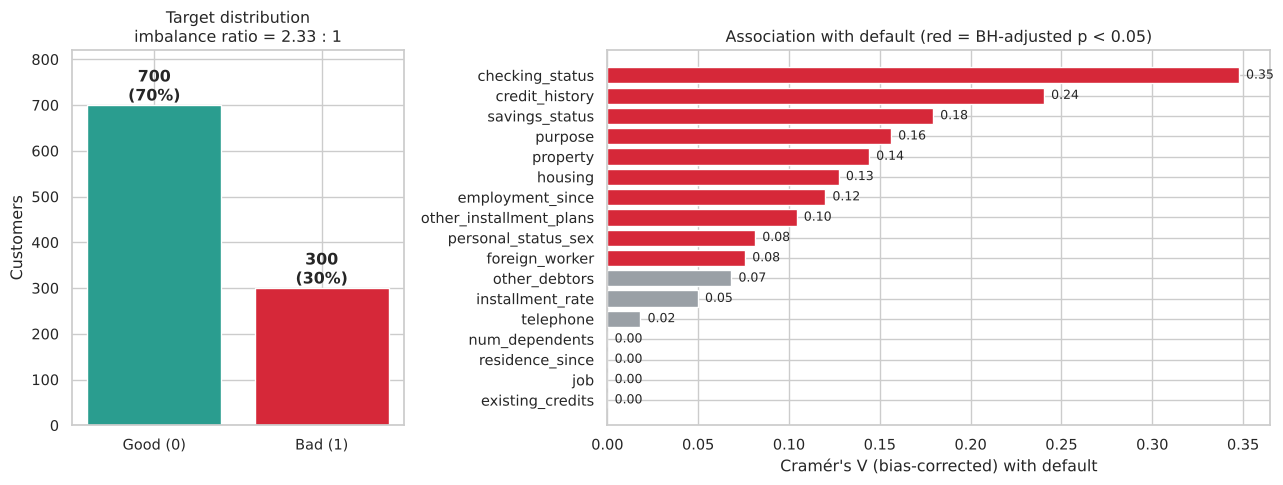

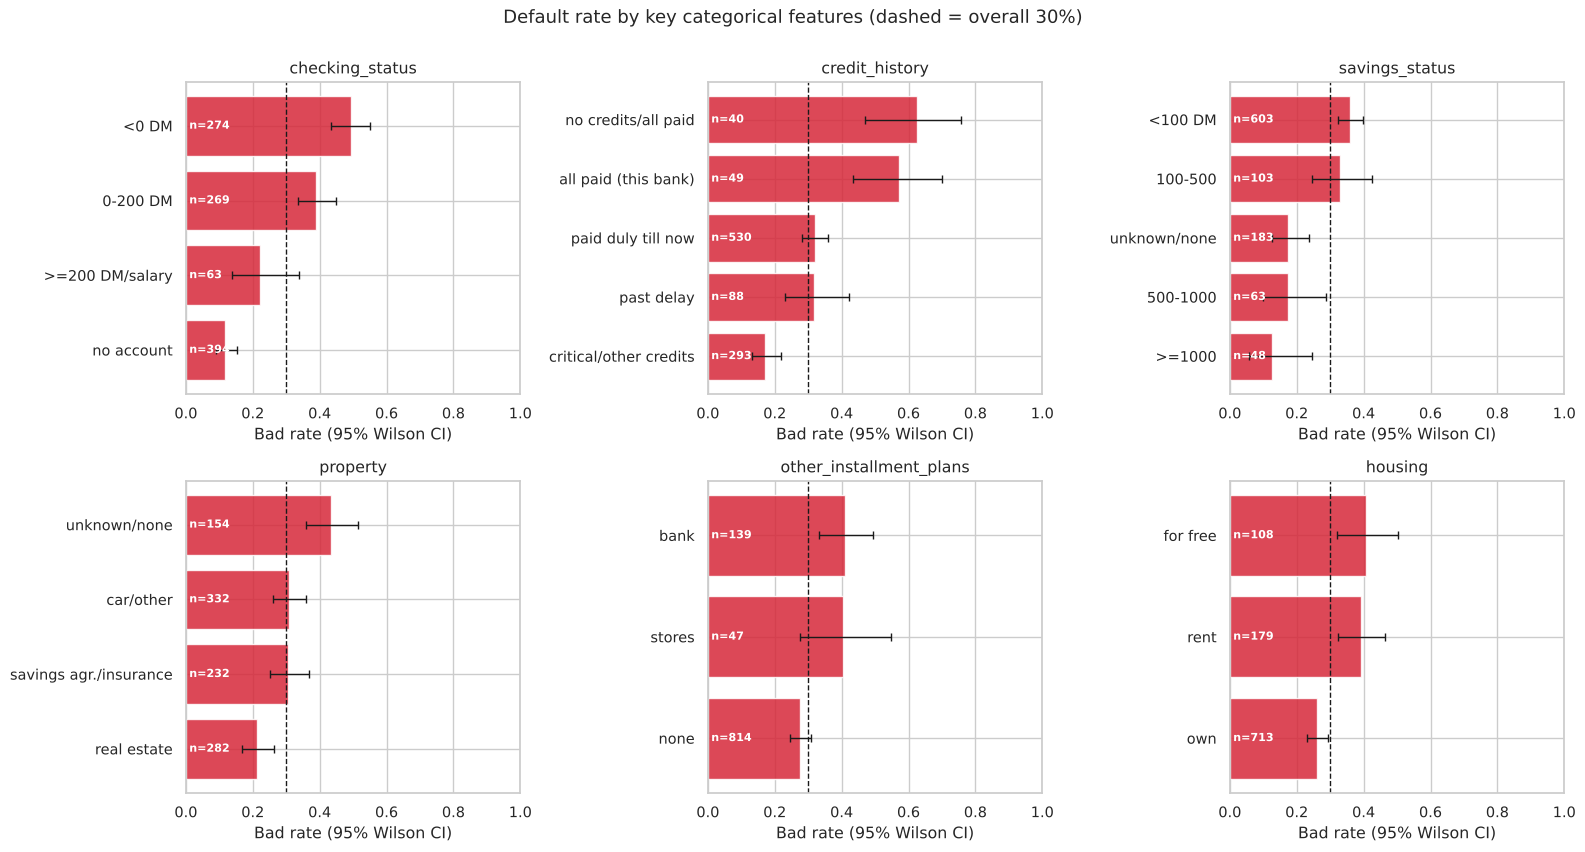

In [12]:
# ---- 2.7 FIGURE 1: target distribution + strength of association (key analytical chart) ----------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 2]})
cnt = df.target.value_counts().sort_index(); ax[0].bar(["Good (0)", "Bad (1)"], cnt.values, color=[GOOD_C, BAD_C])
for i, v in enumerate(cnt.values): ax[0].text(i, v + 10, f"{v}\n({v/10:.0f}%)", ha="center", fontweight="bold")
ax[0].set_ylim(0, 820); ax[0].set_ylabel("Customers"); ax[0].set_title("Target distribution\nimbalance ratio = %.2f : 1" % (n0 / n1))
a2 = assoc.sort_values("V_biascorr"); ax[1].barh(a2.feature, a2.V_biascorr, color=[BAD_C if q < 0.05 else "#9aa0a6" for q in a2.p_BH])
for i, v in enumerate(a2.V_biascorr): ax[1].text(v + 0.004, i, f"{v:.2f}", va="center", fontsize=9)
ax[1].set_xlabel("Cramér's V (bias-corrected) with default"); ax[1].set_title("Association with default (red = BH-adjusted p < 0.05)")
savefig("fig01_target_and_association.png")

# ---- FIGURE 2: bad rate by key categorical features (behaviour of bad customers) -----------------------------------------
fig, axs = plt.subplots(2, 3, figsize=(16, 8.5)); base = df.target.mean()
for ax, k in zip(axs.ravel(), keys):
    s = cat_profile[cat_profile.feature == k].sort_values("bad_rate")
    ax.barh(s.label, s.bad_rate, color=BAD_C, alpha=.85); ax.errorbar(s.bad_rate, range(len(s)), xerr=[s.bad_rate - s.ci_lo, s.ci_hi - s.bad_rate], fmt="none", ecolor="k", capsize=3, lw=1)
    for y_, n_ in enumerate(s.n): ax.text(0.01, y_, f"n={n_}", va="center", fontsize=8, color="white", fontweight="bold")
    ax.axvline(base, ls="--", c="k", lw=1); ax.set_xlim(0, 1); ax.set_title(k); ax.set_xlabel("Bad rate (95% Wilson CI)")
fig.suptitle("Default rate by key categorical features (dashed = overall 30%)", y=1.0, fontsize=13)
savefig("fig02_bad_rate_categorical.png")

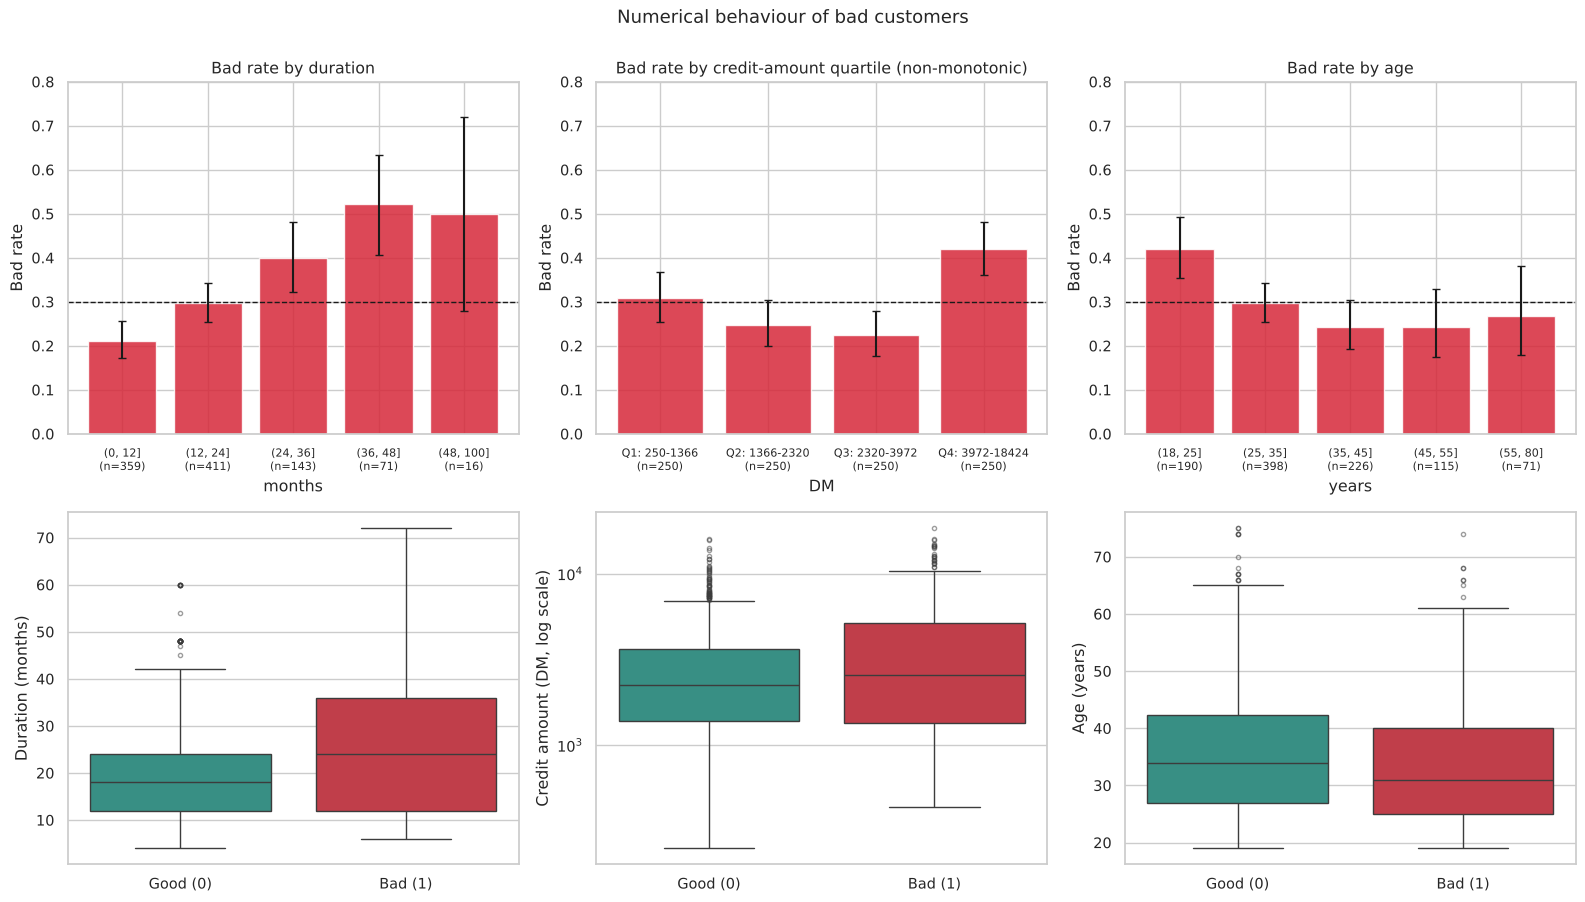

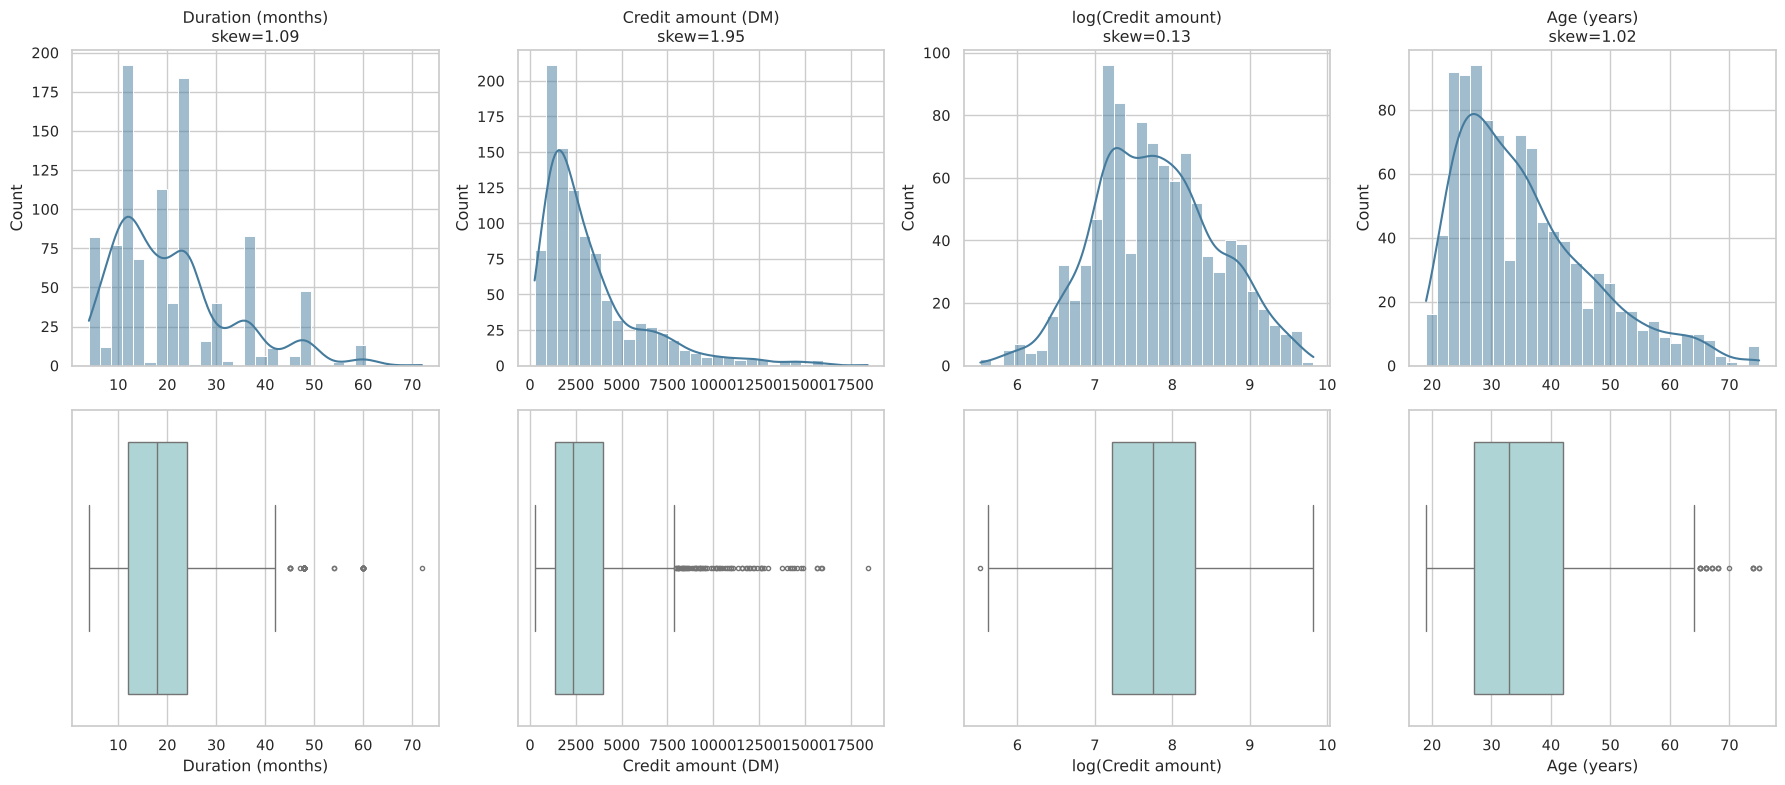

In [13]:
# ---- FIGURE 3: numerical behaviour of bad customers; FIGURE 4: distributions and outliers ------------------------------
def bin_rate(ax, s, title, xlabel):
    g = df.groupby(s, observed=True).target.agg(["count", "sum"]); g["r"] = g["sum"] / g["count"]; ci = np.array([wilson(k, n) for k, n in zip(g["sum"], g["count"])])
    ax.bar(range(len(g)), g.r, color=BAD_C, alpha=.85); ax.errorbar(range(len(g)), g.r, yerr=[g.r - ci[:, 0], ci[:, 1] - g.r], fmt="none", ecolor="k", capsize=3)
    ax.set_xticks(range(len(g))); ax.set_xticklabels([f"{i}\n(n={n})" for i, n in zip(g.index, g["count"])], fontsize=8)
    ax.axhline(base, ls="--", c="k", lw=1); ax.set_ylim(0, .8); ax.set_title(title); ax.set_ylabel("Bad rate"); ax.set_xlabel(xlabel)
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
bin_rate(axs[0, 0], pd.cut(df.duration_months, [0, 12, 24, 36, 48, 100]), "Bad rate by duration", "months")
q = pd.qcut(df.credit_amount, 4); labs = [f"Q{i+1}: {int(round(iv.left)) if i else 250}-{int(round(iv.right))}" for i, iv in enumerate(q.cat.categories)]
bin_rate(axs[0, 1], pd.Series(pd.Categorical.from_codes(q.cat.codes, categories=labs, ordered=True), index=df.index), "Bad rate by credit-amount quartile (non-monotonic)", "DM")
bin_rate(axs[0, 2], pd.cut(df.age, [18, 25, 35, 45, 55, 80]), "Bad rate by age", "years")
for ax, c, lab in [(axs[1, 0], "duration_months", "Duration (months)"), (axs[1, 1], "credit_amount", "Credit amount (DM, log scale)"), (axs[1, 2], "age", "Age (years)")]:
    sns.boxplot(data=df, x="target", y=c, hue="target", palette=[GOOD_C, BAD_C], ax=ax, legend=False, flierprops=dict(marker="o", ms=3, alpha=.5))
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Good (0)", "Bad (1)"]); ax.set_xlabel(""); ax.set_ylabel(lab)
    if c == "credit_amount": ax.set_yscale("log")
fig.suptitle("Numerical behaviour of bad customers", y=1.0, fontsize=13); savefig("fig03_bad_behaviour_numeric.png")
_rows = []
for nm, s_ in [("duration_months", pd.cut(df.duration_months, [0, 12, 24, 36, 48, 100])), ("credit_amount_quartile", pd.qcut(df.credit_amount, 4)), ("age", pd.cut(df.age, [18, 25, 35, 45, 55, 80]))]:
    g_ = df.groupby(s_, observed=True).target.agg(["count", "sum"])
    for idx, r_ in g_.iterrows(): _rows.append(dict(variable=nm, bin=str(idx), n=int(r_["count"]), n_bad=int(r_["sum"]), bad_rate=r_["sum"] / r_["count"]))
pd.DataFrame(_rows).to_csv(RES / "eda_bad_rate_by_bins.csv", index=False)

fig, axs = plt.subplots(2, 4, figsize=(18, 8))
for j, (c, lab, lg) in enumerate([("duration_months", "Duration (months)", False), ("credit_amount", "Credit amount (DM)", False), ("credit_amount", "log(Credit amount)", True), ("age", "Age (years)", False)]):
    x = np.log(df[c]) if lg else df[c]
    sns.histplot(x, bins=30, kde=True, color="#457b9d", ax=axs[0, j]); axs[0, j].set_title(f"{lab}\nskew={x.skew():.2f}"); axs[0, j].set_xlabel("")
    sns.boxplot(x=x, color="#a8dadc", ax=axs[1, j], flierprops=dict(marker="o", ms=3)); axs[1, j].set_xlabel(lab)
savefig("fig04_distributions_outliers.png")

**EDA reading guide (conclusions are drawn from the tables and figures above, nothing is removed or merged here):**
* The target is moderately imbalanced (≈ 2.3 : 1), so class weights and threshold tuning are preferred to resampling (tested later).
* Strongest raw associations: `checking_status`, `credit_history`, `savings_status`, then `purpose`, `property`, `housing`; among numerical features `duration_months` (and a non-monotonic effect of `credit_amount`, high in the top quartile).
* Some patterns are counter-intuitive and are **kept as observations, not explained away**: customers with *no checking account* and with *critical-account / other-credits* history show *low* default rates. These are examined again in Part 8 (causality).
* `credit_amount` and `duration_months` are strongly correlated, so their separate effects cannot be read independently.

---
# Part 3 — Train/Test split, leakage-free preprocessing, feature engineering and selection

**The split is the very first modelling step.** From here on every statistic that is *learned* from data (imputation values, scaling, rare-level pooling, one-hot vocabulary, feature rankings, thresholds, hyper-parameters) is learned on **training data only**; inside cross-validation it is re-learned on each training fold by wrapping all steps in a scikit-learn `Pipeline`.

In [14]:
# ---- 3.1 stratified 80/20 split with a fixed seed; the Test set is then left alone until Part 6 -----------------------
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
print(f"train {Xtr.shape} bad={int(ytr.sum())} ({ytr.mean():.3f}) | test {Xte.shape} bad={int(yte.sum())} ({yte.mean():.3f})")
assert len(set(Xtr.index) & set(Xte.index)) == 0 and len(set(Xtr.index) | set(Xte.index)) == 1000
RAW_FEATURES = NUM + CAT

train (800, 20) bad=240 (0.300) | test (200, 20) bad=60 (0.300)


In [15]:
# ---- 3.2 feature engineering transformer + preprocessors (all learned parts live inside Pipelines) -----------------------
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

ENGINEERED = ["credit_per_month", "financial_stability_score"]

class FinancialFeatures(BaseEstimator, TransformerMixin):
    """Stateless (learns nothing from data -> cannot leak). Adds two domain features built only from existing columns.
    credit_per_month          = credit_amount / duration_months   (average principal repaid per month, DM; excludes interest)
    financial_stability_score = sum of five binary signals (0..5):
        employment_since in {A74, A75} + housing == A152 (own) + property == A121 (real estate)
        + savings_status in {A63, A64} + checking_status == A13 (>=200 DM / salary assignment)
    'unknown' levels (A65, A124, A14) are deliberately counted neither as stability nor as instability."""
    def fit(self, X, y=None):
        self.feature_names_in_ = np.array(list(X.columns)); return self
    def transform(self, X):
        X = X.copy(); dur = X["duration_months"].where(X["duration_months"] > 0)        # guard against division by <= 0
        X["credit_per_month"] = X["credit_amount"] / dur
        X["financial_stability_score"] = (X["employment_since"].isin(["A74", "A75"]).astype(int) + (X["housing"] == "A152").astype(int)
            + (X["property"] == "A121").astype(int) + X["savings_status"].isin(["A63", "A64"]).astype(int) + (X["checking_status"] == "A13").astype(int))
        for c in CAT: X[c] = X[c].astype(object)
        return X
    def get_feature_names_out(self, input_features=None):
        fi = input_features if input_features is not None else getattr(self, "feature_names_in_", COLS[:-1])
        return np.array(list(fi) + ENGINEERED)

def _log1p(x): return np.log1p(x)

def build_preprocessor(kind="linear", min_freq=0.015, with_engineered=True, exclude=()):
    """kind='linear': impute + log1p(skewed amounts) + StandardScaler + one-hot   (Logistic Regression)
       kind='tree'  : impute + raw numerics (scale-invariant) + one-hot            (trees / boosting)
       Rare levels (< min_freq of the TRAINING fold) are pooled into one bucket. `exclude` removes inputs from the MODEL only."""
    eng = ENGINEERED if with_engineered is True else (list(with_engineered) if with_engineered else [])
    num = [c for c in NUM if c not in exclude] + eng; cat = [c for c in CAT if c not in exclude]
    ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq, sparse_output=False, drop="if_binary")
    cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", ohe)])
    if kind == "linear":
        logc = [c for c in ["credit_amount", "credit_per_month"] if c in num]; other = [c for c in num if c not in logc]
        tfs = [("log_num", Pipeline([("imp", SimpleImputer(strategy="median")), ("log", FunctionTransformer(_log1p, feature_names_out="one-to-one")), ("sc", StandardScaler())]), logc),
               ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), other), ("cat", cat_pipe, cat)]
    else:
        tfs = [("num", Pipeline([("imp", SimpleImputer(strategy="median"))]), num), ("cat", cat_pipe, cat)]
    ct = ColumnTransformer(tfs, remainder="drop", verbose_feature_names_out=False); ct.set_output(transform="pandas")
    return Pipeline([("fe", FinancialFeatures()), ("prep", ct)])

# ---- leakage unit tests: use two halves of TRAIN (Test is not touched) ------------------------------------------------------
A_idx, B_idx = train_test_split(np.arange(len(Xtr)), test_size=0.5, stratify=ytr, random_state=SEED)
XA, XB, yA = Xtr.iloc[A_idx], Xtr.iloc[B_idx], ytr.iloc[A_idx]
for kind in ["linear", "tree"]:
    pre = build_preprocessor(kind).fit(XA, yA); ct = pre.named_steps["prep"]
    get = (lambda: ct.named_transformers_["num"].named_steps["sc"].mean_.copy()) if kind == "linear" else (lambda: ct.named_transformers_["num"].named_steps["imp"].statistics_.copy())
    before = get(); ZA, ZB = pre.transform(XA), pre.transform(XB); after = get()
    print(f"[{kind}] fit-half {ZA.shape} -> other-half {ZB.shape} | NaN: {int(ZA.isna().sum().sum())}/{int(ZB.isna().sum().sum())} | fitted state unchanged by transform(other half): {np.allclose(before, after)}")
    if kind == "linear":
        sc = ct.named_transformers_["num"].named_steps["sc"]; FA = FinancialFeatures().transform(XA)
        cols_ = ["duration_months", "installment_rate", "residence_since", "age", "existing_credits", "num_dependents", "financial_stability_score"]
        print("   scaler means equal the fit-half means:", np.allclose(sc.mean_, FA[cols_].mean().values),
              "| fit-half standardised mean/std:", round(ZA["duration_months"].mean(), 6), round(ZA["duration_months"].std(ddof=0), 4),
              "| other half (not forced to 0/1):", round(ZB["duration_months"].mean(), 3), round(ZB["duration_months"].std(ddof=0), 3))
        ohe = ct.named_transformers_["cat"].named_steps["ohe"]; print("   rare levels pooled from the fit half:", {c: list(v) for c, v in zip(CAT, ohe.infrequent_categories_) if v is not None})
unseen = XB.head(3).copy(); unseen.loc[unseen.index[0], "purpose"] = "A47"
print("unseen category handled without error:", build_preprocessor("linear").fit(XA, yA).transform(unseen).shape)
print("missing values in the data:", int(X_all.isna().sum().sum()), "-> imputers (median / most-frequent) are fitted as a safeguard and are inactive here;",
      "'unknown / none' levels (A65, A124, A14) are kept as their own category because they carry signal.")

[linear] fit-half (400, 59) -> other-half (400, 59) | NaN: 0/0 | fitted state unchanged by transform(other half): True
   scaler means equal the fit-half means: True | fit-half standardised mean/std: 0.0 1.0 | other half (not forced to 0/1): -0.086 0.961
   rare levels pooled from the fit half: {'purpose': ['A410', 'A44', 'A48']}
[tree] fit-half (400, 59) -> other-half (400, 59) | NaN: 0/0 | fitted state unchanged by transform(other half): True
unseen category handled without error: (3, 59)
missing values in the data: 0 -> imputers (median / most-frequent) are fitted as a safeguard and are inactive here; 'unknown / none' levels (A65, A124, A14) are kept as their own category because they carry signal.


### 3.3 Candidate financial features — evaluated on TRAIN only

Two features are proposed (formulas, inputs and rationale are documented in the `FinancialFeatures` docstring above): **`credit_per_month`** (average monthly principal) and **`financial_stability_score`** (count of five stability signals). Debt-to-income and credit-utilisation ratios are **not** built because income and credit limits do not exist in the data. A "credit burden" `credit_amount × installment_rate` and a hand-made "credit-history risk category" were examined and **rejected** (see the evidence below).

A) 'credit burden' = credit_amount x installment_rate
  Spearman(installment_rate, credit_per_month) = -0.527 | (installment_rate, credit_amount) = -0.309
  -> the 1-4 codes move AGAINST the monthly payment, which hints that the code direction may be reversed; the product has no coherent unit (D6 stays unresolved)


  LR CV AUC without burden 0.6227 | with burden 0.6214 | paired diff -0.0013 (sd 0.0031; improved in 10/25 folds) -> REJECTED

B) credit_per_month: univariate AUC 0.434 (duration 0.629, amount 0.548)


,count,mean
q,,
"(24.055, 86.396]",200,0.40
"(86.396, 128.361]",200,0.28
"(128.361, 205.854]",200,0.26
"(205.854, 1126.833]",200,0.26


C) financial_stability_score: univariate AUC (higher score -> lower risk) 0.649


,count,sum,mean
s,,,
0,82,38,0.463
1,299,121,0.405
2,291,63,0.216
3,112,15,0.134
4,15,2,0.133
5,1,1,1.000



D) incremental value in a full Logistic Regression (paired repeated CV on TRAIN)
  20 raw features: AUC 0.7714


  +credit_per_month            AUC 0.7738 | paired diff +0.0024 (sd 0.0035; improved 21/25)


  +financial_stability_score   AUC 0.7713 | paired diff -0.0001 (sd 0.0011; improved 13/25)


  +both                        AUC 0.7736 | paired diff +0.0022 (sd 0.0034; improved 20/25)
Both features are kept (documented, interpretable); their predictive gain is small and is NOT claimed to be large.


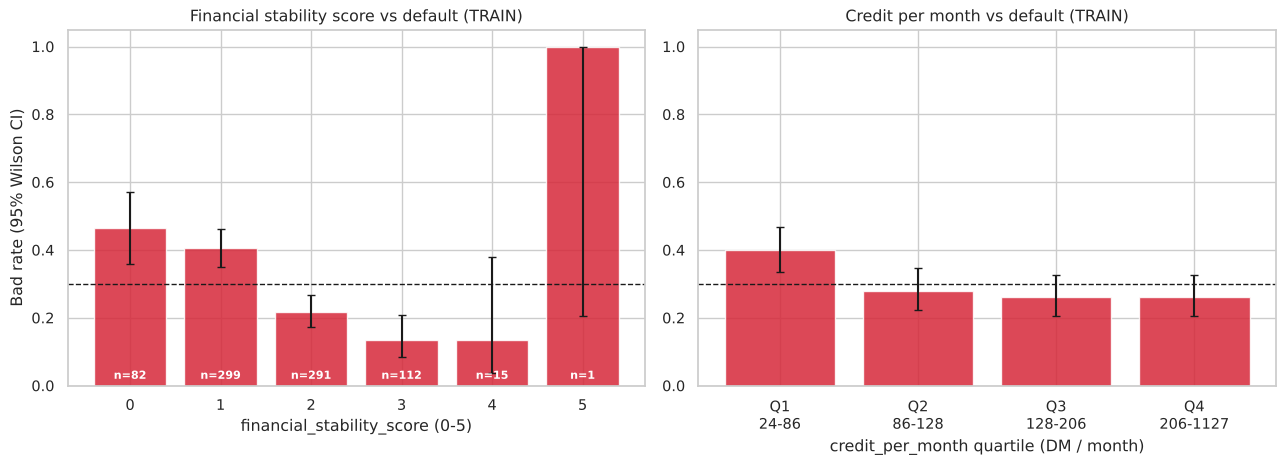

In [16]:
# ---- 3.3 evaluation of candidate features (TRAIN only) --------------------------------------------------------------------
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
Ftr = FinancialFeatures().transform(Xtr); n_rep = 1 if FAST else 5
cv55 = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_rep, random_state=SEED)
print("A) 'credit burden' = credit_amount x installment_rate")
print("  Spearman(installment_rate, credit_per_month) = %.3f | (installment_rate, credit_amount) = %.3f" % (stats.spearmanr(Xtr.installment_rate, Ftr.credit_per_month)[0], stats.spearmanr(Xtr.installment_rate, Xtr.credit_amount)[0]))
print("  -> the 1-4 codes move AGAINST the monthly payment, which hints that the code direction may be reversed; the product has no coherent unit (D6 stays unresolved)")
burden = Xtr.credit_amount * Xtr.installment_rate
def lr_cv(extra):
    Z = Xtr[["duration_months", "installment_rate"]].astype(float).copy()
    for k, v in extra.items(): Z[k] = v
    p = Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(max_iter=2000))]); return cross_val_score(p, Z, ytr, cv=cv55, scoring="roc_auc")
b0 = lr_cv({"log_amount": np.log(Xtr.credit_amount)}); b1 = lr_cv({"log_amount": np.log(Xtr.credit_amount), "log_burden": np.log(burden)}); d = b1 - b0
print(f"  LR CV AUC without burden {b0.mean():.4f} | with burden {b1.mean():.4f} | paired diff {d.mean():+.4f} (sd {d.std():.4f}; improved in {int((d > 0).sum())}/{len(d)} folds) -> REJECTED")

cpm, S_ = Ftr.credit_per_month, Ftr.financial_stability_score
print("\nB) credit_per_month: univariate AUC %.3f (duration %.3f, amount %.3f)" % (roc_auc_score(ytr, cpm), roc_auc_score(ytr, Xtr.duration_months), roc_auc_score(ytr, Xtr.credit_amount)))
display(pd.DataFrame({"q": pd.qcut(cpm, 4), "y": ytr}).groupby("q", observed=True).y.agg(["count", "mean"]).round(3))
print("C) financial_stability_score: univariate AUC (higher score -> lower risk) %.3f" % roc_auc_score(ytr, -S_))
g = pd.DataFrame({"s": S_, "y": ytr}).groupby("s").y.agg(["count", "sum", "mean"]); display(g.round(3))

def full_cv(eng):
    p = Pipeline(build_preprocessor("linear", with_engineered=eng).steps + [("clf", LogisticRegression(max_iter=3000, C=1.0))]); return cross_val_score(p, Xtr, ytr, cv=cv55, scoring="roc_auc")
base = full_cv([]); print("\nD) incremental value in a full Logistic Regression (paired repeated CV on TRAIN)"); print(f"  20 raw features: AUC {base.mean():.4f}")
for name, eng in [("+credit_per_month", ["credit_per_month"]), ("+financial_stability_score", ["financial_stability_score"]), ("+both", ENGINEERED)]:
    r = full_cv(eng); dd = r - base; print(f"  {name:28s} AUC {r.mean():.4f} | paired diff {dd.mean():+.4f} (sd {dd.std():.4f}; improved {int((dd > 0).sum())}/{len(dd)})")
print("Both features are kept (documented, interpretable); their predictive gain is small and is NOT claimed to be large.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8)); base_rate = ytr.mean()
gg = g.copy(); gg["r"] = gg["sum"] / gg["count"]; ci = np.array([wilson(k, n_) for k, n_ in zip(gg["sum"], gg["count"])])
ax[0].bar(gg.index.astype(str), gg.r, color=BAD_C, alpha=.85); ax[0].errorbar(range(len(gg)), gg.r, yerr=[gg.r - ci[:, 0], ci[:, 1] - gg.r], fmt="none", ecolor="k", capsize=3)
for i, n_ in enumerate(gg["count"]): ax[0].text(i, .02, f"n={n_}", ha="center", color="white", fontsize=8, fontweight="bold")
ax[0].axhline(base_rate, ls="--", c="k", lw=1); ax[0].set_ylim(0, 1.05); ax[0].set_xlabel("financial_stability_score (0-5)"); ax[0].set_ylabel("Bad rate (95% Wilson CI)"); ax[0].set_title("Financial stability score vs default (TRAIN)")
qq = pd.qcut(cpm, 4); labs = [f"Q{i+1}\n{iv.left:.0f}-{iv.right:.0f}" for i, iv in enumerate(qq.cat.categories)]
g2 = pd.DataFrame({"q": qq, "y": ytr}).groupby("q", observed=True).y.agg(["count", "sum"]); g2["r"] = g2["sum"] / g2["count"]; ci2 = np.array([wilson(k, n_) for k, n_ in zip(g2["sum"], g2["count"])])
ax[1].bar(range(4), g2.r, color=BAD_C, alpha=.85); ax[1].errorbar(range(4), g2.r, yerr=[g2.r - ci2[:, 0], ci2[:, 1] - g2.r], fmt="none", ecolor="k", capsize=3)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(labs); ax[1].axhline(base_rate, ls="--", c="k", lw=1); ax[1].set_ylim(0, 1.05); ax[1].set_xlabel("credit_per_month quartile (DM / month)"); ax[1].set_title("Credit per month vs default (TRAIN)")
savefig("fig06_engineered_features.png")

### 3.4 Feature selection — three features with the strongest, non-redundant discriminating power (TRAIN only)

Four complementary criteria: (a) out-of-fold AUC of a *single-feature* shallow tree (handles non-monotone effects and categoricals), (b) mutual information, (c) a Benjamini–Hochberg-adjusted test, (d) grouped *permutation importance* computed out-of-fold for two model families (Random Forest and Logistic Regression). Rankings are aggregated and checked for redundancy and for credit-domain meaning.

[cache] loaded 'perm_rf'
[cache] loaded 'perm_lr'


,oofAUC_1feat,MI,p_BH,PI_RF,PI_LR,mean_rank,top3_folds_RF,top3_folds_LR
checking_status,0.6990,0.0608,0.0000,0.1069,0.0723,1.00,5,5
financial_stability_score,0.6494,0.0353,0.0000,0.0134,0.0179,3.25,1,1
credit_history,0.6152,0.0273,0.0000,0.0112,0.0219,4.50,0,1
savings_status,0.5959,0.0223,0.0000,0.0146,0.0135,5.25,3,1
credit_amount,0.5564,0.0345,0.0463,0.0086,0.0466,6.00,0,5
duration_months,0.6260,0.0269,0.0000,0.0219,0.0043,6.00,4,0
credit_per_month,0.5524,0.0298,0.0060,0.0116,0.0191,6.50,0,1
purpose,0.5875,0.0159,0.0059,0.0022,0.0128,7.75,0,1
property,0.5828,0.0153,0.0001,0.0035,0.0060,9.00,0,0
other_installment_plans,0.5543,0.0097,0.0008,0.0092,0.0089,9.50,2,0


association among the top-8 (Cramér's V; continuous binned in quintiles):


,checking_status,financial_stability_score,credit_history,savings_status,credit_amount,duration_months,credit_per_month,purpose
checking_status,1.00,0.19,0.11,0.17,0.08,0.05,0.05,0.13
financial_stability_score,0.19,1.00,0.08,0.24,0.11,0.06,0.05,0.10
credit_history,0.11,0.08,1.00,0.02,0.08,0.08,0.02,0.15
savings_status,0.17,0.24,0.02,1.00,0.06,0.04,0.00,0.06
credit_amount,0.08,0.11,0.08,0.06,1.00,0.33,0.35,0.21
duration_months,0.05,0.06,0.08,0.04,0.33,1.00,0.07,0.13
credit_per_month,0.05,0.05,0.02,0.00,0.35,0.07,1.00,0.15
purpose,0.13,0.10,0.15,0.06,0.21,0.13,0.15,1.00


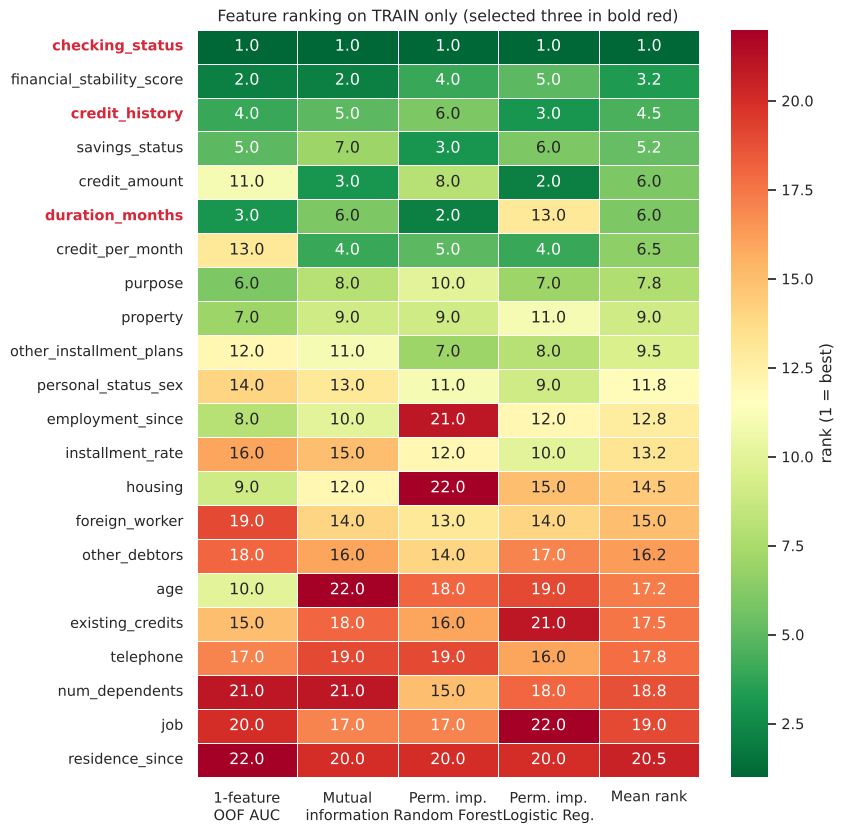

In [17]:
# ---- 3.4 feature selection ------------------------------------------------------------------------------------------------
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_classif
CANDS = RAW_FEATURES + ENGINEERED; NUMC = NUM + ENGINEERED; CONT = ["duration_months", "credit_amount", "age", "credit_per_month"]
cvr = RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if FAST else 3, random_state=SEED)
def single_oof_auc(col):
    pre = ColumnTransformer([("n", "passthrough", [col])]) if col in NUMC else ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), [col])])
    aucs = []
    for a, b in cvr.split(Ftr, ytr):
        p = Pipeline([("p", pre), ("t", DecisionTreeClassifier(max_depth=3, min_samples_leaf=25, random_state=SEED))]).fit(Ftr.iloc[a], ytr.iloc[a])
        aucs.append(roc_auc_score(ytr.iloc[b], p.predict_proba(Ftr.iloc[b])[:, 1]))
    return np.mean(aucs)
oof1 = pd.Series({c: single_oof_auc(c) for c in CANDS})
Xmi = Ftr[CANDS].copy()
for c in CAT: Xmi[c] = Xmi[c].astype("category").cat.codes
mi = pd.Series(mutual_info_classif(Xmi, ytr, discrete_features=[c not in CONT for c in CANDS], n_neighbors=5, random_state=SEED), index=CANDS)
pv = pd.Series({c: (stats.mannwhitneyu(Ftr.loc[ytr == 1, c], Ftr.loc[ytr == 0, c]).pvalue if c in CONT else stats.chi2_contingency(pd.crosstab(Ftr[c], ytr), correction=False)[1]) for c in CANDS})
p_bh = pd.Series(multipletests(pv, method="fdr_bh")[1], index=pv.index)

def perm_imp(kind):
    pre = build_preprocessor(kind).named_steps["prep"]
    clf = (RandomForestClassifier(n_estimators=60 if FAST else 300, min_samples_leaf=5, max_features="sqrt", class_weight="balanced_subsample", random_state=SEED, n_jobs=1)
           if kind == "tree" else LogisticRegression(max_iter=3000, C=0.3, class_weight="balanced"))
    cols_ = []
    for k, (a, b) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Ftr, ytr)):
        m = clone(Pipeline([("prep", pre), ("clf", clf)])).fit(Ftr.iloc[a], ytr.iloc[a])
        r = permutation_importance(m, Ftr.iloc[b][CANDS], ytr.iloc[b], scoring="roc_auc", n_repeats=2 if FAST else 10, random_state=SEED)
        cols_.append(pd.Series(r.importances_mean, index=CANDS))
    return pd.concat(cols_, axis=1)
pi_rf, pi_lr = cached("perm_rf", lambda: perm_imp("tree")), cached("perm_lr", lambda: perm_imp("linear"))
SEL = pd.DataFrame({"oofAUC_1feat": oof1, "MI": mi, "p_BH": p_bh, "PI_RF": pi_rf.mean(1), "PI_LR": pi_lr.mean(1)})
for c in ["oofAUC_1feat", "MI", "PI_RF", "PI_LR"]: SEL["rk_" + c] = SEL[c].rank(ascending=False)
SEL["mean_rank"] = SEL[[c for c in SEL if c.startswith("rk_")]].mean(1)
SEL["top3_folds_RF"] = (pi_rf.rank(ascending=False) <= 3).sum(1); SEL["top3_folds_LR"] = (pi_lr.rank(ascending=False) <= 3).sum(1)
SEL = SEL.sort_values("mean_rank"); SEL.to_csv(RES / "feature_selection_table.csv"); display(SEL[["oofAUC_1feat", "MI", "p_BH", "PI_RF", "PI_LR", "mean_rank", "top3_folds_RF", "top3_folds_LR"]].round(4))

top = list(SEL.index[:8]); Fb = Ftr.copy()
for c in CONT: Fb[c] = pd.qcut(Fb[c], 5, duplicates="drop").astype(str)
R_ = pd.DataFrame(index=top, columns=top, dtype=float)
for i in top:
    for j in top: R_.loc[i, j] = 1 if i == j else cramers_v(pd.crosstab(Fb[i], Fb[j]))
print("association among the top-8 (Cramér's V; continuous binned in quintiles):"); display(R_.round(2))

RK = SEL[["rk_oofAUC_1feat", "rk_MI", "rk_PI_RF", "rk_PI_LR", "mean_rank"]].rename(columns={"rk_oofAUC_1feat": "1-feature\nOOF AUC", "rk_MI": "Mutual\ninformation", "rk_PI_RF": "Perm. imp.\nRandom Forest", "rk_PI_LR": "Perm. imp.\nLogistic Reg.", "mean_rank": "Mean rank"})
KEY3 = ["checking_status", "duration_months", "credit_history"]
fig, ax = plt.subplots(figsize=(8.5, 8.5)); sns.heatmap(RK, annot=True, fmt=".1f", cmap="RdYlGn_r", cbar_kws={"label": "rank (1 = best)"}, ax=ax, linewidths=.5)
for lab in ax.get_yticklabels():
    if lab.get_text() in KEY3: lab.set_fontweight("bold"); lab.set_color(BAD_C)
ax.set_title("Feature ranking on TRAIN only (selected three in bold red)"); savefig("fig07_feature_selection_ranks.png")

**Selected key features and why** (statements are tied to the table above):
* **`checking_status`** — first on all four criteria; liquidity / banking-relationship signal.
* **`duration_months`** — the best continuous feature and highly ranked by the Random Forest; describes the loan structure (exposure time).
* **`credit_history`** — strong single-feature and mutual-information signal; repayment behaviour. **Honest caveat:** model-based evidence for this third pick is weaker than for the first two; `savings_status` and `credit_amount` are reasonable alternatives (ranks 3–7 are not statistically separable at n = 800).
* `financial_stability_score` ranks high but is a *composite of other columns*, so it is not counted as an independent key feature. These three come from three different information sources (current finances, loan structure, past behaviour) and are weakly associated with each other (see the V matrix).

---
# Part 4 — Protected-type inputs: sensitivity check and exclusion decision

`personal_status_sex` (sex and marital status mixed in one attribute), `age` and `foreign_worker` (a national-origin proxy) are *protected-type* characteristics. Several jurisdictions restrict their direct use in credit decisions (to be confirmed with Compliance — this notebook is not legal advice). The check below measures what excluding them would cost in predictive power; **the exclusion decision itself is fairness-motivated**. The columns stay in the data for the later fairness audit but are **never inputs of the final models**.

In [18]:
# ---- 4.1 cost of excluding protected-type inputs (TRAIN, repeated paired CV, Logistic Regression) -----------------------------------
SENSITIVE = ["personal_status_sex", "age", "foreign_worker"]
def lr_pipe(exclude): return Pipeline(build_preprocessor("linear", exclude=exclude).steps + [("clf", LogisticRegression(C=0.03, penalty="l2", class_weight="balanced", solver="liblinear", max_iter=5000))])
cv_s = RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if FAST else 5, random_state=SEED)
b_auc = cross_val_score(lr_pipe([]), Xtr, ytr, cv=cv_s, scoring="roc_auc"); b_pr = cross_val_score(lr_pipe([]), Xtr, ytr, cv=cv_s, scoring="average_precision")
rows = [dict(variant="full model", AUC=b_auc.mean(), PR_AUC=b_pr.mean(), paired_AUC_diff=0.0, sd=0.0, worse_in_folds="-")]
for lab, drop in [("without personal_status_sex", ["personal_status_sex"]), ("without age", ["age"]), ("without foreign_worker", ["foreign_worker"]), ("without all three", SENSITIVE)]:
    a_ = cross_val_score(lr_pipe(drop), Xtr, ytr, cv=cv_s, scoring="roc_auc"); p_ = cross_val_score(lr_pipe(drop), Xtr, ytr, cv=cv_s, scoring="average_precision"); dd = a_ - b_auc
    rows.append(dict(variant=lab, AUC=a_.mean(), PR_AUC=p_.mean(), paired_AUC_diff=dd.mean(), sd=dd.std(), worse_in_folds=f"{int((dd < 0).sum())}/{len(dd)}"))
sens = pd.DataFrame(rows).set_index("variant"); display(sens.round(4)); sens.to_csv(RES / "protected_inputs_sensitivity.csv")
EXCLUDE = list(SENSITIVE)
print("\nDECISION: EXCLUDE =", EXCLUDE, "from every model input (they remain in the data for the fairness audit).")
print("Cost of exclusion in AUC (all three): %+.4f, versus fold-to-fold paired sd %.4f" % (sens.loc["without all three", "paired_AUC_diff"], sens.loc["without all three", "sd"]))

,AUC,PR_AUC,paired_AUC_diff,sd,worse_in_folds
variant,,,,,
full model,0.7781,0.6047,0.0000,0.0000,-
without personal_status_sex,0.7752,0.5956,-0.0030,0.0047,20/25
without age,0.7785,0.6049,0.0004,0.0015,12/25
without foreign_worker,0.7776,0.6034,-0.0005,0.0008,19/25
without all three,0.7756,0.5980,-0.0026,0.0047,18/25



DECISION: EXCLUDE = ['personal_status_sex', 'age', 'foreign_worker'] from every model input (they remain in the data for the fairness audit).
Cost of exclusion in AUC (all three): -0.0026, versus fold-to-fold paired sd 0.0047


---
# Part 5 — Modeling

* **Baseline**: depth-limited Decision Tree (simple, interpretable).  **Benchmark**: Logistic Regression.  **Challengers**: Random Forest and XGBoost.
* **Cross-validation**: Stratified 5-fold; **all tuning on the training set only** (`GridSearchCV` for the small grids, `RandomizedSearchCV` for the large ones).
* **Selection optimism** is quantified with **nested CV** (tuning is repeated inside every outer-training fold).
* **Imbalance** (≈ 30 % Bad): class weights, threshold adjustment (Part 6) and — only as an experiment — SMOTE / under-sampling, always **inside** the pipeline and only on training folds.
* The search spaces, seeds and folds are fixed; the Test set is not used anywhere in this Part.

In [19]:
# ---- 5.1 model zoo and search spaces --------------------------------------------------------------------------------------------
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve
from xgboost import XGBClassifier
MODELS = ["DT", "LR", "RF", "XGB"]
FULLNAME = {"DT": "Decision Tree", "LR": "Logistic Regression", "RF": "Random Forest", "XGB": "XGBoost"}
SIMPLE = {"DT": 1, "LR": 2, "RF": 3, "XGB": 3}                    # interpretability / simplicity order used by the selection rule
COLOR = {"DT": "#8d99ae", "LR": "#2a9d8f", "RF": "#e76f51", "XGB": "#264653"}

def make_pipe(kind, est):
    """Full pipeline: feature engineering -> preprocessing (protected-type inputs excluded) -> estimator."""
    return Pipeline(build_preprocessor(kind, exclude=EXCLUDE).steps + [("clf", est)])

n_rf, n_xgb = (3, 3) if FAST else (30, 40)
SPACES = {
 "DT": dict(kind="tree", search="grid", est=lambda: DecisionTreeClassifier(random_state=SEED),
            params={"clf__max_depth": [2, 3, 4, 5], "clf__min_samples_leaf": [10, 20, 40], "clf__ccp_alpha": [0.0, 0.005, 0.01], "clf__class_weight": [None, "balanced"]}),
 "LR": dict(kind="linear", search="grid", est=lambda: LogisticRegression(max_iter=5000, solver="liblinear", random_state=SEED),
            params={"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "clf__penalty": ["l1", "l2"], "clf__class_weight": [None, "balanced"]}),
 "RF": dict(kind="tree", search="random", n_iter=n_rf, est=lambda: RandomForestClassifier(n_jobs=1, random_state=SEED),
            params={"clf__n_estimators": [200, 300], "clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": [1, 3, 5, 10, 20],
                    "clf__max_features": ["sqrt", 0.3, 0.5], "clf__class_weight": [None, "balanced", "balanced_subsample"]}),
 "XGB": dict(kind="tree", search="random", n_iter=n_xgb, est=lambda: XGBClassifier(n_jobs=1, random_state=SEED, verbosity=0, eval_metric="logloss"),
            params={"clf__n_estimators": [100, 200, 300], "clf__learning_rate": [0.01, 0.03, 0.05, 0.1], "clf__max_depth": [2, 3, 4], "clf__min_child_weight": [1, 3, 5],
                    "clf__subsample": [0.6, 0.8, 1.0], "clf__colsample_bytree": [0.5, 0.7, 1.0], "clf__reg_lambda": [1, 5, 10], "clf__scale_pos_weight": [1.0, 2.33]})}
SC = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "neg_brier": "neg_brier_score"}
inner = lambda: StratifiedKFold(5, shuffle=True, random_state=SEED)                        # inner (tuning) folds
outer = StratifiedKFold(5, shuffle=True, random_state=SEED + 1)                            # outer folds (different split) for nested CV

def searcher(m):
    cfg = SPACES[m]; pipe = make_pipe(cfg["kind"], cfg["est"]())
    if cfg["search"] == "grid":
        return GridSearchCV(pipe, cfg["params"], scoring=SC, refit="roc_auc", cv=inner(), n_jobs=1)
    return RandomizedSearchCV(pipe, cfg["params"], n_iter=cfg["n_iter"], scoring=SC, refit="roc_auc", cv=inner(), n_jobs=1, random_state=SEED)
clean = lambda d: {k.replace("clf__", ""): (v.item() if hasattr(v, "item") else v) for k, v in d.items()}
print({m: (SPACES[m]["search"], SPACES[m].get("n_iter", "full grid")) for m in MODELS})

{'DT': ('grid', 'full grid'), 'LR': ('grid', 'full grid'), 'RF': ('random', 30), 'XGB': ('random', 40)}


In [20]:
# ---- 5.2 hyper-parameter tuning on the FULL TRAIN set (inner stratified 5-fold CV) -----------------------------------------------------------------
def _tune_one(m):
    s = searcher(m).fit(Xtr, ytr); i = s.best_index_; r = pd.DataFrame(s.cv_results_)
    row = dict(model=m, candidates=len(r), cv_auc=r.mean_test_roc_auc[i], cv_auc_sd=r.std_test_roc_auc[i], cv_prauc=r.mean_test_pr_auc[i], cv_prauc_sd=r.std_test_pr_auc[i], cv_brier=-r.mean_test_neg_brier[i])
    return s.best_estimator_, clean(s.best_params_), r, row                 # best_estimator_ is refit on the whole Train set
t0 = time.time(); FINAL, BEST, CVRES, rows = {}, {}, {}, []
for m in MODELS:
    FINAL[m], BEST[m], CVRES[m], row = cached(f"tune_{m}", lambda m=m: _tune_one(m)); rows.append(row)
    print(f"{FULLNAME[m]:20s} best CV AUC {row['cv_auc']:.4f} (sd {row['cv_auc_sd']:.4f}) | PR-AUC {row['cv_prauc']:.4f} | {BEST[m]} | {time.time()-t0:.0f}s")
TUNED = pd.DataFrame(rows).set_index("model"); TUNED.to_csv(RES / "tuned_cv_summary.csv"); json.dump(BEST, open(RES / "best_params.json", "w"), indent=1, default=str)
display(TUNED.round(4))

[cache] loaded 'tune_DT'
Decision Tree        best CV AUC 0.7606 (sd 0.0448) | PR-AUC 0.5180 | {'ccp_alpha': 0.0, 'class_weight': 'balanced', 'max_depth': 4, 'min_samples_leaf': 40} | 0s
[cache] loaded 'tune_LR'


Logistic Regression  best CV AUC 0.7770 (sd 0.0495) | PR-AUC 0.5978 | {'C': 0.03, 'class_weight': None, 'penalty': 'l2'} | 0s


Random Forest        best CV AUC 0.7971 (sd 0.0458) | PR-AUC 0.6404 | {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 8, 'class_weight': 'balanced'} | 94s


XGBoost              best CV AUC 0.7989 (sd 0.0396) | PR-AUC 0.6208 | {'subsample': 1.0, 'scale_pos_weight': 2.33, 'reg_lambda': 5, 'n_estimators': 100, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.5} | 119s


,candidates,cv_auc,cv_auc_sd,cv_prauc,cv_prauc_sd,cv_brier
model,,,,,,
DT,72,0.7606,0.0448,0.5180,0.0494,0.1988
LR,28,0.7770,0.0495,0.5978,0.0713,0.1701
RF,30,0.7971,0.0458,0.6404,0.0756,0.1727
XGB,40,0.7989,0.0396,0.6208,0.0567,0.1772


In [21]:
# ---- 5.3 NESTED CV: tuning repeated inside each outer-training fold; the outer fold only scores ----------------------------------
def _nested_fold(k, tri, vai):
    out_ = []
    for m in MODELS:
        s = searcher(m).fit(Xtr.iloc[tri], ytr.iloc[tri]); p = s.predict_proba(Xtr.iloc[vai])[:, 1]; yb = ytr.iloc[vai]
        out_.append(dict(fold=k, model=m, auc=roc_auc_score(yb, p), prauc=average_precision_score(yb, p), brier=brier_score_loss(yb, p), inner_best_auc=s.best_score_, params=str(clean(s.best_params_))))
    return out_
t0 = time.time(); rows = []
for k, (tri, vai) in enumerate(outer.split(Xtr, ytr)):
    rows += cached(f"nested_fold{k}", lambda k=k, tri=tri, vai=vai: _nested_fold(k, tri, vai))
    print(f"outer fold {k} done | {time.time()-t0:.0f}s")
NEST = pd.DataFrame(rows); NEST.to_csv(RES / "nested_cv_folds.csv", index=False)
nest_sum = NEST.groupby("model")[["auc", "prauc", "brier", "inner_best_auc"]].agg(["mean", "std"]).loc[MODELS]; display(nest_sum.round(4))
opt = NEST.groupby("model").agg(nested_outer_auc=("auc", "mean"), inner_best_auc=("inner_best_auc", "mean")).loc[MODELS]
opt["optimism_inner_minus_outer"] = opt.inner_best_auc - opt.nested_outer_auc; opt["tuned_on_full_train_cv_auc"] = TUNED.cv_auc; display(opt.round(4))
P_ = NEST.pivot(index="fold", columns="model", values="auc")[MODELS]
print("paired outer-fold AUC differences (5 folds -> low power):")
for a, b in [("RF", "DT"), ("XGB", "DT"), ("LR", "DT"), ("RF", "LR"), ("XGB", "LR"), ("RF", "XGB")]:
    d = P_[a] - P_[b]; print(f"  {a:3s} - {b:3s}: {d.mean():+.4f} (sd {d.std():.4f}); better in {int((d > 0).sum())}/5 folds; paired-t p = {stats.ttest_rel(P_[a], P_[b]).pvalue:.3f}")
cw = NEST.assign(cw=NEST.params.apply(lambda s: eval(s).get("class_weight", eval(s).get("scale_pos_weight")))).pivot(index="fold", columns="model", values="cw")[MODELS]
print("\nclass-weight / scale_pos_weight chosen in each outer fold (instability -> probabilities of different folds are not on a common scale):"); display(cw)

outer fold 0 done | 129s


outer fold 1 done | 260s


outer fold 2 done | 385s


outer fold 3 done | 512s


outer fold 4 done | 644s


auc           prauc           brier         inner_best_auc        
         mean     std    mean     std    mean     std           mean     std
model                                                                       
DT     0.7436  0.0445  0.5035  0.0589  0.2073  0.0146         0.7497  0.0178
LR     0.7726  0.0625  0.5849  0.0838  0.1739  0.0175         0.7743  0.0163
RF     0.7953  0.0533  0.6331  0.0862  0.1711  0.0130         0.7953  0.0208
XGB    0.7849  0.0556  0.6038  0.0928  0.1865  0.0242         0.7936  0.0181

,nested_outer_auc,inner_best_auc,optimism_inner_minus_outer,tuned_on_full_train_cv_auc
model,,,,
DT,0.7436,0.7497,0.0061,0.7606
LR,0.7726,0.7743,0.0017,0.7770
RF,0.7953,0.7953,0.0000,0.7971
XGB,0.7849,0.7936,0.0087,0.7989


paired outer-fold AUC differences (5 folds -> low power):
  RF  - DT : +0.0517 (sd 0.0337); better in 5/5 folds; paired-t p = 0.027
  XGB - DT : +0.0413 (sd 0.0215); better in 5/5 folds; paired-t p = 0.013
  LR  - DT : +0.0290 (sd 0.0345); better in 4/5 folds; paired-t p = 0.133
  RF  - LR : +0.0227 (sd 0.0198); better in 4/5 folds; paired-t p = 0.062
  XGB - LR : +0.0123 (sd 0.0178); better in 3/5 folds; paired-t p = 0.199
  RF  - XGB: +0.0104 (sd 0.0221); better in 3/5 folds; paired-t p = 0.351

class-weight / scale_pos_weight chosen in each outer fold (instability -> probabilities of different folds are not on a common scale):


model,DT,LR,RF,XGB
fold,,,,
0,balanced,balanced,balanced,1.0
1,balanced,None,balanced_subsample,2.33
2,balanced,None,balanced_subsample,2.33
3,None,None,balanced_subsample,2.33
4,balanced,None,None,2.33


In [22]:
# ---- 5.4 imbalance study: none / class weights / SMOTE / under-sampling (repeated CV on TRAIN, paired) -----------------------------------------
from imblearn.pipeline import Pipeline as ImbPipe
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
def est_for(m, strat):
    if m == "LR":
        p = {k: v for k, v in BEST["LR"].items() if k != "class_weight"}
        return LogisticRegression(max_iter=5000, solver="liblinear", random_state=SEED, class_weight="balanced" if strat == "class_weight" else None, **p), "linear"
    if m == "RF":
        p = {k: v for k, v in BEST["RF"].items() if k != "class_weight"}
        return RandomForestClassifier(n_jobs=1, random_state=SEED, class_weight="balanced_subsample" if strat == "class_weight" else None, **p), "tree"
    p = {k: v for k, v in BEST["XGB"].items() if k != "scale_pos_weight"}
    return XGBClassifier(n_jobs=1, random_state=SEED, verbosity=0, eval_metric="logloss", scale_pos_weight=2.33 if strat == "class_weight" else 1.0, **p), "tree"
SAMP = {"SMOTE": SMOTE(k_neighbors=5, random_state=SEED), "undersample": RandomUnderSampler(random_state=SEED)}
cv_imb = RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if FAST else 3, random_state=SEED)
def _imb(m):
    out_ = []
    for strat in ["none", "class_weight", "SMOTE", "undersample"]:
        e, kind = est_for(m, strat)
        pipe = ImbPipe(build_preprocessor(kind, exclude=EXCLUDE).steps + ([("samp", clone(SAMP[strat]))] if strat in SAMP else []) + [("clf", e)])
        for k, (a, b) in enumerate(cv_imb.split(Xtr, ytr)):
            mm = clone(pipe).fit(Xtr.iloc[a], ytr.iloc[a]); p = mm.predict_proba(Xtr.iloc[b])[:, 1]; yb = ytr.iloc[b]
            tn, fp, fn, tp = confusion_matrix(yb, (p >= .5).astype(int)).ravel()
            out_.append(dict(model=m, strategy=strat, fold=k, auc=roc_auc_score(yb, p), prauc=average_precision_score(yb, p), brier=brier_score_loss(yb, p), recall_at_0p5=tp / (tp + fn), specificity_at_0p5=tn / (tn + fp), mean_pred=p.mean()))
    return out_
rows = []; t0 = time.time()
for m in ["LR", "RF", "XGB"]:
    rows += cached(f"imb_{m}", lambda m=m: _imb(m)); print(m, "done", f"{time.time()-t0:.0f}s")
IMB = pd.DataFrame(rows); IMB.to_csv(RES / "imbalance_experiment_folds.csv", index=False)
imb_sum = IMB.groupby(["model", "strategy"])[["auc", "prauc", "brier", "recall_at_0p5", "specificity_at_0p5", "mean_pred"]].mean(); imb_sum["auc_sd"] = IMB.groupby(["model", "strategy"]).auc.std(); display(imb_sum.round(4))
print("paired AUC difference versus 'none':")
for m in ["LR", "RF", "XGB"]:
    b0 = IMB[(IMB.model == m) & (IMB.strategy == "none")].auc.values
    for s_ in ["class_weight", "SMOTE", "undersample"]:
        d = IMB[(IMB.model == m) & (IMB.strategy == s_)].auc.values - b0; print(f"  {m:3s} {s_:13s} {d.mean():+.4f} (sd {d.std():.4f}); better in {int((d > 0).sum())}/{len(d)} folds")
imb_sum.to_csv(RES / "imbalance_experiment_summary.csv")

LR done 4s


RF done 53s


XGB done 58s


auc   prauc   brier  recall_at_0p5  specificity_at_0p5  \
model strategy                                                                  
LR    SMOTE         0.7794  0.6085  0.1888         0.6972              0.7214   
      class_weight  0.7771  0.5995  0.1927         0.6958              0.7143   
      none          0.7773  0.5959  0.1701         0.3181              0.9238   
      undersample   0.7720  0.5888  0.1979         0.7028              0.7095   
RF    SMOTE         0.7925  0.6344  0.1641         0.5597              0.8423   
      class_weight  0.7951  0.6202  0.1646         0.5764              0.8369   
      none          0.7968  0.6406  0.1612         0.4514              0.9006   
      undersample   0.7828  0.6059  0.1910         0.7292              0.6815   
XGB   SMOTE         0.7907  0.6176  0.1652         0.5222              0.8488   
      class_weight  0.7958  0.6222  0.1778         0.6931              0.7488   
      none          0.7930  0.6207  0.1629         0.4583              0.8869   
      undersample   0.7820  0.5971  0.1915         0.7139              0.6929   

                    mean_pred  auc_sd  
model strategy                         
LR    SMOTE            0.4456  0.0476  
      class_weight     0.4553  0.0468  
      none             0.3068  0.0470  
      undersample      0.4641  0.0450  
RF    SMOTE            0.3295  0.0398  
      class_weight     0.3390  0.0380  
      none             0.2974  0.0382  
      undersample      0.4471  0.0376  
XGB   SMOTE            0.3214  0.0372  
      class_weight     0.4125  0.0337  
      none             0.2952  0.0348  
      undersample      0.4438  0.0361

paired AUC difference versus 'none':
  LR  class_weight  -0.0002 (sd 0.0017); better in 7/15 folds
  LR  SMOTE         +0.0021 (sd 0.0070); better in 9/15 folds
  LR  undersample   -0.0053 (sd 0.0076); better in 3/15 folds
  RF  class_weight  -0.0017 (sd 0.0122); better in 7/15 folds
  RF  SMOTE         -0.0044 (sd 0.0103); better in 6/15 folds
  RF  undersample   -0.0141 (sd 0.0162); better in 3/15 folds
  XGB class_weight  +0.0029 (sd 0.0089); better in 10/15 folds
  XGB SMOTE         -0.0023 (sd 0.0096); better in 6/15 folds
  XGB undersample   -0.0110 (sd 0.0133); better in 2/15 folds


**Imbalance decision.** The numbers above show that no resampling or weighting strategy improves ranking quality (AUC / PR-AUC) beyond fold-to-fold noise; they mainly *shift the operating point* (recall at 0.5) and distort calibration (mean predicted probability, Brier). Because the imbalance is mild, **no SMOTE / under-sampling is used**; the operating point is chosen explicitly through the business-cost threshold in Part 6.

In [23]:
# ---- 5.5 out-of-fold predictions with FIXED tuned hyper-parameters (same scale in every fold) -> used for threshold selection --------------------------
cv_oof = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED + 7)
def _oof():
    O_ = {m: np.zeros((3, len(ytr))) for m in MODELS}
    for k, (a, b) in enumerate(cv_oof.split(Xtr, ytr)):
        r = k // 5
        for m in MODELS: O_[m][r, b] = clone(FINAL[m]).fit(Xtr.iloc[a], ytr.iloc[a]).predict_proba(Xtr.iloc[b])[:, 1]
    return O_
OOF = cached("oof", _oof)
rows = [dict(model=m, repeat=r, auc=roc_auc_score(ytr, OOF[m][r]), prauc=average_precision_score(ytr, OOF[m][r])) for m in MODELS for r in range(3)]
oof_auc = pd.DataFrame(rows).groupby("model")[["auc", "prauc"]].agg(["mean", "std"]).loc[MODELS]; display(oof_auc.round(4))
print("mean predicted probability (base rate %.2f):" % ytr.mean(), {m: round(float(OOF[m].mean()), 3) for m in MODELS})
pd.DataFrame({f"{m}_rep{r}": OOF[m][r] for m in MODELS for r in range(3)}, index=Xtr.index).assign(target=ytr.values).to_csv(RES / "oof_predictions.csv")

auc           prauc        
         mean     std    mean     std
model                                
DT     0.7359  0.0025  0.4964  0.0037
LR     0.7757  0.0010  0.5774  0.0107
RF     0.7928  0.0020  0.6286  0.0078
XGB    0.7954  0.0052  0.6072  0.0104

mean predicted probability (base rate 0.30): {'DT': 0.446, 'LR': 0.308, 'RF': 0.398, 'XGB': 0.416}


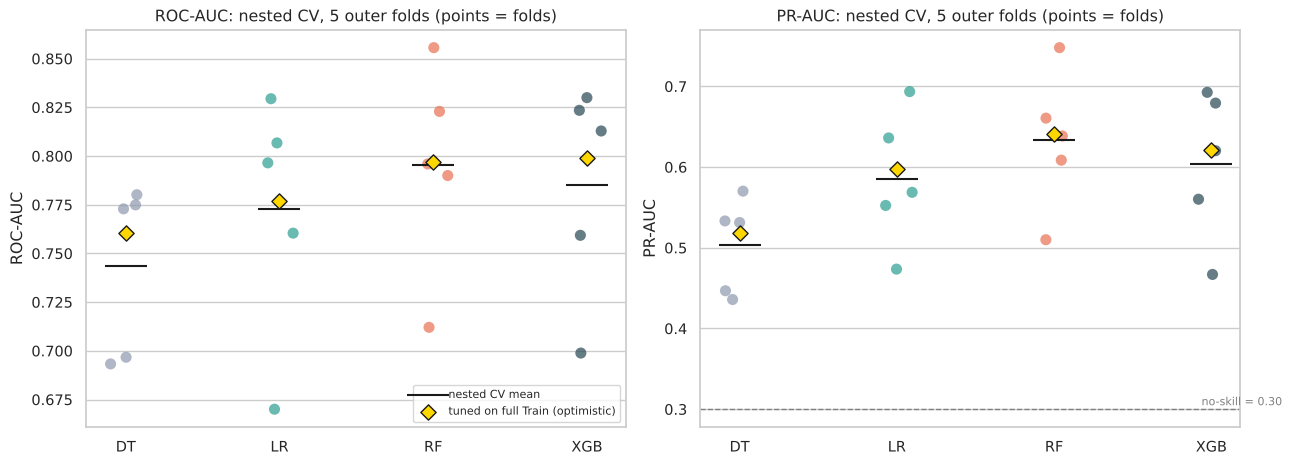

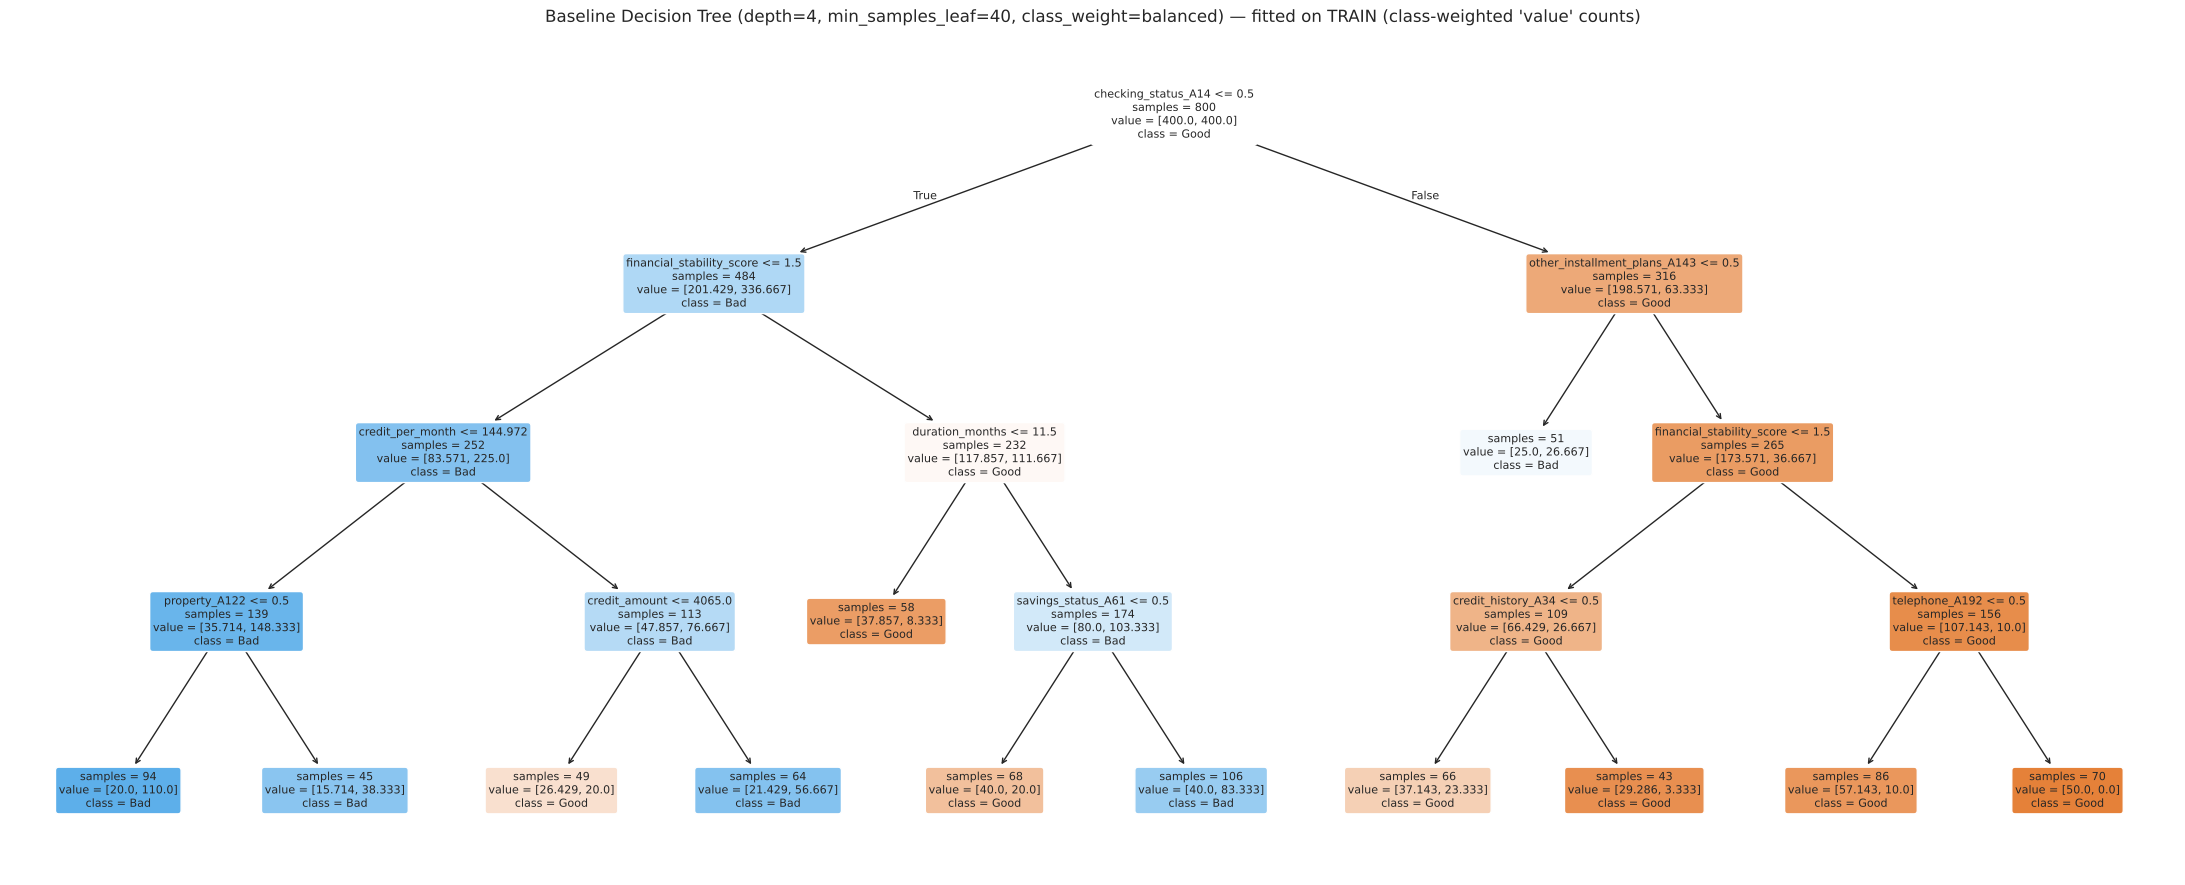

tree: depth 4 leaves 12 | top split: checking_status_A14 | top importances: {'checking_status_A14': 0.439, 'financial_stability_score': 0.167, 'duration_months': 0.092, 'other_installment_plans_A143': 0.082, 'savings_status_A61': 0.08}


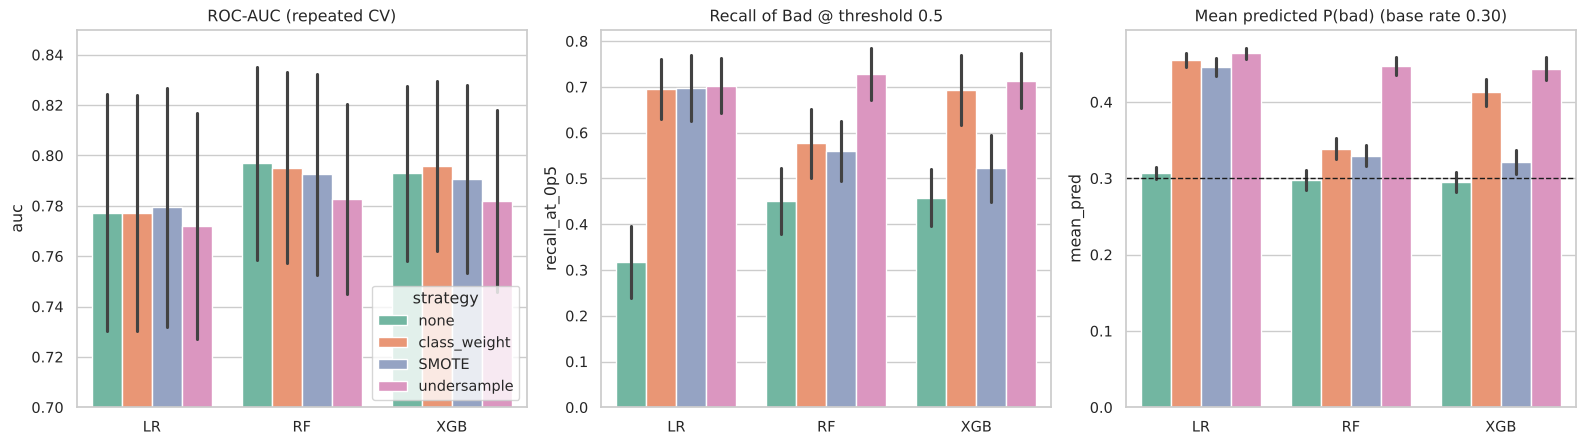

In [24]:
# ---- 5.6 figures: model comparison (nested CV), baseline tree, imbalance strategies -----------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, (col, tc, lab) in zip(ax, [("auc", "cv_auc", "ROC-AUC"), ("prauc", "cv_prauc", "PR-AUC")]):
    sns.stripplot(data=NEST, x="model", y=col, order=MODELS, palette=COLOR, size=8, alpha=.7, ax=a, hue="model", legend=False)
    a.scatter(range(4), NEST.groupby("model")[col].mean().reindex(MODELS).values, marker="_", s=900, c="k", zorder=5, label="nested CV mean")
    a.scatter(range(4), TUNED.loc[MODELS, tc].values, marker="D", c="gold", edgecolor="k", s=60, zorder=6, label="tuned on full Train (optimistic)")
    a.set_xlabel(""); a.set_ylabel(lab); a.set_title(f"{lab}: nested CV, 5 outer folds (points = folds)")
    if col == "prauc": a.axhline(.3, ls="--", c="grey", lw=1); a.text(3.45, .305, "no-skill = 0.30", ha="right", fontsize=8, color="grey")
ax[0].legend(loc="lower right", fontsize=8); savefig("fig08_model_comparison_cv.png")

from sklearn.tree import plot_tree
dt = FINAL["DT"]; names = dt[:-1].get_feature_names_out(); clf_dt = dt.named_steps["clf"]
fig, ax = plt.subplots(figsize=(22, 9)); plot_tree(clf_dt, feature_names=list(names), class_names=["Good", "Bad"], filled=True, rounded=True, impurity=False, fontsize=8, ax=ax)
ax.set_title(f"Baseline Decision Tree (depth={clf_dt.max_depth}, min_samples_leaf={clf_dt.min_samples_leaf}, class_weight={clf_dt.class_weight}) — fitted on TRAIN (class-weighted 'value' counts)", fontsize=12)
savefig("fig09_baseline_tree.png", dpi=120)
print("tree: depth", clf_dt.get_depth(), "leaves", clf_dt.get_n_leaves(), "| top split:", names[clf_dt.tree_.feature[0]], "| top importances:", pd.Series(clf_dt.feature_importances_, index=names).sort_values(ascending=False).head(5).round(3).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (col, lab) in zip(ax, [("auc", "ROC-AUC (repeated CV)"), ("recall_at_0p5", "Recall of Bad @ threshold 0.5"), ("mean_pred", "Mean predicted P(bad) (base rate 0.30)")]):
    sns.barplot(data=IMB, x="model", y=col, hue="strategy", order=["LR", "RF", "XGB"], hue_order=["none", "class_weight", "SMOTE", "undersample"], errorbar="sd", ax=a, palette="Set2"); a.set_title(lab); a.set_xlabel("")
    if col == "auc": a.set_ylim(.7, .85)
    if col == "mean_pred": a.axhline(.3, ls="--", c="k", lw=1)
    if col != "auc": a.get_legend().remove()
savefig("fig10_imbalance_strategies.png")

---
# Part 6 — Evaluation and business cost

**Cost matrix (`german.doc`)**: rows = actual, columns = predicted, 1 = Good, 2 = Bad; approving a Bad customer costs **5**, rejecting a Good customer costs **1**.
With the project target mapping (**Bad = 1 = positive class**): **FN (approve a Bad) = 5**, **FP (reject a Good) = 1**. Costs are relative units of the data set, not currency.

**Protocol (fixed before looking at any result).**
1. Thresholds are chosen on **Train out-of-fold (OOF) predictions with fixed hyper-parameters** — never on Test. Per model: the **median of the cost-minimising thresholds over 2000 bootstrap resamples** (middle of ties).
2. Models are compared with an **honest cost**: the threshold is chosen on in-bag customers and the cost is measured on the out-of-bag ones, so threshold-selection noise is included.
3. **Model selection rule**: lowest mean honest cost; if a *simpler* model (DT < LR < RF = XGBoost) is within **one paired-bootstrap SD** of the best, the simpler one is selected.
4. A second, *milder* operating point is defined in advance as the cost-optimal threshold under a **3 : 1** cost ratio (shown next to the 5 : 1 base case).
5. The decision is written to `frozen_decision.json`; only then the Test set is evaluated — once.

In [25]:
# ---- 6.1 expected-cost machinery, bootstrap thresholds, honest cost, model selection (TRAIN OOF only) -----------------------------------------------------------
assert not TEST_TOUCHED, "Test set must not have been used before the frozen decision"
CFN, CFP = 5.0, 1.0
GRID = np.round(np.arange(0.05, 0.9501, 0.01), 2); y_tr = ytr.values; n_tr = len(y_tr)
def cmat(P, y, cfn=CFN, cfp=CFP):
    """per-customer cost at every threshold, averaged over CV repeats (reject = predict Bad when score >= t)"""
    C = np.zeros((len(y), len(GRID)))
    for p in P:
        pred = p[:, None] >= GRID[None, :]; C += np.where(y[:, None] == 1, cfn * (~pred), cfp * pred)
    return C / len(P)
def amin(c): i = np.flatnonzero(c <= c.min() + 1e-12); return i[len(i) // 2]            # middle of the plateau of minima
Cm = {m: cmat(OOF[m], y_tr) for m in MODELS}; curve = {m: Cm[m].mean(0) for m in MODELS}
print(f"baselines per applicant: reject-all = {CFP*(1-y_tr.mean()):.3f} | approve-all = {CFN*y_tr.mean():.3f}")

B = 300 if FAST else 2000; rng = np.random.default_rng(SEED)
counts = np.stack([np.bincount(rng.integers(0, n_tr, n_tr), minlength=n_tr) for _ in range(B)]); oobm = (counts == 0).astype(float)
res, oobcost, Tstar = {}, {}, {}
for m in MODELS:
    inb = counts @ Cm[m] / n_tr; idx = np.array([amin(r) for r in inb]); Tb = GRID[idx]
    oc = ((oobm @ Cm[m]) / oobm.sum(1)[:, None])[np.arange(B), idx]; oobcost[m] = oc
    med = np.median(Tb); Tstar[m] = float(GRID[np.argmin(abs(GRID - med))]); iT = int(np.argmin(abs(GRID - Tstar[m])))
    res[m] = dict(argmin_full=float(GRID[amin(curve[m])]), T_star=Tstar[m], T_p05=float(np.percentile(Tb, 5)), T_p95=float(np.percentile(Tb, 95)), cost_min_insample=float(curve[m].min()),
                  cost_at_Tstar=float(curve[m][iT]), honest_oob_cost=float(oc.mean()), honest_sd=float(oc.std()), cost_at_0p5=float(curve[m][int(np.argmin(abs(GRID - 0.5)))]), Tb=Tb)
RT = pd.DataFrame({m: {k: v for k, v in d.items() if k != "Tb"} for m, d in res.items()}).T.astype(float); display(RT.round(3))

best_m = min(MODELS, key=lambda m: res[m]["honest_oob_cost"])
Pd = pd.DataFrame([dict(model=m, mean_diff_vs_best=(oobcost[m] - oobcost[best_m]).mean(), sd_paired=(oobcost[m] - oobcost[best_m]).std(), within_1sd=bool((oobcost[m] - oobcost[best_m]).mean() <= (oobcost[m] - oobcost[best_m]).std())) for m in MODELS]).set_index("model")
display(Pd.round(4)); cand = [m for m in MODELS if Pd.loc[m, "within_1sd"]]
SELECTED = min(cand, key=lambda m: (SIMPLE[m], res[m]["honest_oob_cost"]))
Tmild = {m: float(GRID[amin(cmat(OOF[m], y_tr, cfn=3.0).mean(0))]) for m in MODELS}
print(f"lowest honest cost: {best_m} | candidates within 1 paired SD: {cand} => SELECTED (simplest among them): {SELECTED}")
print("thresholds T* (5:1):", Tstar, "\nmild thresholds (3:1):", Tmild)
FROZEN = dict(selected=SELECTED, thresholds=Tstar, mild_thresholds=Tmild, candidates_within_1sd=cand, cost_matrix=dict(FN=CFN, FP=CFP),
              rule="median bootstrap-optimal threshold; model = lowest honest cost, simpler model if within 1 paired SD")
json.dump(FROZEN, open(RES / "frozen_decision.json", "w"), indent=1)
print("\nFROZEN DECISION written to", RES / "frozen_decision.json", "(no Test data used so far)")

baselines per applicant: reject-all = 0.700 | approve-all = 1.500


,argmin_full,T_star,T_p05,T_p95,cost_min_insample,cost_at_Tstar,honest_oob_cost,honest_sd,cost_at_0p5
DT,0.23,0.23,0.23,0.38,0.577,0.577,0.591,0.046,0.663
LR,0.20,0.20,0.16,0.25,0.540,0.540,0.564,0.040,1.053
RF,0.24,0.24,0.16,0.32,0.517,0.517,0.538,0.041,0.671
XGB,0.21,0.21,0.18,0.32,0.516,0.516,0.537,0.042,0.637


,mean_diff_vs_best,sd_paired,within_1sd
model,,,
DT,0.0540,0.0422,False
LR,0.0267,0.0352,True
RF,0.0006,0.0319,True
XGB,0.0000,0.0000,True


lowest honest cost: XGB | candidates within 1 paired SD: ['LR', 'RF', 'XGB'] => SELECTED (simplest among them): LR
thresholds T* (5:1): {'DT': 0.23, 'LR': 0.2, 'RF': 0.24, 'XGB': 0.21} 
mild thresholds (3:1): {'DT': 0.49, 'LR': 0.25, 'RF': 0.32, 'XGB': 0.43}

FROZEN DECISION written to outputs/results/frozen_decision.json (no Test data used so far)


In [26]:
# ---- 6.2 OOF classification metrics at T* (and at 0.5 for reference), AUC bootstrap CIs, calibration ----------------------------------------------------------
def conf(p, y, t): pr = (p >= t).astype(int); return (int(((y == 0) & (pr == 0)).sum()), int(((y == 0) & (pr == 1)).sum()), int(((y == 1) & (pr == 0)).sum()), int(((y == 1) & (pr == 1)).sum()))
def mets(p, y, t):
    tn, fp, fn, tp = conf(p, y, t); pre = tp / max(tp + fp, 1); rec = tp / (tp + fn); spe = tn / (tn + fp)
    return dict(TN=tn, FP=fp, FN=fn, TP=tp, precision=pre, recall=rec, F1=2 * pre * rec / max(pre + rec, 1e-12), specificity=spe, approval_rate=(tn + fn) / len(y), bad_rate_among_approved=fn / max(tn + fn, 1), cost_per_applicant=(CFN * fn + CFP * fp) / len(y))
tabs = []
for m in MODELS:
    for lab, t in [("T*", Tstar[m]), ("0.5", 0.5)]:
        M = pd.DataFrame([mets(OOF[m][r], y_tr, t) for r in range(3)]); row = M.mean().to_dict(); row.update(model=m, threshold=t, rule=lab, sd_cost=M.cost_per_applicant.std()); tabs.append(row)
OOFM = pd.DataFrame(tabs); OOFM.to_csv(RES / "oof_metrics_by_threshold.csv", index=False)
rb = np.random.default_rng(SEED + 1); nbi = 100 if FAST else 1000; bi = [rb.integers(0, n_tr, n_tr) for _ in range(nbi)]; rows = []
for m in MODELS:
    a = [np.mean([roc_auc_score(y_tr[i], OOF[m][r][i]) for r in range(3)]) for i in bi]; p = [np.mean([average_precision_score(y_tr[i], OOF[m][r][i]) for r in range(3)]) for i in bi]
    rows.append(dict(model=m, roc_auc=np.mean([roc_auc_score(y_tr, OOF[m][r]) for r in range(3)]), roc_lo=np.percentile(a, 2.5), roc_hi=np.percentile(a, 97.5),
                     pr_auc=np.mean([average_precision_score(y_tr, OOF[m][r]) for r in range(3)]), pr_lo=np.percentile(p, 2.5), pr_hi=np.percentile(p, 97.5)))
OOFA = pd.DataFrame(rows).set_index("model"); OOFA.to_csv(RES / "oof_auc_ci.csv"); display(OOFA.round(3))
print("OOF metrics at the chosen thresholds T*:"); display(OOFM[OOFM.rule == "T*"].set_index("model")[["threshold", "TN", "FP", "FN", "TP", "precision", "recall", "F1", "specificity", "approval_rate", "bad_rate_among_approved", "cost_per_applicant", "sd_cost"]].round(3))
print("OOF metrics at the default 0.5 (reference only — NOT used):"); display(OOFM[OOFM.rule == "0.5"].set_index("model")[["FP", "FN", "precision", "recall", "F1", "specificity", "approval_rate", "cost_per_applicant"]].round(3))

# calibration check and the Platt-implied theoretical threshold for P(bad)=1/6  (5:1 costs)
lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6))); cal = {}
for m in MODELS:
    p = OOF[m].ravel(); yy = np.tile(y_tr, 3); l_ = LogisticRegression(C=1e6).fit(lg(p)[:, None], yy); a_, b_ = l_.coef_[0, 0], l_.intercept_[0]
    cal[m] = dict(mean_pred=p.mean(), observed=yy.mean(), platt_slope=a_, platt_intercept=b_, theoretical_raw_threshold=float(1 / (1 + np.exp(-(np.log((1 / 6) / (5 / 6)) - b_) / a_))), empirical_T=Tstar[m])
CAL = pd.DataFrame(cal).T; display(CAL.round(3))

,roc_auc,roc_lo,roc_hi,pr_auc,pr_lo,pr_hi
model,,,,,,
DT,0.736,0.705,0.767,0.496,0.444,0.557
LR,0.776,0.741,0.809,0.577,0.513,0.646
RF,0.793,0.761,0.823,0.629,0.568,0.690
XGB,0.795,0.764,0.825,0.607,0.546,0.671


OOF metrics at the chosen thresholds T*:


,threshold,TN,FP,FN,TP,precision,recall,F1,specificity,approval_rate,bad_rate_among_approved,cost_per_applicant,sd_cost
model,,,,,,,,,,,,,
DT,0.23,222.000,338.000,24.667,215.333,0.390,0.897,0.543,0.396,0.308,0.100,0.577,0.012
LR,0.20,231.667,328.333,20.667,219.333,0.400,0.914,0.557,0.414,0.315,0.082,0.540,0.002
RF,0.24,251.667,308.333,21.000,219.000,0.415,0.912,0.571,0.449,0.341,0.077,0.517,0.020
XGB,0.21,227.000,333.000,16.000,224.000,0.402,0.933,0.562,0.405,0.304,0.066,0.516,0.027


OOF metrics at the default 0.5 (reference only — NOT used):


,FP,FN,precision,recall,F1,specificity,approval_rate,cost_per_applicant
model,,,,,,,,
DT,170.667,72.000,0.496,0.700,0.581,0.695,0.577,0.663
LR,45.667,159.333,0.639,0.336,0.440,0.918,0.842,1.053
RF,143.667,78.667,0.529,0.672,0.592,0.743,0.619,0.671
XGB,143.333,73.333,0.538,0.694,0.606,0.744,0.612,0.638


,mean_pred,observed,platt_slope,platt_intercept,theoretical_raw_threshold,empirical_T
DT,0.446,0.3,0.415,-0.739,0.110,0.23
LR,0.308,0.3,1.354,0.194,0.209,0.20
RF,0.398,0.3,0.984,-0.576,0.259,0.24
XGB,0.416,0.3,0.918,-0.693,0.269,0.21


In [27]:
# ---- 6.3 cost-ratio sensitivity and FP/FN analysis by segment (selected model, TRAIN OOF) ----------------------------------------------------------------------------
print(f"cost-ratio sensitivity for {SELECTED}; reject-all cost is always {CFP*(1-y_tr.mean()):.2f}")
sens_rows = []
for r_ in [2, 3, 5, 8, 10]:
    Cr = cmat(OOF[SELECTED], y_tr, cfn=float(r_)).mean(0); i = amin(Cr); t = GRID[i]; M = pd.DataFrame([mets(OOF[SELECTED][k], y_tr, t) for k in range(3)]).mean()
    sens_rows.append(dict(FN_cost=r_, opt_threshold=t, cost=Cr[i], reject_all=CFP * (1 - y_tr.mean()), accept_all=r_ * y_tr.mean(), approval_rate=M.approval_rate, recall=M.recall, specificity=M.specificity))
COSTSENS = pd.DataFrame(sens_rows); COSTSENS.to_csv(RES / "cost_ratio_sensitivity.csv", index=False); display(COSTSENS.round(3))

t = Tstar[SELECTED]; Xs = Xtr.copy(); Xs["dur_bin"] = pd.cut(Xs.duration_months, [0, 12, 24, 36, 100]).astype(str); seg = []
for c in ["checking_status", "credit_history", "savings_status", "dur_bin"]:
    for lv, idx in Xs.groupby(c).groups.items():
        ii = Xtr.index.get_indexer(idx); yy = y_tr[ii]; out = []
        for r in range(3):
            pr = (OOF[SELECTED][r][ii] >= t).astype(int); out.append([(pr[yy == 1] == 0).mean() if (yy == 1).any() else np.nan, (pr[yy == 0] == 1).mean() if (yy == 0).any() else np.nan, (pr == 0).mean()])
        o = np.nanmean(out, 0); seg.append(dict(feature=c, level=lv if c == "dur_bin" else f"{lv} {LAB[c][lv]}", n=len(ii), n_bad=int(yy.sum()), FN_rate_of_bad=o[0], FP_rate_of_good=o[1], approval_rate=o[2]))
SEG = pd.DataFrame(seg); SEG.to_csv(RES / "segment_fp_fn_oof.csv", index=False)
print(f"segments ({SELECTED}, T*={t}): FN-rate = share of Bad customers approved; FP-rate = share of Good customers rejected"); display(SEG.round(3))

cost-ratio sensitivity for LR; reject-all cost is always 0.70


,FN_cost,opt_threshold,cost,reject_all,accept_all,approval_rate,recall,specificity
0,2,0.35,0.382,0.7,0.6,0.638,0.644,0.758
1,3,0.25,0.455,0.7,0.9,0.430,0.846,0.549
2,5,0.20,0.540,0.7,1.5,0.315,0.914,0.414
3,8,0.15,0.587,0.7,2.4,0.185,0.974,0.252
4,10,0.15,0.602,0.7,3.0,0.185,0.974,0.252


segments (LR, T*=0.2): FN-rate = share of Bad customers approved; FP-rate = share of Good customers rejected


,feature,level,n,n_bad,FN_rate_of_bad,FP_rate_of_good,approval_rate
0,checking_status,A11 <0 DM,219,105,0.013,0.909,0.053
1,checking_status,A12 0-200 DM,214,84,0.044,0.821,0.126
2,checking_status,A13 >=200 DM/salary,51,13,0.282,0.684,0.307
3,checking_status,A14 no account,316,38,0.316,0.331,0.627
4,credit_history,A30 no credits/all paid,31,19,0.035,0.861,0.075
5,credit_history,A31 all paid (this bank),41,22,0.030,0.877,0.073
6,credit_history,A32 paid duly till now,416,134,0.077,0.635,0.272
7,credit_history,A33 past delay,72,23,0.087,0.728,0.213
8,credit_history,A34 critical/other credits,240,42,0.167,0.438,0.493
9,savings_status,A61 <100 DM,475,173,0.031,0.703,0.200


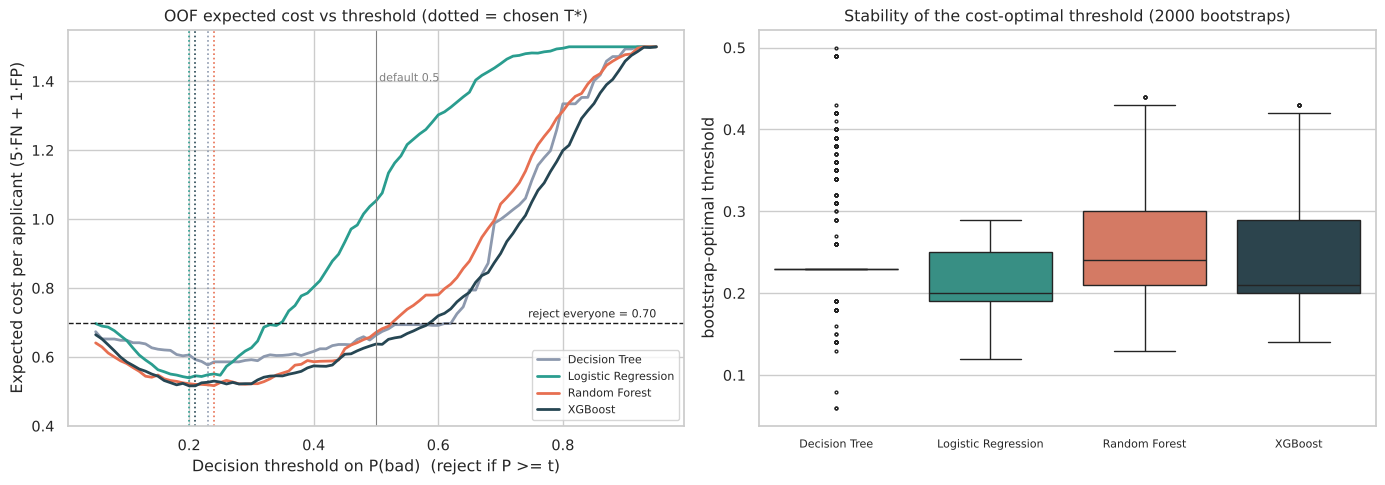

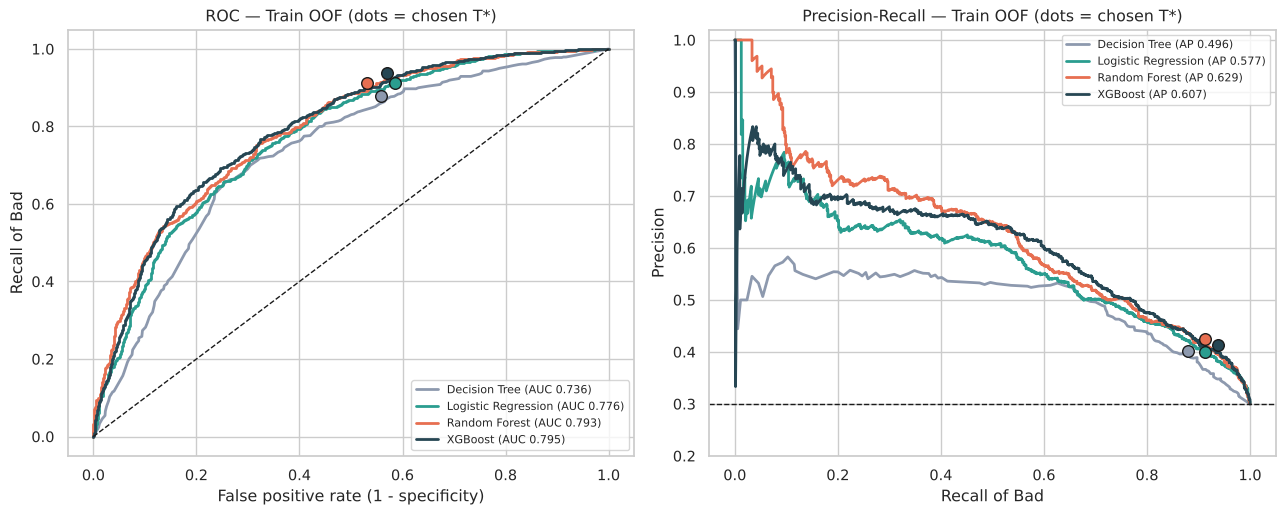

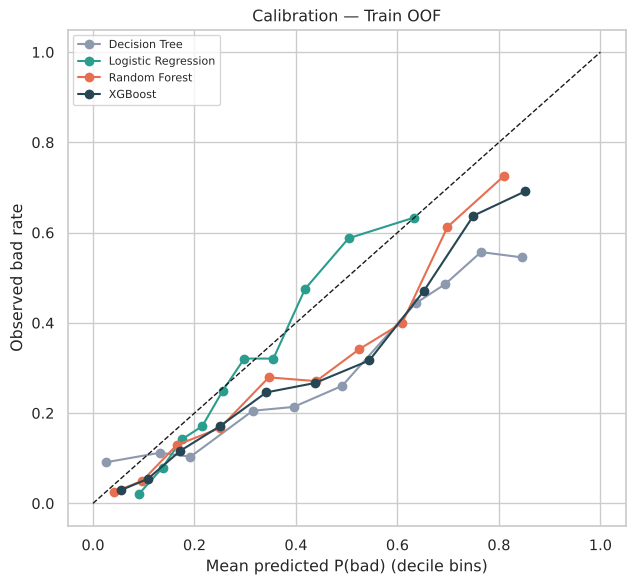

In [28]:
# ---- 6.4 figures on TRAIN OOF: cost curves, ROC / PR, calibration --------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for m in MODELS:
    ax[0].plot(GRID, curve[m], c=COLOR[m], lw=2, label=FULLNAME[m]); ax[0].axvline(Tstar[m], c=COLOR[m], ls=":", lw=1.2)
ax[0].axhline(CFP * (1 - y_tr.mean()), c="k", ls="--", lw=1); ax[0].text(.95, CFP * (1 - y_tr.mean()) + .015, "reject everyone = 0.70", ha="right", fontsize=8); ax[0].axvline(.5, c="grey", lw=.8); ax[0].text(.505, 1.4, "default 0.5", fontsize=8, color="grey")
ax[0].set_ylim(.4, 1.55); ax[0].set_xlabel("Decision threshold on P(bad)  (reject if P >= t)"); ax[0].set_ylabel("Expected cost per applicant (5·FN + 1·FP)"); ax[0].set_title("OOF expected cost vs threshold (dotted = chosen T*)"); ax[0].legend(fontsize=8)
bd = pd.DataFrame({FULLNAME[m]: res[m]["Tb"] for m in MODELS}).melt(var_name="model", value_name="bootstrap-optimal threshold"); sns.boxplot(data=bd, x="model", y="bootstrap-optimal threshold", palette=[COLOR[m] for m in MODELS], ax=ax[1], fliersize=2)
ax[1].set_xlabel(""); ax[1].set_title(f"Stability of the cost-optimal threshold ({B} bootstraps)"); ax[1].tick_params(axis="x", labelsize=8); savefig("fig11_cost_curves_oof.png")

fig, ax = plt.subplots(1, 2, figsize=(13, 5.3))
for m in MODELS:
    p = OOF[m].ravel(); yy = np.tile(y_tr, 3); f, t_, _ = roc_curve(yy, p); ax[0].plot(f, t_, c=COLOR[m], lw=2, label=f"{FULLNAME[m]} (AUC {OOFA.loc[m, 'roc_auc']:.3f})")
    tn, fp, fn, tp = conf(OOF[m][0], y_tr, Tstar[m]); ax[0].scatter(fp / (fp + tn), tp / (tp + fn), c=COLOR[m], s=70, edgecolor="k", zorder=5)
    pr_, rc_, _ = precision_recall_curve(yy, p); ax[1].plot(rc_, pr_, c=COLOR[m], lw=2, label=f"{FULLNAME[m]} (AP {OOFA.loc[m, 'pr_auc']:.3f})"); ax[1].scatter(tp / (tp + fn), tp / max(tp + fp, 1), c=COLOR[m], s=70, edgecolor="k", zorder=5)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False positive rate (1 - specificity)"); ax[0].set_ylabel("Recall of Bad"); ax[0].set_title("ROC — Train OOF (dots = chosen T*)"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].axhline(y_tr.mean(), c="k", ls="--", lw=1); ax[1].set_xlabel("Recall of Bad"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-Recall — Train OOF (dots = chosen T*)"); ax[1].legend(fontsize=8); ax[1].set_ylim(.2, 1.02)
savefig("fig12_roc_pr_oof.png")

fig, ax = plt.subplots(figsize=(6.5, 6))
for m in MODELS:
    p = OOF[m].ravel(); yy = np.tile(y_tr, 3); q = pd.qcut(p, 10, duplicates="drop"); g_ = pd.DataFrame({"p": p, "y": yy}).groupby(q, observed=True).mean(); ax.plot(g_.p, g_.y, "o-", c=COLOR[m], label=FULLNAME[m])
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("Mean predicted P(bad) (decile bins)"); ax.set_ylabel("Observed bad rate"); ax.set_title("Calibration — Train OOF"); ax.legend(fontsize=8); savefig("fig13_calibration_oof.png")

### 6.5 The single final evaluation on the Test set

Everything below uses the thresholds and the selected model **read back from `frozen_decision.json`**. Nothing is tuned here. (Models are the ones refit on the full training set in Part 5.)

In [29]:
# ---- 6.5 TEST evaluation (the only place where Test labels are used) ------------------------------------------------------------------------------------------------------------------
FZ = json.load(open(RES / "frozen_decision.json")); TH, TM, SEL_M = FZ["thresholds"], FZ["mild_thresholds"], FZ["selected"]
TEST_TOUCHED = True
yte_v = yte.values; n_te = len(yte_v)
P = {m: FINAL[m].predict_proba(Xte)[:, 1] for m in MODELS}
pd.DataFrame(P, index=Xte.index).assign(target=yte_v).to_csv(RES / "test_predictions.csv")
pc = lambda p, t: np.where(yte_v == 1, CFN * (p < t), CFP * (p >= t)).astype(float)
rng_t = np.random.default_rng(SEED + 2); nbt = 200 if FAST else 2000; bt = [rng_t.integers(0, n_te, n_te) for _ in range(nbt)]; rows = []
for m in MODELS:
    for lab, t in [("T*", TH[m]), ("0.5", 0.5)]:
        r_ = mets(P[m], yte_v, t); c = pc(P[m], t); cb = [c[i].mean() for i in bt]; r_.update(model=m, rule=lab, threshold=t, cost_lo=np.percentile(cb, 2.5), cost_hi=np.percentile(cb, 97.5))
        if lab == "T*":
            a = [roc_auc_score(yte_v[i], P[m][i]) for i in bt]; pr = [average_precision_score(yte_v[i], P[m][i]) for i in bt]
            r_.update(roc_auc=roc_auc_score(yte_v, P[m]), roc_lo=np.percentile(a, 2.5), roc_hi=np.percentile(a, 97.5), pr_auc=average_precision_score(yte_v, P[m]), pr_lo=np.percentile(pr, 2.5), pr_hi=np.percentile(pr, 97.5), brier=brier_score_loss(yte_v, P[m]))
        rows.append(r_)
TESTM = pd.DataFrame(rows); TESTM.to_csv(RES / "test_metrics.csv", index=False); Ts = TESTM[TESTM.rule == "T*"].set_index("model")
print(f"TEST: n={n_te}, bad={int(yte_v.sum())} | frozen selected model: {SEL_M} | thresholds: {TH}")
display(Ts[["roc_auc", "roc_lo", "roc_hi", "pr_auc", "threshold", "TN", "FP", "FN", "TP", "precision", "recall", "F1", "specificity", "approval_rate", "cost_per_applicant", "cost_lo", "cost_hi"]].round(3))
print("TEST at the default 0.5 (reference only):"); display(TESTM[TESTM.rule == "0.5"].set_index("model")[["FP", "FN", "recall", "specificity", "approval_rate", "cost_per_applicant"]].round(3))
print(f"TEST baselines per applicant: reject-all {CFP*(1-yte_v.mean()):.3f} | approve-all {CFN*yte_v.mean():.3f}")
cs = {m: pc(P[m], TH[m]) for m in MODELS}
print(f"\npaired bootstrap on Test: cost({SEL_M}) - cost(other)   [negative = {SEL_M} cheaper]")
for m in MODELS:
    if m != SEL_M:
        d = np.array([(cs[SEL_M][i] - cs[m][i]).mean() for i in bt]); print(f"  vs {m:3s}: {d.mean():+.3f}  95% CI [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]")
for m in MODELS:
    tn, fp, fn, tp = conf(P[m], yte_v, TH[m]); print(f"  {m:3s} cost breakdown @T*: FN {fn} x 5 = {5*fn} ({5*fn/(5*fn+fp):.0%}) | FP {fp} x 1 = {fp} ({fp/(5*fn+fp):.0%})")

TEST: n=200, bad=60 | frozen selected model: LR | thresholds: {'DT': 0.23, 'LR': 0.2, 'RF': 0.24, 'XGB': 0.21}


,roc_auc,roc_lo,roc_hi,pr_auc,threshold,TN,FP,FN,TP,precision,recall,F1,specificity,approval_rate,cost_per_applicant,cost_lo,cost_hi
model,,,,,,,,,,,,,,,,,
DT,0.752,0.680,0.820,0.536,0.23,55,85,6,54,0.388,0.900,0.543,0.393,0.305,0.575,0.455,0.710
LR,0.776,0.704,0.848,0.633,0.20,58,82,8,52,0.388,0.867,0.536,0.414,0.330,0.610,0.480,0.755
RF,0.794,0.719,0.863,0.695,0.24,59,81,6,54,0.400,0.900,0.554,0.421,0.325,0.555,0.440,0.690
XGB,0.786,0.711,0.855,0.650,0.21,54,86,6,54,0.386,0.900,0.540,0.386,0.300,0.580,0.460,0.715


TEST at the default 0.5 (reference only):


,FP,FN,recall,specificity,approval_rate,cost_per_applicant
model,,,,,,
DT,49,18,0.700,0.650,0.545,0.695
LR,9,40,0.333,0.936,0.855,1.045
RF,35,17,0.717,0.750,0.610,0.600
XGB,39,16,0.733,0.721,0.585,0.595


TEST baselines per applicant: reject-all 0.700 | approve-all 1.500

paired bootstrap on Test: cost(LR) - cost(other)   [negative = LR cheaper]
  vs DT : +0.033  95% CI [-0.095, +0.170]
  vs RF : +0.052  95% CI [-0.075, +0.190]
  vs XGB: +0.029  95% CI [-0.110, +0.185]
  DT  cost breakdown @T*: FN 6 x 5 = 30 (26%) | FP 85 x 1 = 85 (74%)
  LR  cost breakdown @T*: FN 8 x 5 = 40 (33%) | FP 82 x 1 = 82 (67%)
  RF  cost breakdown @T*: FN 6 x 5 = 30 (27%) | FP 81 x 1 = 81 (73%)
  XGB cost breakdown @T*: FN 6 x 5 = 30 (26%) | FP 86 x 1 = 86 (74%)


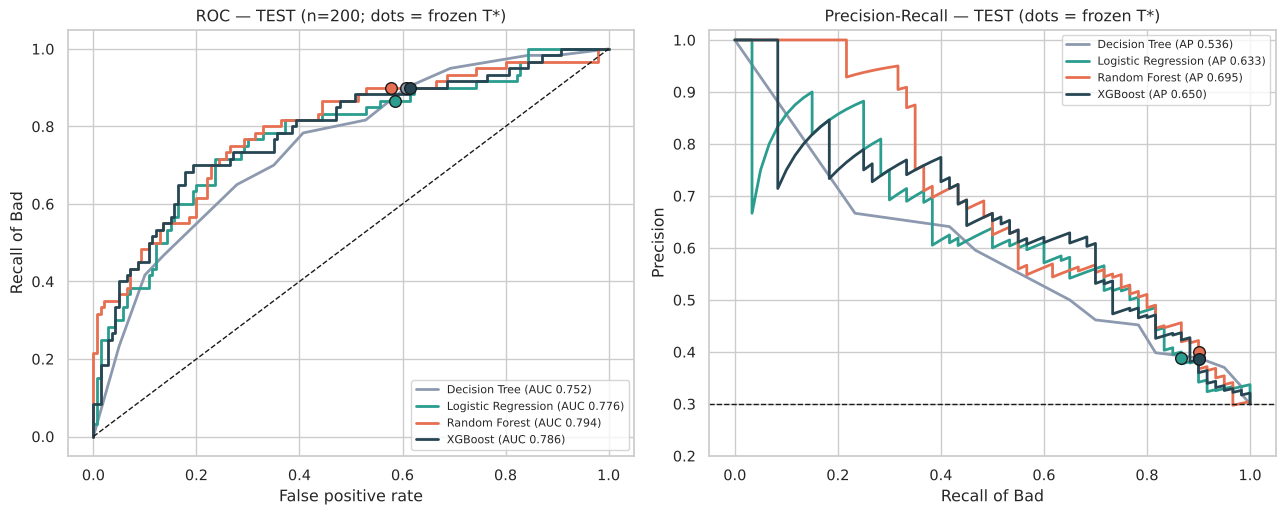

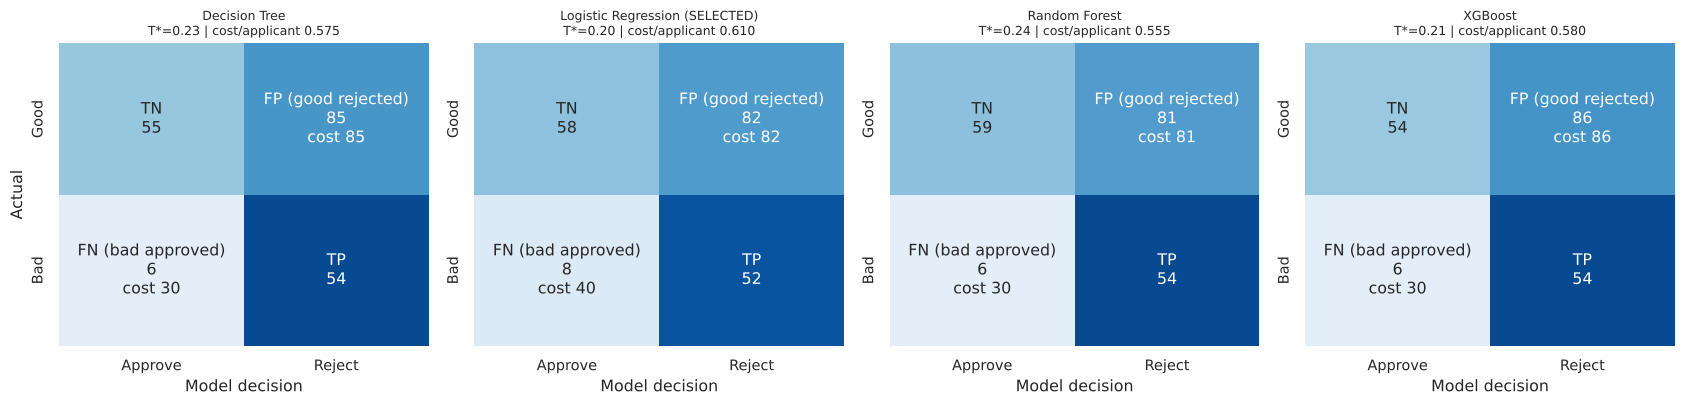

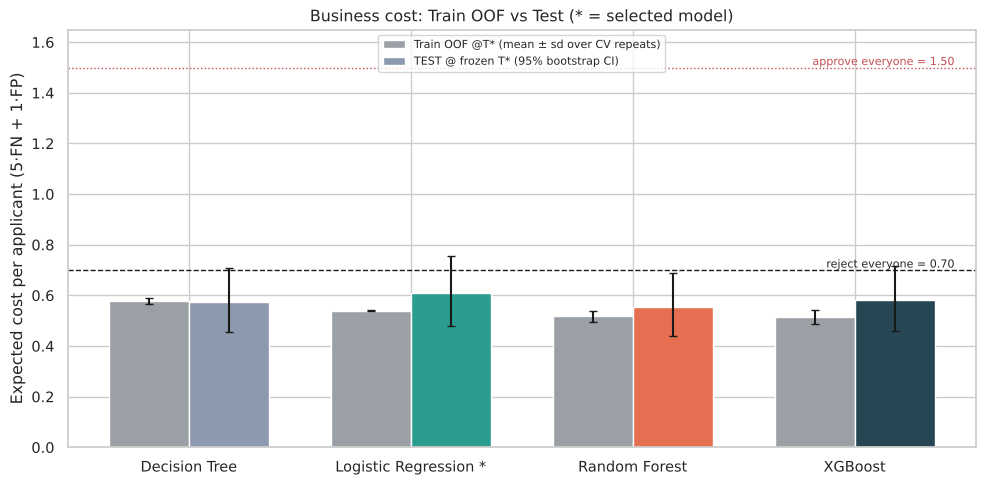

In [30]:
# ---- 6.6 Test figures: ROC / PR, confusion matrices, cost comparison -------------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 5.3))
for m in MODELS:
    f, t_, _ = roc_curve(yte_v, P[m]); ax[0].plot(f, t_, c=COLOR[m], lw=2, label=f"{FULLNAME[m]} (AUC {Ts.loc[m, 'roc_auc']:.3f})"); tn, fp, fn, tp = conf(P[m], yte_v, TH[m]); ax[0].scatter(fp / (fp + tn), tp / (tp + fn), c=COLOR[m], s=70, edgecolor="k", zorder=5)
    pr_, rc_, _ = precision_recall_curve(yte_v, P[m]); ax[1].plot(rc_, pr_, c=COLOR[m], lw=2, label=f"{FULLNAME[m]} (AP {Ts.loc[m, 'pr_auc']:.3f})"); ax[1].scatter(tp / (tp + fn), tp / max(tp + fp, 1), c=COLOR[m], s=70, edgecolor="k", zorder=5)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("Recall of Bad"); ax[0].set_title(f"ROC — TEST (n={n_te}; dots = frozen T*)"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].axhline(yte_v.mean(), c="k", ls="--", lw=1); ax[1].set_xlabel("Recall of Bad"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-Recall — TEST (dots = frozen T*)"); ax[1].legend(fontsize=8); ax[1].set_ylim(.2, 1.02); savefig("fig14_roc_pr_test.png")

fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
for a, m in zip(ax, MODELS):
    tn, fp, fn, tp = conf(P[m], yte_v, TH[m]); cm_ = np.array([[tn, fp], [fn, tp]]); lab = np.array([[f"TN\n{tn}", f"FP (good rejected)\n{fp}\ncost {fp}"], [f"FN (bad approved)\n{fn}\ncost {5*fn}", f"TP\n{tp}"]])
    sns.heatmap(cm_ / cm_.sum(1, keepdims=True), annot=lab, fmt="", cmap="Blues", cbar=False, ax=a, vmin=0, vmax=1, xticklabels=["Approve", "Reject"], yticklabels=["Good", "Bad"])
    a.set_title(f"{FULLNAME[m]}{' (SELECTED)' if m == SEL_M else ''}\nT*={TH[m]:.2f} | cost/applicant {Ts.loc[m, 'cost_per_applicant']:.3f}", fontsize=9); a.set_xlabel("Model decision"); a.set_ylabel("Actual" if m == "DT" else "")
savefig("fig15_confusion_matrices_test.png")

A = OOFM[OOFM.rule == "T*"].set_index("model"); fig, ax = plt.subplots(figsize=(10, 5)); x = np.arange(4); w = .36
ax.bar(x - w / 2, [A.loc[m, "cost_per_applicant"] for m in MODELS], w, yerr=[A.loc[m, "sd_cost"] for m in MODELS], color="#9aa0a6", label="Train OOF @T* (mean ± sd over CV repeats)", capsize=3)
ax.bar(x + w / 2, [Ts.loc[m, "cost_per_applicant"] for m in MODELS], w, yerr=[[Ts.loc[m, "cost_per_applicant"] - Ts.loc[m, "cost_lo"] for m in MODELS], [Ts.loc[m, "cost_hi"] - Ts.loc[m, "cost_per_applicant"] for m in MODELS]], color=[COLOR[m] for m in MODELS], label="TEST @ frozen T* (95% bootstrap CI)", capsize=3)
ax.axhline(.7, c="k", ls="--", lw=1); ax.text(3.45, .71, "reject everyone = 0.70", ha="right", fontsize=8); ax.axhline(1.5, c="r", ls=":", lw=1); ax.text(3.45, 1.51, "approve everyone = 1.50", ha="right", fontsize=8, color="r")
ax.set_xticks(x); ax.set_xticklabels([FULLNAME[m] + (" *" if m == SEL_M else "") for m in MODELS]); ax.set_ylabel("Expected cost per applicant (5·FN + 1·FP)"); ax.set_ylim(0, 1.65); ax.set_title("Business cost: Train OOF vs Test (* = selected model)"); ax.legend(fontsize=8, loc="upper center"); savefig("fig16_cost_comparison.png")

,scenario,threshold,sample,approval_rate,bad_rate_among_approved,recall,specificity,precision,FP,FN,cost_5to1,cost_3to1
0,Base (cost-optimal 5:1),0.20,Train OOF (n=800),0.315,0.082,0.914,0.414,0.400,328.333,20.667,0.540,0.488
1,Base (cost-optimal 5:1),0.20,Test (n=200),0.330,0.121,0.867,0.414,0.388,82.000,8.000,0.610,0.530
2,Mild (cost-optimal 3:1),0.25,Train OOF (n=800),0.430,0.107,0.846,0.549,0.446,252.667,37.000,0.547,0.455
3,Mild (cost-optimal 3:1),0.25,Test (n=200),0.445,0.124,0.817,0.557,0.441,62.000,11.000,0.585,0.475


band between the two thresholds (rejected at base, approved at mild): OOF avg n = 92 of 800, bad rate 0.178 | Test n = 23, bad rate 0.130


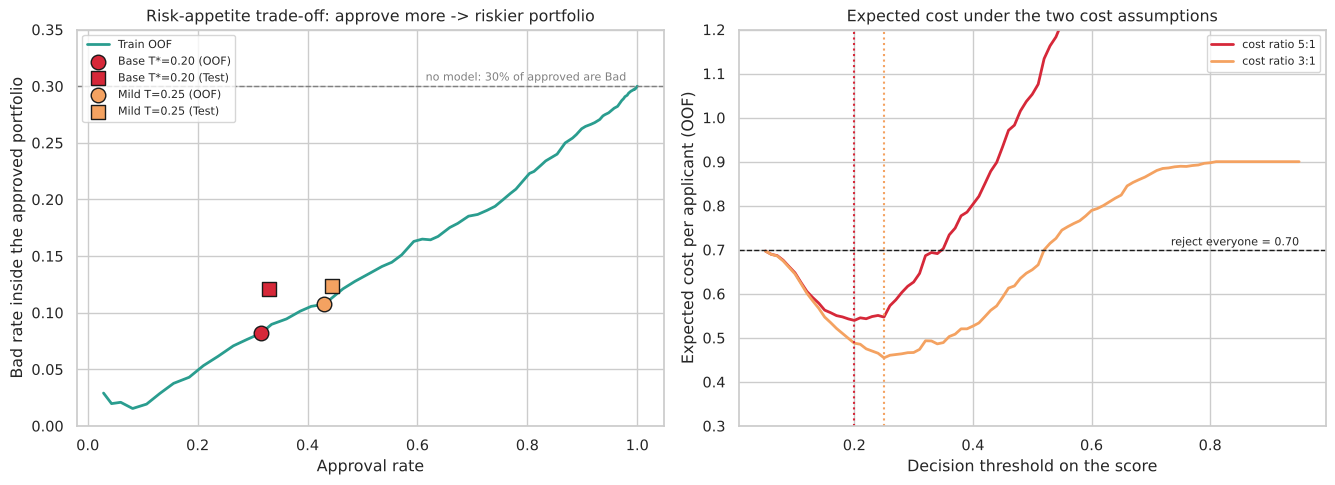

In [31]:
# ---- 6.7 two operating points for the selected model: base (5:1) and mild (3:1), OOF and Test --------------------------------------------------------------------------------------
rows = []
for name, t in [("Base (cost-optimal 5:1)", TH[SEL_M]), ("Mild (cost-optimal 3:1)", TM[SEL_M])]:
    o = pd.DataFrame([mets(OOF[SEL_M][r], y_tr, t) for r in range(3)]).mean().to_dict(); o3 = pd.DataFrame([{"c3": (3 * conf(OOF[SEL_M][r], y_tr, t)[2] + conf(OOF[SEL_M][r], y_tr, t)[1]) / n_tr} for r in range(3)]).mean().c3
    rows.append(dict(scenario=name, threshold=t, sample="Train OOF (n=800)", cost_3to1=o3, **o))
    tn, fp, fn, tp = conf(P[SEL_M], yte_v, t); rt = mets(P[SEL_M], yte_v, t); rows.append(dict(scenario=name, threshold=t, sample=f"Test (n={n_te})", cost_3to1=(3 * fn + fp) / n_te, **rt))
SCEN = pd.DataFrame(rows); SCEN.to_csv(RES / "threshold_scenarios.csv", index=False)
display(SCEN[["scenario", "threshold", "sample", "approval_rate", "bad_rate_among_approved", "recall", "specificity", "precision", "FP", "FN", "cost_per_applicant", "cost_3to1"]].round(3).rename(columns={"cost_per_applicant": "cost_5to1"}))
sp = [mets(OOF[SEL_M][0], y_tr, t) for t in GRID]; band = [((OOF[SEL_M][r] >= TH[SEL_M]) & (OOF[SEL_M][r] < TM[SEL_M])) for r in range(3)]
print("band between the two thresholds (rejected at base, approved at mild): OOF avg n = %.0f of %d, bad rate %.3f | Test n = %d, bad rate %.3f" % (np.mean([b.sum() for b in band]), n_tr, np.mean([y_tr[b].mean() for b in band]),
      int(((P[SEL_M] >= TH[SEL_M]) & (P[SEL_M] < TM[SEL_M])).sum()), float(yte_v[(P[SEL_M] >= TH[SEL_M]) & (P[SEL_M] < TM[SEL_M])].mean())))
fig, ax = plt.subplots(1, 2, figsize=(13.5, 5)); ap = np.array([pd.DataFrame([mets(OOF[SEL_M][r], y_tr, t) for r in range(3)]).mean().approval_rate for t in GRID]); dr = np.array([pd.DataFrame([mets(OOF[SEL_M][r], y_tr, t) for r in range(3)]).mean().bad_rate_among_approved for t in GRID]); ok = ap > .02
ax[0].plot(ap[ok], dr[ok], c="#2a9d8f", lw=2, label="Train OOF"); ax[0].axhline(.3, c="grey", ls="--", lw=1); ax[0].text(.98, .305, "no model: 30% of approved are Bad", ha="right", fontsize=8, color="grey")
for name, t, c in [(f"Base T*={TH[SEL_M]:.2f}", TH[SEL_M], "#d62839"), (f"Mild T={TM[SEL_M]:.2f}", TM[SEL_M], "#f4a261")]:
    mo = pd.DataFrame([mets(OOF[SEL_M][r], y_tr, t) for r in range(3)]).mean(); mt = mets(P[SEL_M], yte_v, t)
    ax[0].scatter(mo.approval_rate, mo.bad_rate_among_approved, s=110, c=c, edgecolor="k", zorder=5, label=name + " (OOF)"); ax[0].scatter(mt["approval_rate"], mt["bad_rate_among_approved"], s=110, c=c, marker="s", edgecolor="k", zorder=5, label=name + " (Test)")
ax[0].set_xlabel("Approval rate"); ax[0].set_ylabel("Bad rate inside the approved portfolio"); ax[0].set_title("Risk-appetite trade-off: approve more -> riskier portfolio"); ax[0].legend(fontsize=8, loc="upper left"); ax[0].set_ylim(0, .35)
for r_, c in [(5, "#d62839"), (3, "#f4a261")]: ax[1].plot(GRID, cmat(OOF[SEL_M], y_tr, cfn=float(r_)).mean(0), c=c, lw=2, label=f"cost ratio {r_}:1")
ax[1].axvline(TH[SEL_M], c="#d62839", ls=":"); ax[1].axvline(TM[SEL_M], c="#f4a261", ls=":"); ax[1].axhline(.7, c="k", ls="--", lw=1); ax[1].text(.95, .71, "reject everyone = 0.70", ha="right", fontsize=8)
ax[1].set_xlabel("Decision threshold on the score"); ax[1].set_ylabel("Expected cost per applicant (OOF)"); ax[1].set_title("Expected cost under the two cost assumptions"); ax[1].legend(fontsize=8); ax[1].set_ylim(.3, 1.2); savefig("fig23_threshold_scenarios.png")

In [32]:
# ---- 6.8 descriptive fairness audit of the selected model (protected-type attributes are NOT model inputs; they are used here only to audit) --------------------------------------------
def groups(df):
    g = pd.DataFrame(index=df.index); g["sex/marital"] = df.personal_status_sex.map(lambda c: f"{c} {LAB['personal_status_sex'][c]}")
    g["age band"] = pd.cut(df.age, [0, 24, 34, 49, 100], labels=["<25", "25-34", "35-49", "50+"]).astype(str); g["foreign worker"] = df.foreign_worker.map(lambda c: f"{c} {LAB['foreign_worker'][c]}"); return g
def audit(df, y, sc, t, label):
    G_ = groups(df); out = []
    for dim in G_.columns:
        for lv in sorted(G_[dim].unique()):
            m = (G_[dim] == lv).values; reps = sc if sc.ndim == 2 else sc[None, :]; ap, fnr, fpr = [], [], []
            for p in reps:
                pr = p[m] >= t; yy = y[m]; ap.append((~pr).mean()); fnr.append((~pr[yy == 1]).mean() if (yy == 1).any() else np.nan); fpr.append(pr[yy == 0].mean() if (yy == 0).any() else np.nan)
            out.append(dict(sample=label, dimension=dim, group=lv, n=int(m.sum()), bad_rate=y[m].mean(), approval_rate=np.mean(ap), FN_rate_of_bad=np.nanmean(fnr), FP_rate_of_good=np.nanmean(fpr)))
    A_ = pd.DataFrame(out); A_["DI_vs_highest_approval"] = A_.groupby("dimension")["approval_rate"].transform(lambda s: s / s.max()); return A_
FAIR = pd.concat([audit(Xtr, y_tr, OOF[SEL_M], TH[SEL_M], "Train OOF"), audit(Xte, yte_v, P[SEL_M], TH[SEL_M], "Test")]); FAIR.to_csv(RES / "fairness_audit.csv", index=False)
display(FAIR[FAIR["sample"] == "Train OOF"].drop(columns="sample").round(3))
print("Test (small groups -> very noisy):"); display(FAIR[FAIR["sample"] == "Test"].drop(columns="sample").round(3))
print("Reading: descriptive only, NOT a legal fairness determination. Group sizes are small (e.g. n=41, n=31). Part of a gap can reflect genuinely different bad rates in the data."
      " Excluding an attribute does not remove its information: remaining inputs act as proxies (tested in Part 7).")

,dimension,group,n,bad_rate,approval_rate,FN_rate_of_bad,FP_rate_of_good,DI_vs_highest_approval
0,sex/marital,A91 male div/sep,41,0.415,0.358,0.098,0.458,1.000
1,sex/marital,A92 female div/sep/mar,249,0.357,0.278,0.094,0.619,0.778
2,sex/marital,A93 male single,430,0.260,0.334,0.086,0.579,0.934
3,sex/marital,A94 male mar/wid,80,0.275,0.308,0.045,0.592,0.862
4,age band,25-34,333,0.327,0.273,0.101,0.643,0.610
5,age band,35-49,264,0.231,0.388,0.093,0.524,0.865
6,age band,50+,93,0.301,0.448,0.107,0.405,1.000
7,age band,<25,110,0.382,0.158,0.024,0.760,0.352
8,foreign worker,A201 yes,769,0.308,0.309,0.086,0.591,0.669
9,foreign worker,A202 no,31,0.097,0.462,0.111,0.500,1.000


Test (small groups -> very noisy):


,dimension,group,n,bad_rate,approval_rate,FN_rate_of_bad,FP_rate_of_good,DI_vs_highest_approval
0,sex/marital,A91 male div/sep,9,0.333,0.333,0.000,0.500,0.915
1,sex/marital,A92 female div/sep/mar,61,0.328,0.295,0.100,0.610,0.810
2,sex/marital,A93 male single,118,0.288,0.364,0.147,0.548,1.000
3,sex/marital,A94 male mar/wid,12,0.250,0.167,0.333,0.889,0.457
4,age band,25-34,66,0.333,0.242,0.182,0.727,0.545
5,age band,35-49,63,0.206,0.444,0.000,0.440,1.000
6,age band,50+,32,0.188,0.438,0.333,0.538,0.984
7,age band,<25,39,0.487,0.205,0.105,0.700,0.462
8,foreign worker,A201 yes,194,0.304,0.325,0.136,0.593,0.649
9,foreign worker,A202 no,6,0.167,0.500,0.000,0.400,1.000


Reading: descriptive only, NOT a legal fairness determination. Group sizes are small (e.g. n=41, n=31). Part of a gap can reflect genuinely different bad rates in the data. Excluding an attribute does not remove its information: remaining inputs act as proxies (tested in Part 7).


---
# Part 7 — Explainable AI (SHAP)

The final model is the one selected by the **frozen rule** in Part 6 (printed there). For a Logistic Regression the SHAP values are *exact* (`LinearExplainer`, interventional, background = all training rows) and live in **log-odds of default** (positive = raises the estimated risk). A tree-based **XGBoost** model (TreeSHAP) is used **only as a cross-check**.

Dummy columns of one original feature are summed (SHAP is additive, so this is valid). **SHAP explains the model, not the world: it is not a causal effect.**

In [33]:
# ---- 7.1 explainers, additivity, grouped global importance ---------------------------------------------------------------------------------------------------------------------------------
import shap
from IPython.display import display, Markdown
if SEL_M != "LR": print("WARNING: the frozen rule did not select LR in this run; Part 7 still explains the Logistic Regression model.")
lr_final = FINAL["LR"]; pre_lr = lr_final[:-1]; clf_lr = lr_final.named_steps["clf"]
Ztr, Zte = pre_lr.transform(Xtr), pre_lr.transform(Xte); cols = list(Ztr.columns)
ex = shap.LinearExplainer(clf_lr, shap.maskers.Independent(Ztr, max_samples=len(Ztr))); sv, svt = ex(Ztr), ex(Zte)
print("model inputs:", Ztr.shape[1], "columns | protected-type attributes among them:", [c for c in cols if any(c.startswith(s) for s in EXCLUDE)])
print("additivity max error (Train, Test): %.1e, %.1e" % (np.abs(ex.expected_value + sv.values.sum(1) - clf_lr.decision_function(Ztr)).max(), np.abs(ex.expected_value + svt.values.sum(1) - clf_lr.decision_function(Zte)).max()))
print("base value (mean log-odds) %.3f | decision thresholds in log-odds: base %.3f, mild %.3f" % (float(ex.expected_value), np.log(TH["LR"] / (1 - TH["LR"])), np.log(TM["LR"] / (1 - TM["LR"]))))

def to_feature(col):
    if col in NUM or col in ENGINEERED: return col
    for c in sorted(CAT, key=len, reverse=True):
        if col.startswith(c + "_"): return c
    raise ValueError(col)
def grouped(values, cols_): return pd.DataFrame(values, columns=cols_).T.groupby([to_feature(c) for c in cols_]).sum().T
Gtr, Gte = grouped(sv.values, cols), grouped(svt.values, cols)
imp = Gtr.abs().mean().sort_values(ascending=False); impt = Gte.abs().mean()
GLOB = pd.DataFrame({"mean_abs_SHAP": imp, "share": imp / imp.sum(), "test_mean_abs_SHAP": impt[imp.index]}); GLOB.to_csv(RES / "lr_global_importance_grouped.csv"); display(GLOB.round(3))
colimp = pd.Series(np.abs(sv.values).mean(0), index=cols).sort_values(ascending=False); rows = []
for c in colimp.index[:15]:
    j = cols.index(c); v = sv.values[:, j]; coef = clf_lr.coef_[0][j]; dummy = set(np.unique(Ztr[c])) <= {0.0, 1.0}
    rows.append(dict(column=c, coef=coef, mean_abs=colimp[c], kind="dummy" if dummy else "numeric", mean_SHAP_when_present=v[Ztr[c].values == 1].mean() if dummy else np.nan, direction="raises risk" if coef > 0 else "lowers risk"))
DIRT = pd.DataFrame(rows); DIRT.to_csv(RES / "lr_top_columns_direction.csv", index=False)
print("top transformed columns and direction (coef = log-odds per 1 SD for numerics / per dummy = 1):"); display(DIRT.round(3))

model inputs: 53 columns | protected-type attributes among them: []
additivity max error (Train, Test): 8.9e-16, 8.9e-16
base value (mean log-odds) -0.956 | decision thresholds in log-odds: base -1.386, mild -1.099


,mean_abs_SHAP,share,test_mean_abs_SHAP
checking_status,0.360,0.169,0.359
financial_stability_score,0.242,0.114,0.237
duration_months,0.192,0.090,0.204
savings_status,0.162,0.076,0.169
credit_history,0.150,0.071,0.145
credit_per_month,0.150,0.071,0.148
installment_rate,0.131,0.061,0.130
credit_amount,0.125,0.059,0.128
purpose,0.125,0.059,0.123
other_installment_plans,0.119,0.056,0.116


top transformed columns and direction (coef = log-odds per 1 SD for numerics / per dummy = 1):


,column,coef,mean_abs,kind,mean_SHAP_when_present,direction
0,checking_status_A14,-0.569,0.272,dummy,-0.344,lowers risk
1,financial_stability_score,-0.287,0.242,numeric,NaN,lowers risk
2,duration_months,0.242,0.192,numeric,NaN,raises risk
3,credit_per_month,-0.187,0.150,numeric,NaN,lowers risk
4,credit_history_A34,-0.346,0.145,dummy,-0.242,lowers risk
5,installment_rate,0.148,0.131,numeric,NaN,raises risk
6,credit_amount,0.154,0.125,numeric,NaN,raises risk
7,checking_status_A11,0.301,0.120,dummy,0.219,raises risk
8,savings_status_A61,0.207,0.100,dummy,0.084,raises risk
9,other_installment_plans_A143,-0.289,0.088,dummy,-0.055,lowers risk


rank agreement SHAP_LR vs SHAP_XGB over 19 features: Spearman = 0.886
  SHAP_LR vs oofAUC_1feat : rho = 0.791 | SHAP_XGB vs oofAUC_1feat: rho = 0.818
  SHAP_LR vs MI           : rho = 0.851 | SHAP_XGB vs MI: rho = 0.928
  SHAP_LR vs PI_RF        : rho = 0.791 | SHAP_XGB vs PI_RF: rho = 0.779
  SHAP_LR vs PI_LR        : rho = 0.826 | SHAP_XGB vs PI_LR: rho = 0.867
top-5 LR : ['checking_status', 'financial_stability_score', 'duration_months', 'savings_status', 'credit_history'] 
top-5 XGB: ['checking_status', 'credit_per_month', 'duration_months', 'financial_stability_score', 'credit_amount'] 
top-8 overlap: 7 of 8
direction check (corr of feature value with its SHAP): LR vs XGB
  duration_months            LR +1.00 | XGB +0.68
  credit_amount              LR +1.00 | XGB +0.77
  credit_per_month           LR -1.00 | XGB -0.43
  financial_stability_score  LR -1.00 | XGB -0.83
  installment_rate           LR +1.00 | XGB +0.83
  existing_credits           LR +1.00 | XGB +0.71
share of LR |S


proxy check — AUC of predicting excluded attributes from the model inputs (0.5 = no information):


,target,cv_auc,prevalence,n_positive
0,female (A92) vs rest,0.687,0.311,249
1,age < 25,0.767,0.138,110
2,age >= 50,0.775,0.116,93
3,foreign worker = no,0.805,0.039,31


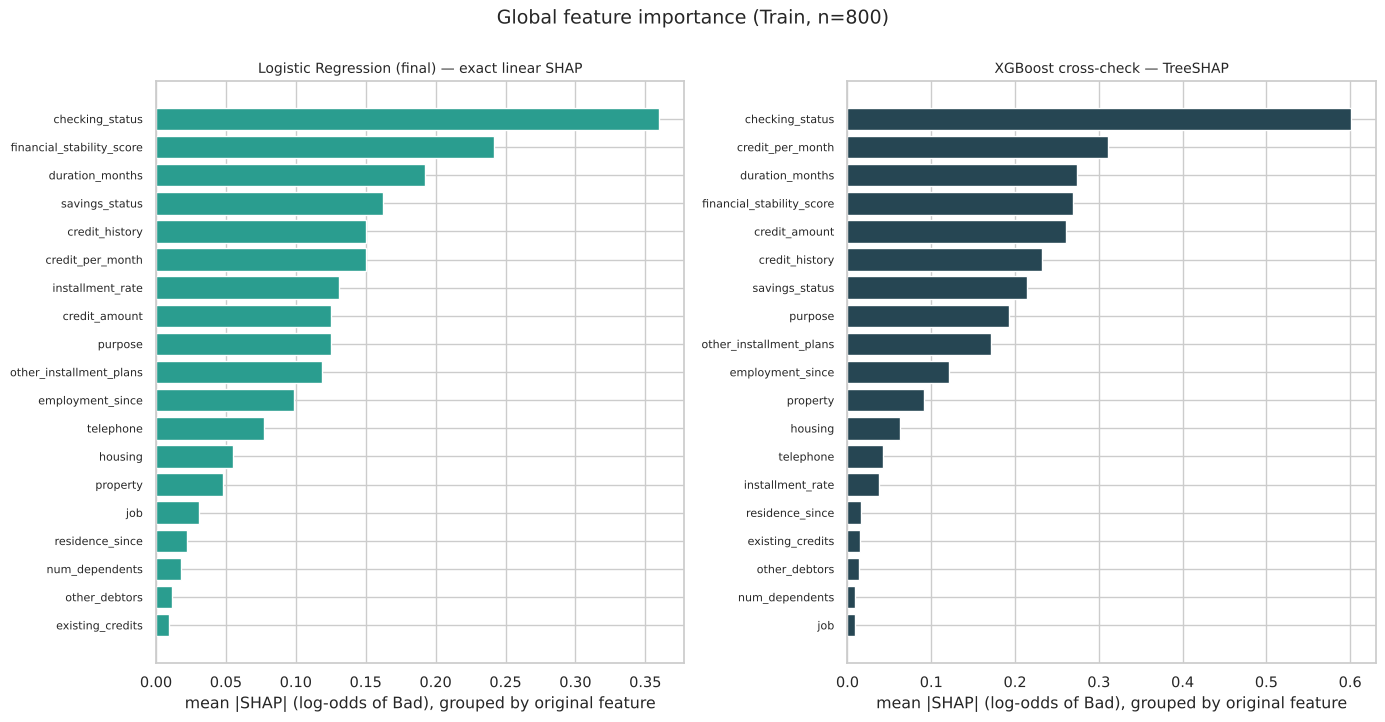

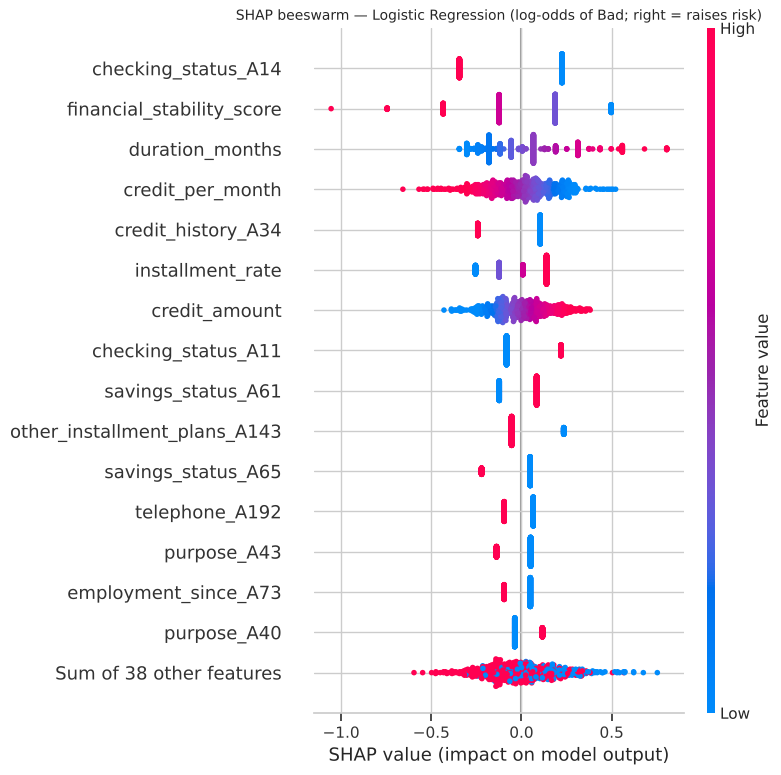

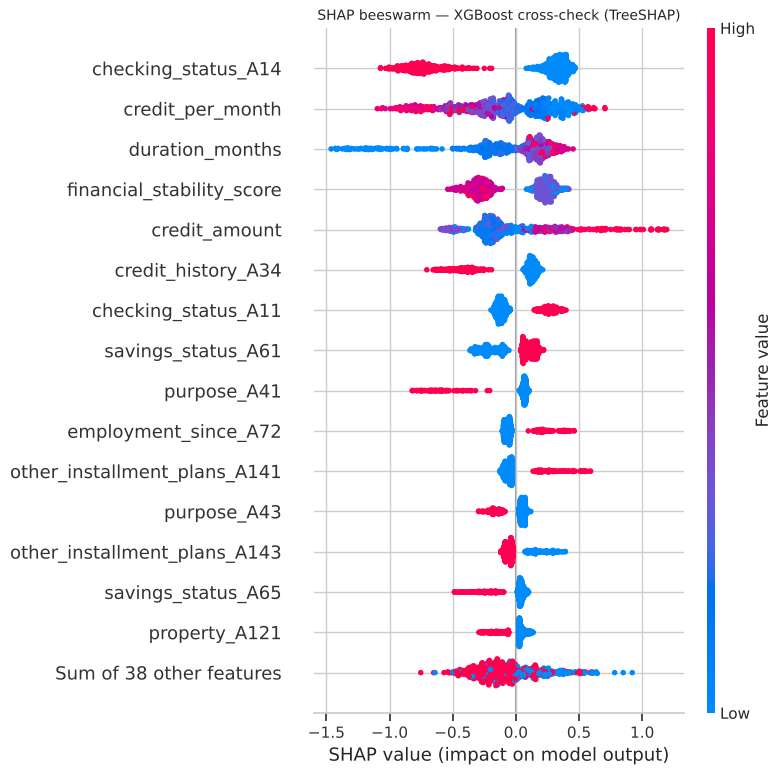

In [34]:
# ---- 7.2 XGBoost cross-check, statistical vs model importance, composite-score overlap, proxy check ---------------------------------------------------------------------------------------------
xgb_f = FINAL["XGB"]; Zx = xgb_f[:-1].transform(Xtr); sx = shap.TreeExplainer(xgb_f.named_steps["clf"])(Zx)
Gx = grouped(sx.values, list(Zx.columns)); impx = Gx.abs().mean().sort_values(ascending=False)
cmp_ = SEL[["oofAUC_1feat", "MI", "PI_RF", "PI_LR"]].join(imp.rename("SHAP_LR"), how="inner"); cmp_["SHAP_XGB"] = impx; cmp_.to_csv(RES / "importance_comparison_stat_vs_shap.csv")
print(f"rank agreement SHAP_LR vs SHAP_XGB over {len(cmp_)} features: Spearman = {stats.spearmanr(cmp_.SHAP_LR, cmp_.SHAP_XGB)[0]:.3f}")
for c in ["oofAUC_1feat", "MI", "PI_RF", "PI_LR"]: print(f"  SHAP_LR vs {c:13s}: rho = {stats.spearmanr(cmp_.SHAP_LR, cmp_[c])[0]:.3f} | SHAP_XGB vs {c}: rho = {stats.spearmanr(cmp_.SHAP_XGB, cmp_[c])[0]:.3f}")
t5l, t5x = list(imp.index[:5]), list(impx.index[:5]); print("top-5 LR :", t5l, "\ntop-5 XGB:", t5x, "\ntop-8 overlap:", len(set(imp.index[:8]) & set(impx.index[:8])), "of 8")
print("direction check (corr of feature value with its SHAP): LR vs XGB")
for f in ["duration_months", "credit_amount", "credit_per_month", "financial_stability_score", "installment_rate", "existing_credits"]:
    print(f"  {f:26s} LR {np.corrcoef(Ztr[f].values, Gtr[f])[0, 1]:+.2f} | XGB {np.corrcoef(Zx[f].values, Gx[f])[0, 1]:+.2f}")
comp = ["employment_since", "housing", "property", "savings_status", "checking_status"]
print("share of LR |SHAP| carried by the stability score AND its five components: %.3f (importance is split between them)" % (imp[comp + ["financial_stability_score"]].sum() / imp.sum()))
a_, b_ = Gtr["credit_amount"], Gtr["credit_per_month"]
print("collinearity: corr(SHAP credit_amount, SHAP credit_per_month) = %.3f | mean|SHAP| %.3f, %.3f, of their SUM %.3f -> read them together, not separately" % (np.corrcoef(a_, b_)[0, 1], a_.abs().mean(), b_.abs().mean(), (a_ + b_).abs().mean()))

# proxy check: how much information about the EXCLUDED attributes remains in the model inputs? (Train, 5-fold CV AUC, descriptive)
from sklearn.model_selection import cross_val_predict
tg = {"female (A92) vs rest": (Xtr.personal_status_sex == "A92").astype(int).values, "age < 25": (Xtr.age < 25).astype(int).values, "age >= 50": (Xtr.age >= 50).astype(int).values, "foreign worker = no": (Xtr.foreign_worker == "A202").astype(int).values}
rows = []
for k, t_ in tg.items():
    p = cross_val_predict(LogisticRegression(C=0.3, max_iter=3000), Ztr, t_, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    rows.append(dict(target=k, cv_auc=roc_auc_score(t_, p), prevalence=t_.mean(), n_positive=int(t_.sum())))
PROXY = pd.DataFrame(rows); PROXY.to_csv(RES / "proxy_check.csv", index=False); print("\nproxy check — AUC of predicting excluded attributes from the model inputs (0.5 = no information):"); display(PROXY.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 7.2))
for a, (s_, t_, cl) in zip(ax, [(imp, "Logistic Regression (final) — exact linear SHAP", "#2a9d8f"), (impx, "XGBoost cross-check — TreeSHAP", "#264653")]):
    s2 = s_.sort_values(); a.barh(s2.index, s2.values, color=cl); a.set_title(t_, fontsize=10); a.set_xlabel("mean |SHAP| (log-odds of Bad), grouped by original feature"); a.tick_params(axis="y", labelsize=8)
fig.suptitle("Global feature importance (Train, n=800)", y=1.0); savefig("fig17_shap_bar_global.png")
plt.figure(figsize=(10, 7)); shap.plots.beeswarm(sv, max_display=16, show=False, order=sv.abs.mean(0)); plt.title("SHAP beeswarm — Logistic Regression (log-odds of Bad; right = raises risk)", fontsize=10); savefig("fig18_shap_beeswarm_lr.png")
plt.figure(figsize=(10, 7)); shap.plots.beeswarm(sx, max_display=16, show=False, order=sx.abs.mean(0)); plt.title("SHAP beeswarm — XGBoost cross-check (TreeSHAP)", fontsize=10); savefig("fig19_shap_beeswarm_xgb.png")

### 7.3 Local explanations — three Test customers chosen from the model's *actual* predictions

Selection rules (fixed in advance, not random): **A** — a correctly approved *Good* customer whose score is closest to the 10th percentile of Test scores; **B** — a correctly rejected *Bad* customer (rejected at both thresholds) whose score is closest to the 90th percentile; **C** — the customer in the middle of the band that is *rejected at the base threshold but approved at the mild one*. The Test set is used here only to *illustrate*; nothing is tuned on it. Protected-type attributes are not model inputs and are not shown in the explanation payload.

Test score quantiles q10=0.117, q90=0.578; thresholds base 0.2 / mild 0.25; candidate pools A=58, B=49, C=23

=== A: low-risk customer, approved | Test row id 473
  LR score 0.117 (log-odds -2.02; base -0.96) | base: APPROVE | mild: APPROVE | actual: Good | XGB score 0.118
  top LR contributions (log-odds, + raises risk): {'checking_status': -0.456, 'savings_status': -0.34, 'duration_months': -0.303, 'financial_stability_score': 0.187, 'installment_rate': 0.139, 'credit_per_month': -0.133}
  XGB top-3: {'checking_status': -0.807, 'duration_months': -0.625, 'credit_per_month': -0.497}


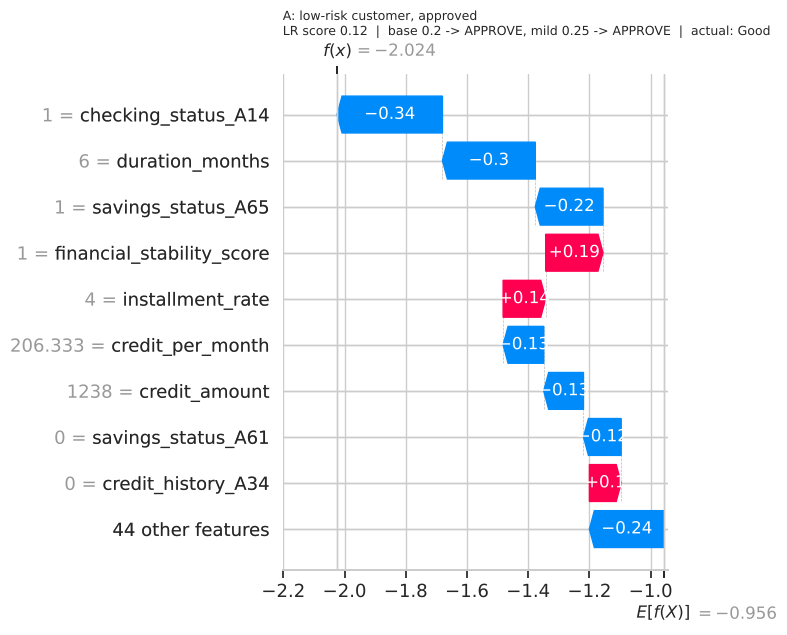


=== B: high-risk customer, rejected | Test row id 915
  LR score 0.578 (log-odds +0.31; base -0.96) | base: REJECT | mild: REJECT | actual: Bad | XGB score 0.841
  top LR contributions (log-odds, + raises risk): {'duration_months': 0.559, 'credit_amount': 0.41, 'other_installment_plans': 0.348, 'credit_per_month': -0.324, 'installment_rate': -0.255, 'credit_history': 0.23}
  XGB top-3: {'credit_amount': 1.008, 'credit_per_month': -0.431, 'savings_status': 0.266}


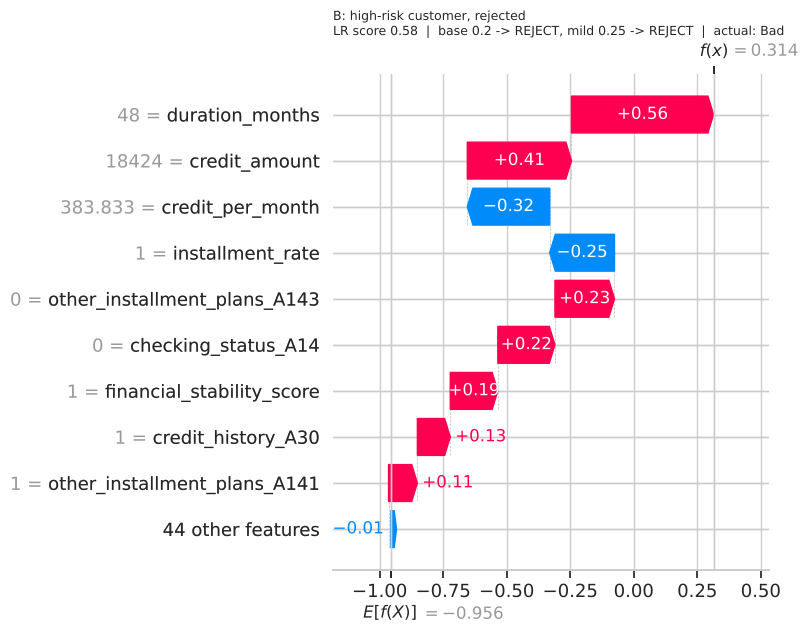


=== C: borderline (reject at base, approve at mild) | Test row id 167
  LR score 0.225 (log-odds -1.24; base -0.96) | base: REJECT | mild: APPROVE | actual: Good | XGB score 0.313
  top LR contributions (log-odds, + raises risk): {'financial_stability_score': -0.434, 'checking_status': 0.22, 'employment_since': 0.214, 'duration_months': -0.201, 'savings_status': -0.148, 'installment_rate': 0.139}
  XGB top-3: {'financial_stability_score': -0.39, 'employment_since': 0.267, 'credit_amount': -0.242}


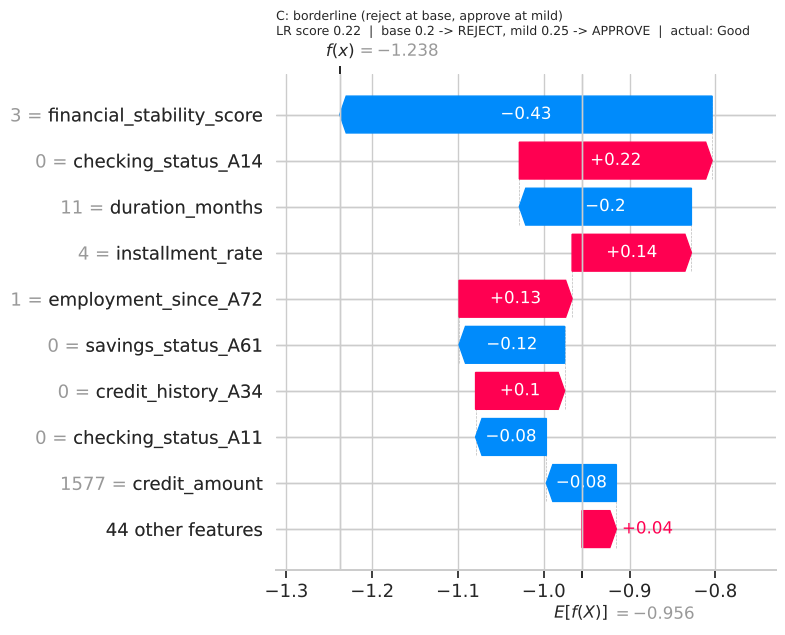


Case B facts used later by the adverse-action letter -> amount 18424.0 | duration 48.0 | row 915


In [35]:
# ---- 7.3 local cases ---------------------------------------------------------------------------------------------------------------------------------------------------------------
T5, TMILD = TH["LR"], TM["LR"]; proba = P["LR"]; q10, q90 = np.quantile(proba, [.10, .90]); logit = lambda p: float(np.log(p / (1 - p)))
Fte = FinancialFeatures().transform(Xte)
cand_A = np.flatnonzero((yte_v == 0) & (proba < T5)); A_i = cand_A[np.argmin(abs(proba[cand_A] - q10))]
cand_B = np.flatnonzero((yte_v == 1) & (proba >= TMILD)); B_i = cand_B[np.argmin(abs(proba[cand_B] - q90))]
mid = (T5 + TMILD) / 2; cand_C = np.flatnonzero((proba >= T5) & (proba < TMILD)); C_i = cand_C[np.argmin(abs(proba[cand_C] - mid))]
print(f"Test score quantiles q10={q10:.3f}, q90={q90:.3f}; thresholds base {T5} / mild {TMILD}; candidate pools A={len(cand_A)}, B={len(cand_B)}, C={len(cand_C)}")
Zraw = Zte.copy()
for c in NUM + ENGINEERED: Zraw[c] = Fte[c].values                                   # readable raw numeric values on the waterfalls
expl = shap.Explanation(values=svt.values, base_values=svt.base_values, data=Zraw.values, feature_names=cols)
Zxt = xgb_f[:-1].transform(Xte); sxt = shap.TreeExplainer(xgb_f.named_steps["clf"])(Zxt); Gxt = grouped(sxt.values, list(Zxt.columns)); px = FINAL["XGB"].predict_proba(Xte)[:, 1]
def profile(i):
    r = Xte.iloc[i]; d = {c: float(r[c]) for c in NUM if c not in EXCLUDE}
    d.update({c: f"{r[c]} ({LAB[c][r[c]]})" for c in CAT if c not in EXCLUDE}); d["credit_per_month"] = round(float(Fte.iloc[i]["credit_per_month"]), 1); d["financial_stability_score"] = int(Fte.iloc[i]["financial_stability_score"]); return d
cases = {}
for tag, i, title in [("A", A_i, "A: low-risk customer, approved"), ("B", B_i, "B: high-risk customer, rejected"), ("C", C_i, "C: borderline (reject at base, approve at mild)")]:
    p = proba[i]; g = grouped(svt.values[[i]], cols).iloc[0].sort_values(key=abs, ascending=False); gx = Gxt.iloc[i].sort_values(key=abs, ascending=False)
    cases[tag] = dict(test_row_id=int(Xte.index[i]), title=title, score_LR=float(p), log_odds=logit(p), base_log_odds=float(ex.expected_value), threshold_base=T5, threshold_mild=TMILD,
        decision_base="REJECT" if p >= T5 else "APPROVE", decision_mild="REJECT" if p >= TMILD else "APPROVE", actual_outcome="Bad" if yte_v[i] == 1 else "Good",
        xgb_score=float(px[i]), profile=profile(i), shap_by_feature_LR={k: round(float(v), 3) for k, v in g.items()}, xgb_top3={k: round(float(v), 3) for k, v in gx.head(3).items()})
    c_ = cases[tag]; print(f"\n=== {title} | Test row id {c_['test_row_id']}\n  LR score {p:.3f} (log-odds {logit(p):+.2f}; base {float(ex.expected_value):+.2f}) | base: {c_['decision_base']} | mild: {c_['decision_mild']} | actual: {c_['actual_outcome']} | XGB score {px[i]:.3f}")
    print("  top LR contributions (log-odds, + raises risk):", dict(list(c_["shap_by_feature_LR"].items())[:6])); print("  XGB top-3:", c_["xgb_top3"])
    plt.figure(figsize=(9.5, 5.6)); shap.plots.waterfall(expl[i], max_display=10, show=False)
    plt.title(f"{title}\nLR score {p:.2f}  |  base {T5} -> {c_['decision_base']}, mild {TMILD} -> {c_['decision_mild']}  |  actual: {c_['actual_outcome']}", fontsize=9, loc="left"); savefig(f"fig{20 + 'ABC'.index(tag)}_waterfall_{tag}.png")
json.dump(cases, open(RES / "local_cases.json", "w"), indent=1)
Cc = cases["B"]["profile"]; print("\nCase B facts used later by the adverse-action letter -> amount", Cc.get("credit_amount"), "| duration", Cc.get("duration_months"), "| row", cases["B"]["test_row_id"])

### 7.4 LIME versus SHAP on the same three customers (optional part of the brief)

**LIME** fits a *local linear surrogate* around one customer from perturbed copies of that customer. Here it is run on the model's **own input features** (the 17 raw inputs; protected-type inputs are held fixed) in *regression mode on the log-odds*, so its weights are in the **same units as the SHAP values**. Three things must be kept in mind when comparing them:
* **SHAP is exact** for this linear model and measures the contribution *relative to the population average*; **LIME is an approximation** whose categorical weights measure *the customer's category versus the alternatives*, so magnitudes can legitimately differ (typically by a constant factor for categorical features).
* LIME works on raw inputs, while SHAP also has the *derived* features `credit_per_month` and `financial_stability_score`; the comparison is therefore made on **feature groups** (derived features are added to the raw features they are built from).
* LIME is stochastic: stability is measured over several random seeds. LIME is used only as a **cross-check**, never as the basis for decisions.

LIME (regression mode on log-odds, 5000 perturbations, 10 seeds) versus exact SHAP, group level:


,spearman_shap_lime,sign_agreement_top5,top3_overlap,lime_local_R2,lime_seed_spearman,sign_agreement_all_seeds
case,,,,,,
A,0.895,1.0,2,0.598,0.954,1.0
B,0.965,1.0,3,0.471,0.970,1.0
C,0.965,1.0,2,0.495,0.982,1.0



case A: largest groups by |SHAP|  (log-odds)


,shap,lime_mean,lime_sd
group,,,
account/savings/job-tenure/housing/property & stability,-0.621,-1.271,0.046
loan size & term,-0.566,-0.538,0.023
installment_rate,0.139,0.277,0.015
credit_history,0.099,0.204,0.012
telephone,-0.095,-0.165,0.010
other_installment_plans,-0.073,-0.381,0.023



case B: largest groups by |SHAP|  (log-odds)


,shap,lime_mean,lime_sd
group,,,
loan size & term,0.645,0.680,0.013
account/savings/job-tenure/housing/property & stability,0.372,0.446,0.046
other_installment_plans,0.348,0.410,0.023
installment_rate,-0.255,-0.292,0.016
credit_history,0.230,0.219,0.042
telephone,-0.095,-0.168,0.023



case C: largest groups by |SHAP|  (log-odds)


,shap,lime_mean,lime_sd
group,,,
loan size & term,-0.303,-0.630,0.016
account/savings/job-tenure/housing/property & stability,-0.234,-0.500,0.035
installment_rate,0.139,0.277,0.018
credit_history,0.099,0.212,0.012
other_installment_plans,-0.073,-0.386,0.028
telephone,0.065,0.162,0.018


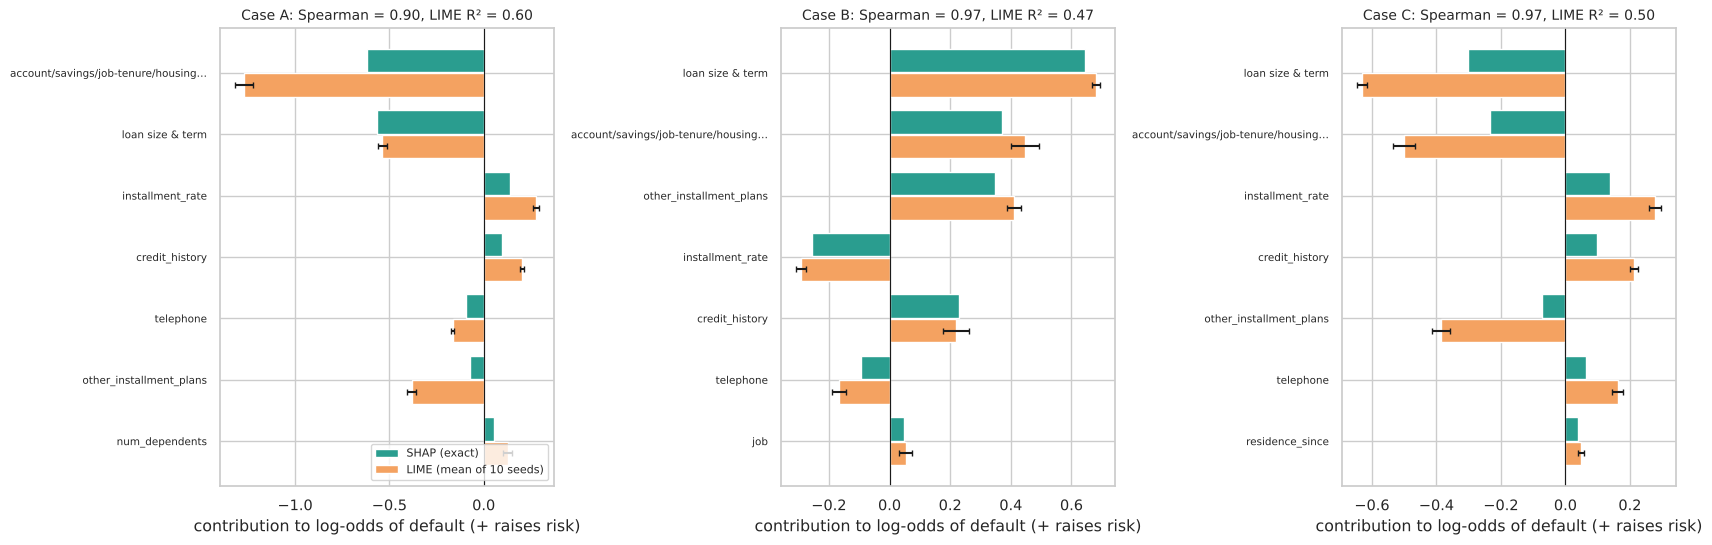

In [36]:
# ---- 7.4 LIME vs SHAP ------------------------------------------------------------------------------------------------------------------------------------------------------------------
try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError as e:
    raise ImportError("LIME is required for this optional part: pip install lime") from e
FEATS = [c for c in NUM + CAT if c not in EXCLUDE]; CATF = [c for c in FEATS if c in CAT]
cats_ = {c: sorted(Xtr[c].unique()) for c in CATF}; idx_cat = [FEATS.index(c) for c in CATF]
enc = Xtr[FEATS].copy()
for c in CATF: enc[c] = enc[c].map({v: i for i, v in enumerate(cats_[c])})
def decode(arr, fixed):
    d = pd.DataFrame(arr, columns=FEATS)
    for c in CATF: d[c] = [cats_[c][int(round(v))] for v in d[c]]
    for c in NUM:
        if c in FEATS: d[c] = d[c].astype(float)
    for c in EXCLUDE: d[c] = fixed[c]                                   # protected-type inputs are not model inputs: held constant
    return d
def run_lime(i, seed, ns=5000):
    row = Xte.iloc[i]; fixed = {c: row[c] for c in EXCLUDE}
    xi = np.array([cats_[c].index(row[c]) if c in CATF else float(row[c]) for c in FEATS], dtype=float)
    ex_ = LimeTabularExplainer(enc.values.astype(float), feature_names=FEATS, categorical_features=idx_cat, categorical_names={FEATS.index(c): cats_[c] for c in CATF},
                               mode="regression", discretize_continuous=True, random_state=seed)
    e = ex_.explain_instance(xi, lambda a: lr_final.decision_function(decode(a, fixed)), num_features=len(FEATS), num_samples=ns)
    key = list(e.local_exp.keys())[-1]; return {FEATS[j]: v for j, v in e.local_exp[key]}, e.score

LGROUPS = {"loan size & term": (["duration_months", "credit_amount"], ["duration_months", "credit_amount", "credit_per_month"]),
           "account/savings/job-tenure/housing/property & stability": (["checking_status", "savings_status", "employment_since", "housing", "property"], ["checking_status", "savings_status", "financial_stability_score", "employment_since", "housing", "property"])}
for f in ["other_installment_plans", "credit_history", "purpose", "installment_rate", "existing_credits", "num_dependents", "residence_since", "other_debtors", "job", "telephone"]: LGROUPS[f] = ([f], [f])
agg_l = lambda w: pd.Series({g: sum(w.get(f, 0) for f in a) for g, (a, b) in LGROUPS.items()})
agg_s = lambda s: pd.Series({g: sum(s.get(f, 0) for f in b) for g, (a, b) in LGROUPS.items()})
n_seeds = 3 if FAST else 10; rows, agree = [], []
for tag in "ABC":
    i = Xte.index.get_loc(cases[tag]["test_row_id"]); S_ = agg_s(cases[tag]["shap_by_feature_LR"]); W, R2 = [], []
    for sd in range(n_seeds):
        w, r2 = run_lime(i, sd); W.append(agg_l(w)); R2.append(r2)
    W = pd.DataFrame(W); L0 = W.iloc[0]
    top5 = list(S_.abs().sort_values(ascending=False).index[:5]); top3s = set(S_.abs().sort_values(ascending=False).index[:3]); top3l = set(L0.abs().sort_values(ascending=False).index[:3])
    pair = [stats.spearmanr(W.iloc[a], W.iloc[b])[0] for a in range(n_seeds) for b in range(a + 1, n_seeds)]
    agree.append(dict(case=tag, spearman_shap_lime=stats.spearmanr(S_, L0)[0], sign_agreement_top5=float(np.mean([np.sign(S_[g]) == np.sign(L0[g]) for g in top5])), top3_overlap=len(top3s & top3l),
                      lime_local_R2=float(np.mean(R2)), lime_seed_spearman=float(np.mean(pair)), sign_agreement_all_seeds=float(np.mean([[np.sign(W.iloc[k][g]) == np.sign(S_[g]) for g in top5] for k in range(n_seeds)]))))
    for g in S_.index: rows.append(dict(case=tag, group=g, shap=S_[g], lime_mean=W[g].mean(), lime_sd=W[g].std()))
LV = pd.DataFrame(rows); AG = pd.DataFrame(agree).set_index("case"); LV.to_csv(RES / "lime_vs_shap.csv", index=False); AG.to_csv(RES / "lime_agreement.csv")
print(f"LIME (regression mode on log-odds, 5000 perturbations, {n_seeds} seeds) versus exact SHAP, group level:"); display(AG.round(3))
for tag in "ABC":
    print(f"\ncase {tag}: largest groups by |SHAP|  (log-odds)"); display(LV[LV.case == tag].set_index("group").sort_values("shap", key=abs, ascending=False).head(6)[["shap", "lime_mean", "lime_sd"]].round(3))

fig, axs = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, tag in zip(axs, "ABC"):
    d_ = LV[LV.case == tag].set_index("group").sort_values("shap", key=abs, ascending=False).head(7).iloc[::-1]; y_ = np.arange(len(d_))
    ax.barh(y_ + .2, d_.shap, height=.38, color="#2a9d8f", label="SHAP (exact)"); ax.barh(y_ - .2, d_.lime_mean, height=.38, xerr=d_.lime_sd, color="#f4a261", label=f"LIME (mean of {n_seeds} seeds)", capsize=2)
    ax.set_yticks(y_); ax.set_yticklabels([g[:34] + ("…" if len(g) > 34 else "") for g in d_.index], fontsize=7.5); ax.axvline(0, c="k", lw=.8)
    ax.set_title(f"Case {tag}: Spearman = {AG.loc[tag, 'spearman_shap_lime']:.2f}, LIME R² = {AG.loc[tag, 'lime_local_R2']:.2f}", fontsize=10); ax.set_xlabel("contribution to log-odds of default (+ raises risk)")
axs[0].legend(fontsize=8, loc="lower right"); savefig("fig26_lime_vs_shap.png")

**Reading of the LIME comparison (statements refer to the table and figure above):** at the level of feature groups LIME broadly **confirms the direction and the ranking of SHAP** for the three customers (high rank correlation, the same sign for the main drivers) and is **stable across seeds**. It is, however, only a **weak local approximation of this model** (local R² well below 1 — the surrogate works on binned numeric features and one-vs-rest categorical indicators), and its **magnitudes are not on the same footing as SHAP's** for categorical features (contrast against the alternatives rather than against the population average). Consequently SHAP remains the primary explanation (exact for the linear model, additive, consistent with the intercept), and LIME is reported as an independent sanity check. The agreement says that both methods describe the *same model*; it says nothing about causality.

---
# Part 8 — Causality vs. correlation

The data are **observational** (1000 granted-or-observed loans; no randomisation, no income, no interest rate, no time, no rejected applicants). Nothing below can *prove* a causal effect. The diagnostics only show which associations **survive adjustment** (so confounding by *measured* variables is not the whole story) and how large an **unmeasured** confounder would have to be (E-value) to explain an association away. Protected-type attributes are used here *only as adjusters* in this diagnostic, never as model inputs.

In [37]:
# ---- 8.1 crude vs fully-adjusted odds ratios with bootstrap CIs and E-values (TRAIN only) ----------------------------------------------------------------------------------------------------------------
trn = Xtr.assign(target=ytr); y_c = trn.target.values; n_c = len(trn)
REF = {"checking_status": "A11", "credit_history": "A32", "savings_status": "A61", "employment_since": "A73", "purpose": "A43", "personal_status_sex": "A93", "other_debtors": "A101",
       "property": "A121", "other_installment_plans": "A143", "housing": "A152", "job": "A173", "telephone": "A191", "foreign_worker": "A201"}
def design(df_):
    Xd = pd.DataFrame({"duration (+12 months)": df_.duration_months / 12, "credit amount (x2)": np.log2(df_.credit_amount), "age (+10 years)": df_.age / 10, "installment_rate (+1 level)": df_.installment_rate,
                       "existing_credits (+1)": df_.existing_credits, "residence_since (+1 level)": df_.residence_since, "num_dependents (+1)": df_.num_dependents})
    for c, r in REF.items():
        d_ = pd.get_dummies(df_[c], prefix=c).astype(float); Xd = pd.concat([Xd, d_.drop(columns=f"{c}_{r}")], axis=1)
    return Xd
Xd = design(trn); dcols = list(Xd.columns)
KEY = ["duration (+12 months)", "credit amount (x2)", "age (+10 years)", "installment_rate (+1 level)", "checking_status_A12", "checking_status_A13", "checking_status_A14", "credit_history_A30", "credit_history_A31", "credit_history_A33", "credit_history_A34",
       "savings_status_A62", "savings_status_A63", "savings_status_A64", "savings_status_A65", "employment_since_A71", "employment_since_A72", "employment_since_A74", "employment_since_A75", "telephone_A192", "other_installment_plans_A141"]
grp = {c: ([k for k in dcols if k.startswith(c.split("_A")[0] + "_A")] if "_A" in c else [c]) for c in KEY}
fit_ = lambda Xm, yy: LogisticRegression(C=10, max_iter=5000).fit(Xm, yy)
def crude(Xb, yb): return {c: fit_(Xb[grp[c]], yb).coef_[0][grp[c].index(c)] for c in KEY}
def adj(Xb, yb): return dict(zip(dcols, fit_(Xb, yb).coef_[0]))
cr, ad = crude(Xd, y_c), adj(Xd, y_c); Bc = 30 if FAST else 500
def _boot():
    rng = np.random.default_rng(SEED); BC_, BA_ = [], []
    for _ in range(Bc):
        i = rng.integers(0, n_c, n_c); BC_.append(crude(Xd.iloc[i], y_c[i])); a = adj(Xd.iloc[i], y_c[i]); BA_.append({c: a[c] for c in KEY})
    return pd.DataFrame(BC_), pd.DataFrame(BA_)
BC, BA = cached("or_bootstrap", _boot); rows = []
for c in KEY:
    lo_c, hi_c = np.percentile(BC[c], [2.5, 97.5]); lo_a, hi_a = np.percentile(BA[c], [2.5, 97.5]); o_a = np.exp(ad[c]); crosses = lo_a <= 0 <= hi_a
    rr = np.sqrt(o_a); rr = rr if rr >= 1 else 1 / rr; near = min([np.exp(lo_a), np.exp(hi_a)], key=lambda v: abs(np.log(v))); rrc = np.sqrt(near); rrc = rrc if rrc >= 1 else 1 / rrc
    rows.append(dict(term=c, OR_crude=np.exp(cr[c]), crude_lo=np.exp(lo_c), crude_hi=np.exp(hi_c), OR_adj=o_a, adj_lo=np.exp(lo_a), adj_hi=np.exp(hi_a), sign_flip=bool(np.sign(cr[c]) != np.sign(ad[c])), adj_CI_excludes_1=not crosses,
                     E_value_point=rr + np.sqrt(rr * (rr - 1)), E_value_CI=1.0 if crosses else rrc + np.sqrt(rrc * (rrc - 1))))
ORT = pd.DataFrame(rows); ORT.to_csv(RES / "crude_vs_adjusted_OR.csv", index=False)
print("Odds ratios for default (reference levels: checking <0 DM, history 'paid duly', savings <100 DM, employment 1-4y). E-value uses RR ~ sqrt(OR) because default is common (30%).")
display(ORT.round(2))

Odds ratios for default (reference levels: checking <0 DM, history 'paid duly', savings <100 DM, employment 1-4y). E-value uses RR ~ sqrt(OR) because default is common (30%).


,term,OR_crude,crude_lo,crude_hi,OR_adj,adj_lo,adj_hi,sign_flip,adj_CI_excludes_1,E_value_point,E_value_CI
0,duration (+12 months),1.55,1.34,1.82,1.51,1.15,2.18,False,True,1.76,1.36
1,credit amount (x2),1.21,1.06,1.40,1.20,0.88,1.77,False,False,1.41,1.00
2,age (+10 years),0.89,0.77,1.04,0.95,0.71,1.21,False,False,1.19,1.00
3,installment_rate (+1 level),1.17,1.01,1.35,1.38,1.13,1.84,False,True,1.63,1.32
4,checking_status_A12,0.71,0.49,1.01,0.69,0.38,1.14,False,False,1.71,1.00
5,checking_status_A13,0.38,0.18,0.72,0.47,0.14,1.10,False,False,2.28,1.00
6,checking_status_A14,0.15,0.09,0.23,0.20,0.10,0.32,False,True,3.86,2.96
7,credit_history_A30,3.26,1.49,7.12,1.92,0.69,7.97,False,False,2.11,1.00
8,credit_history_A31,2.42,1.23,4.88,1.42,0.54,3.93,False,False,1.67,1.00
9,credit_history_A33,0.99,0.55,1.67,0.91,0.43,2.22,False,False,1.27,1.00


In [38]:
# ---- 8.2 how marker groups differ, age vs job stability, and a model 'what-if' on non-causal markers -----------------------------------------------------------------------------------------------------------------------
a14 = trn.checking_status == "A14"
prof = pd.DataFrame({"A14 (no account)": [a14.sum(), trn[a14].target.mean(), trn[a14].duration_months.median(), trn[a14].age.median(), (trn[a14].credit_history == "A34").mean(), (trn[a14].savings_status == "A65").mean()],
                     "others": [(~a14).sum(), trn[~a14].target.mean(), trn[~a14].duration_months.median(), trn[~a14].age.median(), (trn[~a14].credit_history == "A34").mean(), (trn[~a14].savings_status == "A65").mean()]},
                    index=["n", "bad rate", "median duration", "median age", "share history A34", "share savings unknown"]); display(prof.round(3))
print("bad rate by credit_history inside checking strata:")
for lv in ["A30", "A31", "A32", "A33", "A34"]:
    s = trn[trn.credit_history == lv]; print(f"  {lv} {LAB['credit_history'][lv]:24s}", " | ".join(f"{nm}: {s[m].target.mean():.2f} (n={int(m.sum())})" if m.sum() else f"{nm}: n/a" for nm, m in [("A14", s.checking_status == "A14"), ("not A14", s.checking_status != "A14")]), f"| overall {s.target.mean():.2f}")
tr2 = trn.assign(ageb=pd.cut(trn.age, [0, 24, 34, 49, 100], labels=["<25", "25-34", "35-49", "50+"]), stable=trn.employment_since.isin(["A74", "A75"]))
print("\nage: crude bad rate", tr2.groupby("ageb", observed=True).target.mean().round(3).to_dict(), "\n     share with job tenure >= 4y:", tr2.groupby("ageb", observed=True).stable.mean().round(3).to_dict())
display(tr2.pivot_table(index="ageb", columns="stable", values="target", aggfunc=["mean", "count"], observed=True).round(3))

TH_LR = TH["LR"]; rej = lr_final.predict_proba(Xtr)[:, 1] >= TH_LR
def flips(col, frm, to):
    Xm = Xtr.copy(); m = rej & (Xm[col] == frm); Xm.loc[m, col] = to; p1 = lr_final.predict_proba(Xm)[:, 1]; ch = m & (p1 < TH_LR); return int(m.sum()), int(ch.sum()), float(ytr[m].mean()), float(ytr[ch].mean()) if ch.sum() else np.nan
print(f"\nmodel what-if (final LR, T={TH_LR}; Train, in-sample illustration; {int(rej.sum())} rejected): changing a MARKER flips decisions although nothing about repayment capacity has changed")
for col, frm, to, lab in [("telephone", "A191", "A192", "give a registered phone to rejected customers without one"), ("checking_status", "A11", "A14", "relabel negative-balance accounts as 'no account'"), ("savings_status", "A61", "A63", "raise savings <100 DM to 500-1000 DM (may be partly real)")]:
    k, f, br, brf = flips(col, frm, to); print(f"  {lab}: affected {k}, flip to APPROVE {f}" + (f" | those flipped keep their observed bad rate {brf:.2f} (approved portfolio at T*: {mets(OOF['LR'][0], y_tr, TH_LR)['bad_rate_among_approved']:.2f})" if f else ""))

,A14 (no account),others
n,316.000,484.000
bad rate,0.120,0.417
median duration,18.000,18.000
median age,34.000,32.000
share history A34,0.386,0.244
share savings unknown,0.253,0.132


bad rate by credit_history inside checking strata:
  A30 no credits/all paid      A14: 0.33 (n=6) | not A14: 0.68 (n=25) | overall 0.61
  A31 all paid (this bank)     A14: 0.25 (n=8) | not A14: 0.61 (n=33) | overall 0.54
  A32 paid duly till now       A14: 0.12 (n=148) | not A14: 0.43 (n=268) | overall 0.32
  A33 past delay               A14: 0.28 (n=32) | not A14: 0.35 (n=40) | overall 0.32
  A34 critical/other credits   A14: 0.06 (n=122) | not A14: 0.30 (n=118) | overall 0.17

age: crude bad rate {'<25': 0.382, '25-34': 0.327, '35-49': 0.231, '50+': 0.301} 
     share with job tenure >= 4y: {'<25': 0.273, '25-34': 0.324, '35-49': 0.572, '50+': 0.602}


mean        count      
stable  False  True  False True 
ageb                            
<25     0.375  0.400    80    30
25-34   0.369  0.241   225   108
35-49   0.248  0.219   113   151
50+     0.378  0.250    37    56


model what-if (final LR, T=0.2; Train, in-sample illustration; 535 rejected): changing a MARKER flips decisions although nothing about repayment capacity has changed
  give a registered phone to rejected customers without one: affected 333, flip to APPROVE 35 | those flipped keep their observed bad rate 0.17 (approved portfolio at T*: 0.08)
  relabel negative-balance accounts as 'no account': affected 207, flip to APPROVE 69 | those flipped keep their observed bad rate 0.26 (approved portfolio at T*: 0.08)


  raise savings <100 DM to 500-1000 DM (may be partly real): affected 377, flip to APPROVE 115 | those flipped keep their observed bad rate 0.21 (approved portfolio at T*: 0.08)


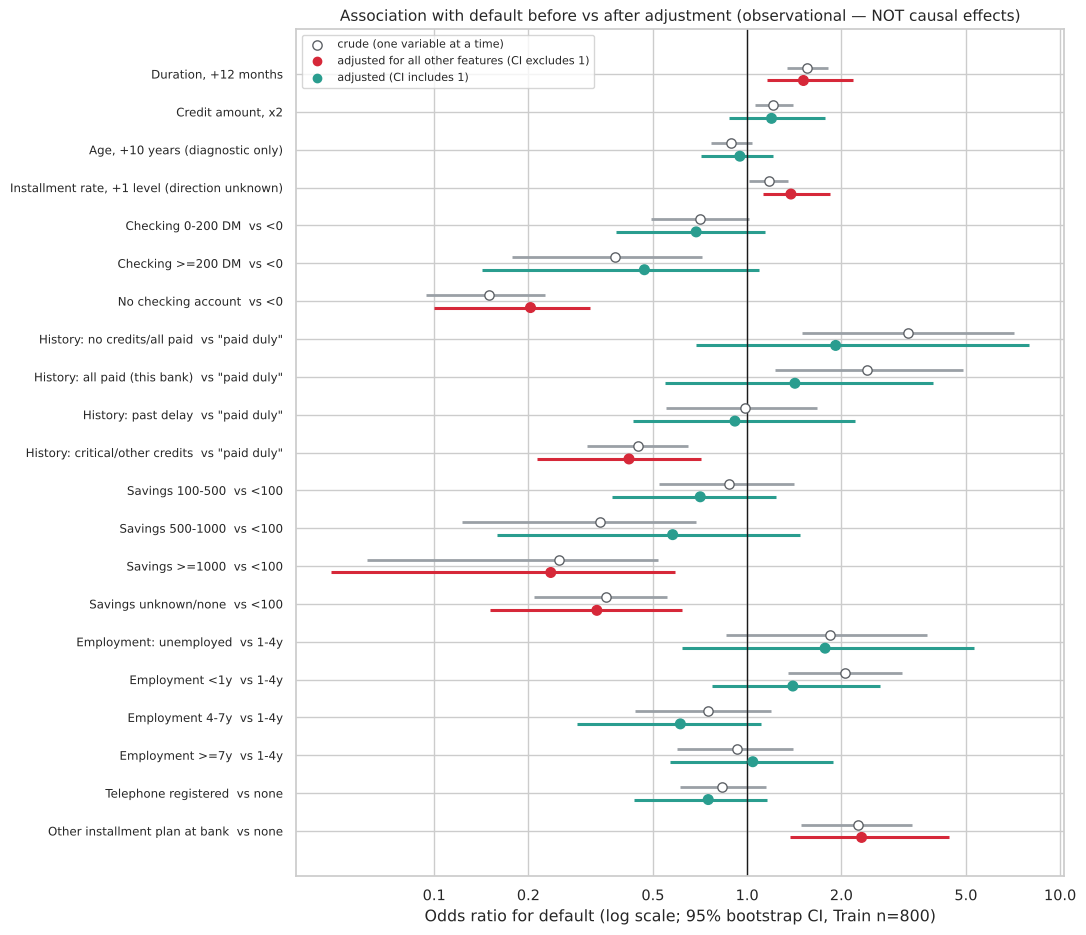

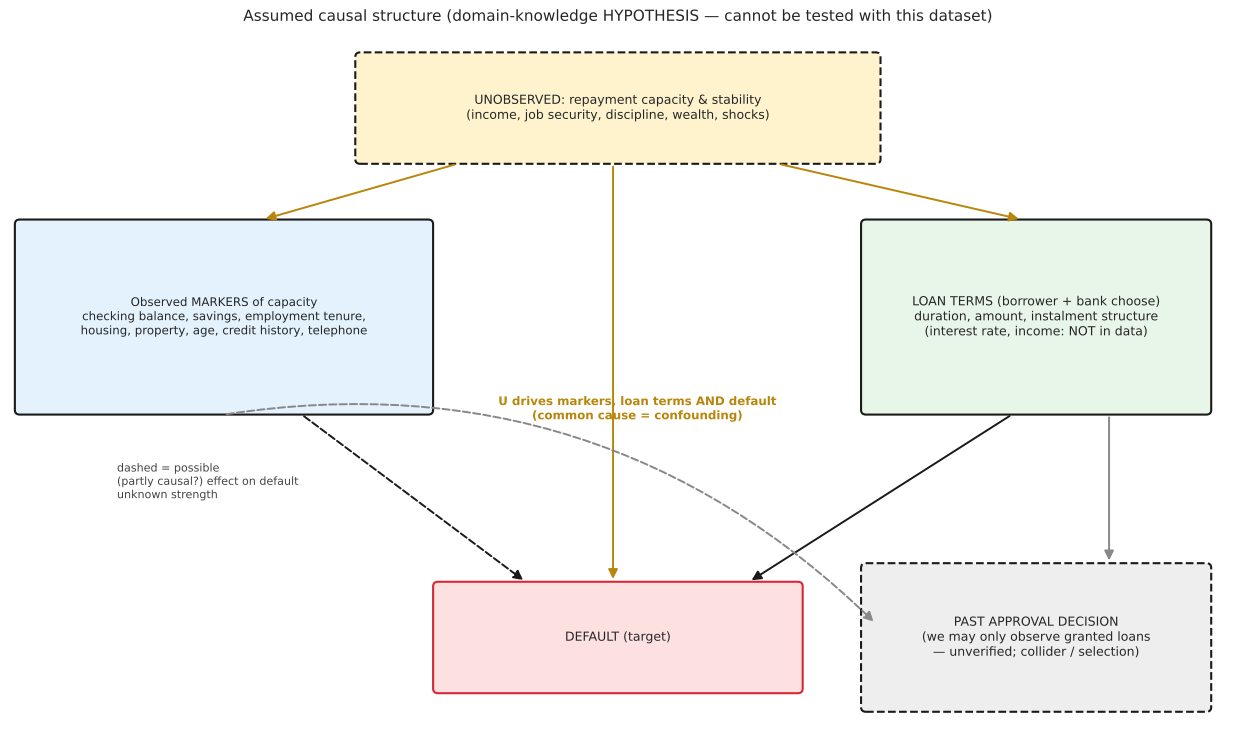

In [39]:
# ---- 8.3 figures: crude vs adjusted forest plot; assumed causal diagram (a HYPOTHESIS) ---------------------------------------------------------------------------------------------------------------------------------------------------------
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
lab_or = {"duration (+12 months)": "Duration, +12 months", "credit amount (x2)": "Credit amount, x2", "age (+10 years)": "Age, +10 years (diagnostic only)", "installment_rate (+1 level)": "Installment rate, +1 level (direction unknown)",
 "checking_status_A12": "Checking 0-200 DM  vs <0", "checking_status_A13": "Checking >=200 DM  vs <0", "checking_status_A14": "No checking account  vs <0", "credit_history_A30": 'History: no credits/all paid  vs "paid duly"',
 "credit_history_A31": 'History: all paid (this bank)  vs "paid duly"', "credit_history_A33": 'History: past delay  vs "paid duly"', "credit_history_A34": 'History: critical/other credits  vs "paid duly"',
 "savings_status_A62": "Savings 100-500  vs <100", "savings_status_A63": "Savings 500-1000  vs <100", "savings_status_A64": "Savings >=1000  vs <100", "savings_status_A65": "Savings unknown/none  vs <100",
 "employment_since_A71": "Employment: unemployed  vs 1-4y", "employment_since_A72": "Employment <1y  vs 1-4y", "employment_since_A74": "Employment 4-7y  vs 1-4y", "employment_since_A75": "Employment >=7y  vs 1-4y",
 "telephone_A192": "Telephone registered  vs none", "other_installment_plans_A141": "Other installment plan at bank  vs none"}
T_ = ORT.iloc[::-1].reset_index(drop=True); yy_ = np.arange(len(T_)); fig, ax = plt.subplots(figsize=(11, 9.5))
ax.hlines(yy_ + 0.17, T_.crude_lo, T_.crude_hi, color="#9aa0a6", lw=2); ax.scatter(T_.OR_crude, yy_ + 0.17, facecolor="white", edgecolor="#5f6368", s=45, zorder=4, label="crude (one variable at a time)")
cc = np.where(T_.adj_CI_excludes_1, "#d62839", "#2a9d8f"); ax.hlines(yy_ - 0.17, T_.adj_lo, T_.adj_hi, color=cc, lw=2.2); ax.scatter(T_.OR_adj, yy_ - 0.17, c=cc, s=48, zorder=5)
ax.scatter([], [], c="#d62839", label="adjusted for all other features (CI excludes 1)"); ax.scatter([], [], c="#2a9d8f", label="adjusted (CI includes 1)")
ax.axvline(1, c="k", lw=1); ax.set_xscale("log"); ax.set_xticks([.1, .2, .5, 1, 2, 5, 10]); ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
ax.set_yticks(yy_); ax.set_yticklabels([lab_or[t] for t in T_.term], fontsize=8.5); ax.set_xlabel("Odds ratio for default (log scale; 95% bootstrap CI, Train n=800)")
ax.set_title("Association with default before vs after adjustment (observational — NOT causal effects)", fontsize=11); ax.legend(fontsize=8, loc="upper left"); savefig("fig24_crude_vs_adjusted_OR.png")

fig, ax = plt.subplots(figsize=(12.5, 7.6)); ax.set_xlim(0, 12.5); ax.set_ylim(0, 7.6); ax.axis("off")
def box(x, y, w, h, t, fc, ec="k", ls="-", fs=9): ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=fc, ec=ec, ls=ls, lw=1.5)); ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=fs)
def arr(a, b, ls="-", c="k", rad=0.0): ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=14, lw=1.4, ls=ls, color=c, connectionstyle=f"arc3,rad={rad}"))
box(3.6, 6.2, 5.3, 1.1, "UNOBSERVED: repayment capacity & stability\n(income, job security, discipline, wealth, shocks)", "#fff3cd", ls="--")
box(0.1, 3.5, 4.2, 2.0, "Observed MARKERS of capacity\nchecking balance, savings, employment tenure,\nhousing, property, age, credit history, telephone", "#e3f2fd", fs=8.5)
box(8.8, 3.5, 3.5, 2.0, "LOAN TERMS (borrower + bank choose)\nduration, amount, instalment structure\n(interest rate, income: NOT in data)", "#e8f5e9")
box(4.4, 0.5, 3.7, 1.1, "DEFAULT (target)", "#fde0e0", ec="#d62839"); box(8.8, 0.3, 3.5, 1.5, "PAST APPROVAL DECISION\n(we may only observe granted loans\n— unverified; collider / selection)", "#eeeeee", ls="--")
arr((4.6, 6.15), (2.6, 5.55), c="#b8860b"); arr((7.9, 6.15), (10.4, 5.55), c="#b8860b"); arr((6.2, 6.15), (6.2, 1.65), c="#b8860b"); arr((3.0, 3.45), (5.3, 1.65), ls="--"); arr((10.3, 3.45), (7.6, 1.65))
arr((2.2, 3.45), (8.9, 1.2), ls="--", c="#888888", rad=-0.25); arr((11.3, 3.45), (11.3, 1.85), c="#888888")
ax.text(1.1, 2.55, "dashed = possible\n(partly causal?) effect on default\nunknown strength", fontsize=8, color="#444"); ax.text(6.45, 3.4, "U drives markers, loan terms AND default\n(common cause = confounding)", fontsize=8.5, color="#b8860b", ha="center", fontweight="bold")
ax.set_title("Assumed causal structure (domain-knowledge HYPOTHESIS — cannot be tested with this dataset)", fontsize=11); savefig("fig25_assumed_causal_diagram.png")

### 8.4 Short answer (text cell required by the brief)

**Q1 — Which variables are probable risk drivers and which are only statistical markers?**
With observational data none can be declared causal. **Plausible risk drivers** (a mechanism exists, the association survives adjustment, in principle modifiable): the **loan term** (longer exposure) and the **instalment burden**; even here borrowers with weaker capacity may *choose* longer loans (self-selection). **Markers of repayment capacity / stability** (probably effects of an unobserved common cause, i.e. confounded): checking balance, savings, employment tenure, housing/property, telephone and **age** — age is mixed with job tenure and wealth and shows no clear independent effect after adjustment (the "age or education itself prevents default?" question of the brief: no evidence for a direct effect; education is not in the data). **Counter-intuitive, suspected selection effects**: "no checking account", "critical account / other credits" and "unknown savings" all look *protective* even after adjustment; they may reflect how customers entered the sample, not a protective mechanism. **Unstable after adjustment**: credit amount (collinear with duration) and short job tenure.

**Q2 — Where may a risk manager intervene?**
Only on **bank-controlled levers that exist in the data**: term, amount/instalment structure, guarantor/collateral requirements and product design — and ideally through a small **randomised pilot** (e.g. offering a shorter-term counter-offer to borderline applicants). Interest rate, credit limit, income and DTI are **not in the data**, so rate/limit policies cannot be evaluated. Relying on purely correlated markers is dangerous: changing a marker (phone, account type, history category) does not change the latent cause (confounding), customers can game visible rules (Goodhart), the applicant mix shifts once a policy changes, markers can act as **proxies for protected attributes** (tested in 7.2), and if only granted loans were observed (unverified) policies outside the observed region have no evidence. **Needed for causal decisions:** randomised or quasi-experimental variation (pilots, regression discontinuity around the score cut-off, officer-leniency instruments), outcomes of rejected applicants (reject inference), income / DTI / rate / fees, longitudinal customer data, and domain-expert review of the causal diagram.

In [40]:
# ---- 8.5 the same answer with the numbers computed in this run ------------------------------------------------------------------------------------------------------------------------------------------
g = lambda t: ORT.set_index("term").loc[t]; f2 = lambda v: f"{v:.2f}"
display(Markdown(f"""**Numbers behind the answer (computed above, Train n={n_c}, bootstrap B={Bc}):**
- Loan term, +12 months: OR crude **{f2(g('duration (+12 months)').OR_crude)}** → adjusted **{f2(g('duration (+12 months)').OR_adj)}** [{f2(g('duration (+12 months)').adj_lo)}, {f2(g('duration (+12 months)').adj_hi)}], E-value {f2(g('duration (+12 months)').E_value_point)}.
- Age, +10 years: crude {f2(g('age (+10 years)').OR_crude)} → adjusted {f2(g('age (+10 years)').OR_adj)} [{f2(g('age (+10 years)').adj_lo)}, {f2(g('age (+10 years)').adj_hi)}] — no clear independent effect.
- No checking account vs <0 DM: crude {f2(g('checking_status_A14').OR_crude)} → adjusted **{f2(g('checking_status_A14').OR_adj)}** [{f2(g('checking_status_A14').adj_lo)}, {f2(g('checking_status_A14').adj_hi)}], E-value {f2(g('checking_status_A14').E_value_point)} — robust *association*, counter-intuitive, not a causal claim.
- History 'critical/other credits' vs 'paid duly': crude {f2(g('credit_history_A34').OR_crude)} → adjusted {f2(g('credit_history_A34').OR_adj)} [{f2(g('credit_history_A34').adj_lo)}, {f2(g('credit_history_A34').adj_hi)}].
- Credit amount (x2): adjusted {f2(g('credit amount (x2)').OR_adj)} [{f2(g('credit amount (x2)').adj_lo)}, {f2(g('credit amount (x2)').adj_hi)}] — interval includes 1 once duration is accounted for."""))

**Numbers behind the answer (computed above, Train n=800, bootstrap B=500):**
- Loan term, +12 months: OR crude **1.55** → adjusted **1.51** [1.15, 2.18], E-value 1.76.
- Age, +10 years: crude 0.89 → adjusted 0.95 [0.71, 1.21] — no clear independent effect.
- No checking account vs <0 DM: crude 0.15 → adjusted **0.20** [0.10, 0.32], E-value 3.86 — robust *association*, counter-intuitive, not a causal claim.
- History 'critical/other credits' vs 'paid duly': crude 0.45 → adjusted 0.42 [0.21, 0.71].
- Credit amount (x2): adjusted 1.20 [0.88, 1.77] — interval includes 1 once duration is accounted for.

---
# Part 9 — LLM and adverse-action explanation (optional, bonus)

Customers who are declined have the right to understand *why*, in plain language. SHAP numbers are unreadable for them, so the design has three layers: **(1) deterministic code** turns the raw SHAP values into a *customer-safe payload* (themes, strength labels, controllability, allowed actions, uncertainty) — no number is invented by the LLM; **(2) the LLM** (prompt below) only writes the language; **(3) an automatic validator** rejects letters that break the rules. The example customer is **case B** from Part 7. The prompt is in **Persian** because the letters are written in Persian; the rest of the notebook is English.

In [41]:
# ---- 9.1 raw SHAP table + customer-safe payload for case B (deterministic; nothing invented) ------------------------------------------------------------------------------------------------------------------------------
CB = cases["B"]; SB = CB["shap_by_feature_LR"]; PB = CB["profile"]
strength = lambda v: "major" if abs(v) >= 0.30 else "moderate" if abs(v) >= 0.15 else "minor" if abs(v) >= 0.05 else "negligible"
BLOCKS = {"R1": ("loan size and repayment period", ["duration_months", "credit_amount", "credit_per_month"]),
          "R2": ("current-account balance, savings and overall stability signals", ["checking_status", "savings_status", "financial_stability_score"]),
          "R3": ("existing instalment commitments", ["other_installment_plans"]), "R4": ("credit-record category", ["credit_history"])}
FAVOR = ["employment_since", "property", "housing"]
EXCLUDED_FROM_LETTER = {"installment_rate": "meaning/direction of its 1-4 codes is undocumented (D6) -> not explainable to a customer", "telephone": "weak, not a meaningful customer-facing reason and a possible proxy"}
MINOR = [f for f in SB if f not in sum([b[1] for b in BLOCKS.values()], []) + FAVOR + list(EXCLUDED_FROM_LETTER)]
blocks = sorted([(k, t_, f_, sum(SB[x] for x in f_)) for k, (t_, f_) in BLOCKS.items()], key=lambda b: -b[3])
tot = sum(b[3] for b in blocks) + sum(SB[f] for f in FAVOR) + sum(SB[f] for f in EXCLUDED_FROM_LETTER) + sum(SB[f] for f in MINOR)
assert abs(tot - sum(SB.values())) < 1e-9 and abs(CB["base_log_odds"] + sum(SB.values()) - CB["log_odds"]) < 3e-3
raw_shap = dict(case_id=f"B-{CB['test_row_id']}", output_scale="log-odds of default; positive = raises estimated risk", base_value=CB["base_log_odds"], estimated_log_odds=CB["log_odds"],
                shap_values=[dict(feature=k, customer_value=PB.get(k), shap=v) for k, v in sorted(SB.items(), key=lambda kv: -abs(kv[1]))])
display(pd.DataFrame(raw_shap["shap_values"]).round(3)); print("reconciliation: base + sum(SHAP) = %.3f  vs  estimated log-odds %.3f" % (CB["base_log_odds"] + sum(SB.values()), CB["log_odds"]))
print("blocks:", [(k, round(n, 3), strength(n)) for k, t_, f_, n in blocks], "\nexcluded from the letter:", EXCLUDED_FROM_LETTER)

# model-based what-if for recourse advice (illustrative, other features fixed; NOT causal)
rowB = Xte.loc[[CB["test_row_id"]]]; scB = lambda **kw: float(lr_final.predict_proba(rowB.assign(**kw))[:, 1][0])
WI = [("current request", {}), ("term 36 months", dict(duration_months=36)), ("term 24 months", dict(duration_months=24)), ("term 12 months", dict(duration_months=12)), ("amount 9,000 DM (same term)", dict(credit_amount=9000)), ("amount 6,000 DM (same term)", dict(credit_amount=6000)),
      ("no other instalment plan", dict(other_installment_plans="A143")), ("savings 500-1000 DM", dict(savings_status="A63")), ("24 months + no other plan", dict(duration_months=24, other_installment_plans="A143")),
      ("24 months + no other plan + savings 500-1000", dict(duration_months=24, other_installment_plans="A143", savings_status="A63")), ("12 months + no other plan + savings 500-1000", dict(duration_months=12, other_installment_plans="A143", savings_status="A63"))]
WIT = pd.DataFrame([dict(scenario=n, score=scB(**kw), below_base_line=scB(**kw) < T5, below_mild_line=scB(**kw) < TMILD) for n, kw in WI]); display(WIT.round(3))
print("note: reducing the AMOUNT alone does not lower the estimate (credit_per_month offsets it), so a smaller loan is NOT offered as a lever; no single change crosses the line.")

# honest uncertainty: observed repayment-problem rate among past customers with a similar score (Train OOF)
lo_b, hi_b = CB["score_LR"] - 0.10, CB["score_LR"] + 0.10; Sc = OOF["LR"]; mband = [(Sc[r] >= lo_b) & (Sc[r] < hi_b) for r in range(3)]; rate = float(np.mean([y_tr[x].mean() for x in mband]))
rg = np.random.default_rng(SEED); bs = []
for _ in range(200 if FAST else 2000):
    i = rg.integers(0, n_tr, n_tr); bs.append(np.mean([y_tr[i][(Sc[r][i] >= lo_b) & (Sc[r][i] < hi_b)].mean() for r in range(3)]))
ci_b = (float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5)))
print(f"similar past customers (score in [{lo_b:.2f},{hi_b:.2f}), avg n={np.mean([x.sum() for x in mband]):.0f}): observed repayment-problem rate {rate:.3f} (95% CI {ci_b[0]:.3f}-{ci_b[1]:.3f}) -> about {round(rate*10)} in 10")
print("precision among ALL rejected at the base threshold (OOF):", round(float(np.mean([y_tr[OOF['LR'][r] >= T5].mean() for r in range(3)])), 3))

,feature,customer_value,shap
0,duration_months,48.0,0.559
1,credit_amount,18424.0,0.410
2,other_installment_plans,A141 (bank),0.348
3,credit_per_month,383.8,-0.324
4,installment_rate,1.0,-0.255
5,credit_history,A30 (no credits/all paid),0.230
6,checking_status,A12 (0-200 DM),0.220
7,financial_stability_score,1,0.187
8,savings_status,A61 (<100 DM),0.137
9,telephone,A192 (yes),-0.095


reconciliation: base + sum(SHAP) = 0.315  vs  estimated log-odds 0.314
blocks: [('R1', 0.645, 'major'), ('R2', 0.544, 'major'), ('R3', 0.348, 'major'), ('R4', 0.23, 'moderate')] 
excluded from the letter: {'installment_rate': 'meaning/direction of its 1-4 codes is undocumented (D6) -> not explainable to a customer', 'telephone': 'weak, not a meaningful customer-facing reason and a possible proxy'}


,scenario,score,below_base_line,below_mild_line
0,current request,0.578,False,False
1,term 36 months,0.495,False,False
2,term 24 months,0.403,False,False
3,term 12 months,0.299,False,False
4,"amount 9,000 DM (same term)",0.597,False,False
5,"amount 6,000 DM (same term)",0.607,False,False
6,no other instalment plan,0.473,False,False
7,savings 500-1000 DM,0.441,False,False
8,24 months + no other plan,0.307,False,False
9,24 months + no other plan + savings 500-1000,0.204,False,True


note: reducing the AMOUNT alone does not lower the estimate (credit_per_month offsets it), so a smaller loan is NOT offered as a lever; no single change crosses the line.
similar past customers (score in [0.48,0.68), avg n=123): observed repayment-problem rate 0.616 (95% CI 0.527-0.702) -> about 6 in 10
precision among ALL rejected at the base threshold (OOF): 0.4


In [42]:
# ---- 9.2 customer-safe payload (this, plus the raw SHAP table, is what the LLM receives) -------------------------------------------------------------------------------------------------------------------------------------------------
facts = {"R1": [f"requested repayment period: {int(PB['duration_months'])} months", f"requested amount: {int(PB['credit_amount']):,} DM", "the requested amount is the largest loan amount in the whole development data"],
         "R2": ["current-account balance level on file: 0-200 DM", "savings on file: under 100 DM", "of five stability signals checked (job tenure 4+ years, own home, real-estate asset, savings 500+ DM, account 200+ DM or salary assignment) only one is met (own home)"],
         "R3": ["customer has another instalment plan with a bank"],
         "R4": ['credit-record category on file: "no credits taken / all credits repaid duly"', "in past data this category was associated with higher-than-average repayment problems; this is a statistical pattern, not a judgement of the customer behaviour"]}
ctrl = {"R1": ("controllable_by_customer", "shorter term is controllable; amount alone is NOT shown to help by the model (do not advise a smaller amount as a way to improve the assessment)", ["A1"]),
        "R2": ("partly_controllable_over_months", "building savings and a steadier balance takes months", ["A3", "A4"]), "R3": ("partly_controllable", "by reducing or repaying existing plans", ["A2"]),
        "R4": ("not_quickly_controllable", "changes slowly with time and on-time repayment", ["A7"])}
reasons = [dict(id=k, theme=t_, strength=strength(n), direction="raises estimated risk", customer_facts=facts[k], controllability=ctrl[k][0], controllability_note=ctrl[k][1], linked_actions=ctrl[k][2]) for k, t_, f_, n in blocks]
fav_txt = {"employment_since": "current job tenure of 1-4 years", "property": "has a savings-agreement/insurance-type asset", "housing": "owns their home"}
ACTIONS = [dict(id="A1", text="apply for a shorter repayment period", evidence="model-supported: among loan-structure changes it lowered the estimated risk the most in internal tests, but not enough on its own"),
 dict(id="A2", text="reduce or fully repay other instalment commitments before re-applying", evidence="model-supported: lowered the estimated risk in internal tests, not enough on its own"),
 dict(id="A3", text="build up savings gradually (currently under 100 DM)", evidence="model-supported: a higher savings level lowered the estimated risk in internal tests"),
 dict(id="A4", text="keep the current-account balance higher and steadier (currently 0-200 DM)", evidence="model-supported: a higher balance level lowered the estimated risk in internal tests"),
 dict(id="A5", text="combination: only a combination of changes (a clearly shorter term, no other instalment plan, higher savings) brought the internal estimate close to or below the approval line; no single change did. This is NOT a guarantee of approval", evidence="internal what-if test, illustrative only"),
 dict(id="A6", text="provide additional information the assessment cannot see (for example income or other circumstances) and ask for a person to review the application", evidence="general process; bank has confirmed a human review is available (demo assumption)"),
 dict(id="A7", text="keep paying all obligations on time; the credit record changes slowly with time", evidence="general good practice, not measured by the model")]
payload = dict(case_id=raw_shap["case_id"], output_language="fa (Persian)",
  decision=dict(outcome="request not approved in its current form", type="automated statistical assessment (not a final judgement about the person)", assessment_level="clearly above the bank approval line"),
  request=dict(amount_DM=int(PB["credit_amount"]), term_months=int(PB["duration_months"]), purpose="other (unspecified)"), principal_reasons_in_order=reasons,
  small_factors_in_customer_favour=[fav_txt[f] for f, _ in sorted([(f, SB[f]) for f in FAVOR], key=lambda x: x[1])], not_quickly_changeable=["credit-record category", "job tenure"], allowed_actions=ACTIONS,
  actions_NOT_to_suggest=["smaller loan amount as a way to improve the assessment (model does not support it)", "anything about age, sex, nationality, phone, accounts relabelling"],
  uncertainty=dict(similar_past_customers_with_repayment_problems_per_10="about 6 (plausible range 5 to 7)", similar_past_customers_who_repaid_per_10="about 4", basis="past customers with a similar assessment in the development sample",
                   not_seen_by_assessment=["income", "debts held elsewhere", "personal circumstances"], statistical_patterns_not_causes=True, assessment_can_be_wrong=True),
  bank_provided_facts=dict(human_review_available=True, contact_details="[اطلاعات تماس بانک]  (placeholder; the bank must insert real details)"),
  allowed_numbers_in_letter=[int(PB["credit_amount"]), int(PB["duration_months"]), 100, 200, 0, 1, 4, 5, 6, 7, 10], style=dict(tone="respectful, calm, non-blaming", max_words=350, no_jargon=True, format="short paragraphs and bullet lists; no numbered lists; no tables"))
json.dump(payload, open(RES / "adverse_action_payload_customer.json", "w"), indent=1, ensure_ascii=False); json.dump(raw_shap, open(RES / "adverse_action_payload_raw_shap.json", "w"), indent=1, ensure_ascii=False)
print("uncertainty statement in the payload vs computed:", f"'about 6 in 10' vs observed {rate:.2f} (CI {ci_b[0]:.2f}-{ci_b[1]:.2f})")
print(json.dumps({k: payload[k] for k in ["decision", "request", "small_factors_in_customer_favour"]}, indent=1, ensure_ascii=False))

uncertainty statement in the payload vs computed: 'about 6 in 10' vs observed 0.62 (CI 0.53-0.70)
{
 "decision": {
  "outcome": "request not approved in its current form",
  "type": "automated statistical assessment (not a final judgement about the person)",
  "assessment_level": "clearly above the bank approval line"
 },
 "request": {
  "amount_DM": 18424,
  "term_months": 48,
  "purpose": "other (unspecified)"
 },
 "small_factors_in_customer_favour": [
  "current job tenure of 1-4 years",
  "has a savings-agreement/insurance-type asset",
  "owns their home"
 ]
}


### 9.3 The prompt (Persian) — System part

Ten hard rules; each requirement of the brief is mapped to one: respectful & jargon-free (1–2), concrete practical advice from an allow-list (3), no invented information (4), controllable vs non-controllable (5), uncertainty (6), not a final verdict (7–8), plus fairness (9) and length/format (10).

In [43]:
# ---- 9.3 SYSTEM prompt text (Persian)
PROMPT_FA = r'''شما نویسنده «توضیح تصمیم اعتباری» برای یک بانک/لندتک هستید. ورودی شما خروجی عددی SHAP یک مشتری ردشده و خلاصه‌ی ساخت‌یافته‌ی تأییدشده‌ی آن است. وظیفه‌ی شما نوشتن یک نامه‌ی کوتاه، محترمانه و ساده برای خود مشتری است.

### ورودی‌ها
- `RAW_SHAP`: جدول عددی خام (ویژگی، مقدار مشتری، مقدار SHAP). **فقط برای ردیابی و درک ترتیب اهمیت است. هیچ عددی از آن را در نامه ننویسید.**
- `CUSTOMER_PAYLOAD`: خلاصه‌ی تأییدشده شامل دلایل اصلی به‌ترتیب، نکات به نفع مشتری، اقدام‌های مجاز، میزان عدم‌قطعیت و اعداد مجاز. **تنها منبع حقیقت برای نامه همین است.**

### قوانین سخت (نقض هرکدام یعنی پاسخ نامعتبر است)
۱. **لحن:** محترمانه، آرام، بدون سرزنش و بدون ترس‌افکنی. مشتری را «مشتری پرریسک/بدحساب» نخوانید.
۲. **بدون اصطلاح فنی:** از واژه‌های SHAP، لگاریتم شانس، مدل، الگوریتم، ضریب، رگرسیون، نکول، احتمال و درصد استفاده نکنید. به‌جای آن‌ها زبان روزمره بنویسید («ارزیابی آماری»، «ریسک برآوردی»).
۳. **راهکار عملی:** فقط از میان `allowed_actions` انتخاب کنید و هر راهکار را با زبان ساده و مشخص بنویسید. هرگز چیزی از `actions_NOT_to_suggest` را پیشنهاد ندهید.
۴. **جلوگیری از اطلاعات غیرواقعی:** هر ادعا باید مستقیماً در `CUSTOMER_PAYLOAD` باشد. هیچ عدد، مبلغ، مهلت، نرخ، قانون، نام، شماره تلفن یا آدرسی نسازید. فقط اعداد موجود در `allowed_numbers_in_letter` مجازند. برای اطلاعات تماس بانک دقیقاً همان placeholder داده‌شده را بنویسید. اگر اطلاعاتی در ورودی نیست، ننویسید.
۵. **تفکیک کنترل‌پذیر و غیرقابل‌کنترل:** دو بخش جدا بنویسید: «آنچه در اختیار شماست» و «آنچه سریع قابل تغییر نیست». دسته‌بندی هر دلیل را از `controllability` بردارید.
۶. **عدم‌قطعیت:** بخش `uncertainty` را به زبان ساده بیان کنید («حدود ۶ نفر از هر ۱۰ نفر…»)، بگویید ارزیابی چه چیزهایی را نمی‌بیند، و صریح بگویید ممکن است ارزیابی درباره او درست نباشد.
۷. **حکم قطعی نه:** تصمیم را «ارزیابی خودکار آماری» معرفی کنید، نه حکم نهایی درباره‌ی شخص. امکان بازبینی توسط کارشناس را فقط اگر `human_review_available` درست است بنویسید. وعده یا تضمین تأیید ندهید.
۸. **همبستگی، نه علت:** از عبارت‌هایی مثل «در داده‌های گذشته با … همراه بوده» استفاده کنید؛ هرگز نگویید «شما به این دلیل نکول می‌کنید».
۹. **انصاف:** هرگز به ویژگی‌های حفاظت‌شده یا جانشین آن‌ها (سن، جنسیت، وضعیت تأهل، ملیت/تابعیت، تلفن و …) اشاره نکنید. اگر چنین ویژگی‌ای در ورودی دیدید، نادیده بگیرید و در `notes_for_reviewer` گزارش کنید.
۱۰. **حداکثر ۴ دلیل اصلی**، به همان ترتیب `principal_reasons_in_order`، هرکدام ۱ تا ۲ جمله. طول کل نامه حداکثر ۳۵۰ کلمه. فقط فارسی روان؛ مبلغ‌ها با «DM». فهرست شماره‌دار و جدول ننویسید (از بولت استفاده کنید).

### ساختار نامه (به همین ترتیب)
سلام و جمله‌ی تصمیم ← مهم‌ترین دلایل ← نکات به نفع شما ← آنچه در اختیار شماست ← آنچه سریع قابل تغییر نیست ← این ارزیابی چقدر قطعی است؟ ← گام بعدی (با placeholder تماس).

### خروجی (فقط JSON معتبر، بدون متن اضافه)
```json
{
  "customer_letter": "متن کامل نامه",
  "trace": {"reasons_used": ["R1"], "actions_used": ["A1"], "favourable_used": true, "uncertainty_used": true},
  "notes_for_reviewer": ["هر نکته‌ای که کارشناس باید بداند"]
}
```

### خودبازبینی پیش از پاسخ
هر جمله را با `CUSTOMER_PAYLOAD` تطبیق دهید؛ هر جمله‌ای که منبع ندارد حذف شود. بررسی کنید: عدد غیرمجاز نیست؛ واژه‌ی فنی یا ویژگی حفاظت‌شده نیست؛ وعده‌ای نیست؛ هر دو بخش کنترل‌پذیر/غیرقابل‌کنترل و عدم‌قطعیت و placeholder تماس هست.'''
print(PROMPT_FA)

شما نویسنده «توضیح تصمیم اعتباری» برای یک بانک/لندتک هستید. ورودی شما خروجی عددی SHAP یک مشتری ردشده و خلاصه‌ی ساخت‌یافته‌ی تأییدشده‌ی آن است. وظیفه‌ی شما نوشتن یک نامه‌ی کوتاه، محترمانه و ساده برای خود مشتری است.

### ورودی‌ها
- `RAW_SHAP`: جدول عددی خام (ویژگی، مقدار مشتری، مقدار SHAP). **فقط برای ردیابی و درک ترتیب اهمیت است. هیچ عددی از آن را در نامه ننویسید.**
- `CUSTOMER_PAYLOAD`: خلاصه‌ی تأییدشده شامل دلایل اصلی به‌ترتیب، نکات به نفع مشتری، اقدام‌های مجاز، میزان عدم‌قطعیت و اعداد مجاز. **تنها منبع حقیقت برای نامه همین است.**

### قوانین سخت (نقض هرکدام یعنی پاسخ نامعتبر است)
۱. **لحن:** محترمانه، آرام، بدون سرزنش و بدون ترس‌افکنی. مشتری را «مشتری پرریسک/بدحساب» نخوانید.
۲. **بدون اصطلاح فنی:** از واژه‌های SHAP، لگاریتم شانس، مدل، الگوریتم، ضریب، رگرسیون، نکول، احتمال و درصد استفاده نکنید. به‌جای آن‌ها زبان روزمره بنویسید («ارزیابی آماری»، «ریسک برآوردی»).
۳. **راهکار عملی:** فقط از میان `allowed_actions` انتخاب کنید و هر راهکار را با زبان ساده و مشخص بنویسید. هرگز چیزی از `actio

In [44]:
# ---- 9.4 full prompt = SYSTEM + RAW_SHAP + CUSTOMER_PAYLOAD  (copy `full_prompt` into any LLM chat to reproduce) ---------------------------------------------------------------------------------------------------
full_prompt = (f"### SYSTEM\n{PROMPT_FA}\n\n### USER\nRAW_SHAP:\n{json.dumps(raw_shap, ensure_ascii=False, indent=1)}\n\nCUSTOMER_PAYLOAD:\n{json.dumps(payload, ensure_ascii=False, indent=1)}\n\n"
               "نامه‌ی مشتری را طبق قوانین بنویس و فقط JSON خروجی بده.\n")
(OUT / "adverse_action_full_prompt.txt").write_text(full_prompt, encoding="utf-8"); print("full prompt:", len(full_prompt), "characters; saved to", OUT / "adverse_action_full_prompt.txt")

full prompt: 10802 characters; saved to outputs/adverse_action_full_prompt.txt


### 9.5 Sample LLM output

The letter below is the output of **Claude (an LLM) executing the system prompt above on exactly this payload** — it was written once and pasted here as a fixed string; it was **not** produced by ChatGPT or by an automated API call inside this notebook. Anyone can reproduce or compare by pasting `full_prompt` into an LLM chat. It is then checked by the validator in 9.6.

In [45]:
# ---- 9.5 generated letter (fixed text, produced by an LLM from the prompt above) and the reviewer notes
LETTER_FA = r'''**نتیجه بررسی درخواست وام شما**

سلام و احترام،

از اعتماد شما سپاسگزاریم. در بررسی آماری درخواست شما (وام ۱۸٬۴۲۴ DM با بازپرداخت ۴۸ ماهه)، در شرایط فعلی نتوانستیم آن را تأیید کنیم. این یک ارزیابی خودکار است و حکم قطعی درباره شما نیست.

**مهم‌ترین دلایل (به ترتیب اهمیت)**
- **مبلغ و مدت وام:** مبلغ درخواستی بزرگ و مدت بازپرداخت آن طولانی است. این مورد بیشترین اثر را در بالا بردن ریسک برآوردی داشت.
- **موجودی حساب و پس‌انداز:** موجودی حساب جاری شما ۰ تا ۲۰۰ DM و پس‌انداز کمتر از ۱۰۰ DM ثبت شده است. از پنج نشانه ثبات مالی که بررسی می‌کنیم، فقط یکی (مالکیت خانه) برقرار است.
- **تعهد قسطی دیگر:** یک برنامه اقساطی دیگر نزد بانک برای شما ثبت شده است.
- **طبقه سابقه اعتباری:** این طبقه («بدون وام قبلی یا بازپرداخت به‌موقع همه وام‌ها») در داده‌های گذشته با مشکل بازپرداخت بیشتری همراه بوده است. این الگوی آماری است، نه قضاوت درباره رفتار شما.

**نکات به نفع شما:** سابقه کار فعلی (۱ تا ۴ سال) و داشتن خانه شخصی اثر کوچکی در کاهش ریسک داشتند.

**آنچه در اختیار شماست**
- درخواست مدت بازپرداخت کوتاه‌تر
- کاهش یا تسویه برنامه اقساطی دیگر پیش از درخواست جدید
- افزایش تدریجی پس‌انداز و حفظ موجودی بالاتر در حساب جاری
- ادامه پرداخت به‌موقع همه تعهدات

در آزمون‌های داخلی ما هیچ‌کدام از این تغییرها به‌تنهایی کافی نبود؛ فقط ترکیب چند مورد (مدت بسیار کوتاه‌تر، نبود اقساط دیگر و پس‌انداز بیشتر) برآورد را به خط تأیید نزدیک یا زیر آن برد. این تضمین تأیید نیست.

**آنچه سریع قابل تغییر نیست:** طبقه سابقه اعتباری و سابقه کار؛ این‌ها به‌تدریج و با پرداخت به‌موقع تغییر می‌کنند.

**این ارزیابی چقدر قطعی است؟** این ارزیابی بر الگوهای آماری وام‌های گذشته تکیه دارد و درآمد، بدهی‌های بیرون از بانک و شرایط شخصی شما را نمی‌بیند. در میان مشتریان گذشته با ارزیابی مشابه، حدود ۶ نفر از هر ۱۰ نفر (بین ۵ تا ۷) مشکل بازپرداخت داشتند و حدود ۴ نفر بازپرداخت کردند. پس ممکن است ارزیابی درباره شما درست نباشد.

**گام بعدی:** می‌توانید اطلاعات تکمیلی (مثلاً درآمد) ارائه دهید و از کارشناس بخواهید درخواست را دوباره بررسی کند. [اطلاعات تماس بانک]

با احترام'''
NOTES_FOR_REVIEWER = ['Placeholder [اطلاعات تماس بانک] must be replaced with real contact details.', 'installment_rate and telephone were deliberately not mentioned (undocumented code direction / weak proxy-like feature); see audit_B.json.', 'A smaller loan amount was deliberately NOT suggested: the model does not show it lowers the estimate (credit_per_month offsets it).', 'Generated by Claude executing adverse_action_system_prompt_fa.md on payload_B_*.json; not produced by ChatGPT or an API pipeline.']
display(Markdown(LETTER_FA)); print('\nnotes_for_reviewer:', NOTES_FOR_REVIEWER)

**نتیجه بررسی درخواست وام شما**

سلام و احترام،

از اعتماد شما سپاسگزاریم. در بررسی آماری درخواست شما (وام ۱۸٬۴۲۴ DM با بازپرداخت ۴۸ ماهه)، در شرایط فعلی نتوانستیم آن را تأیید کنیم. این یک ارزیابی خودکار است و حکم قطعی درباره شما نیست.

**مهم‌ترین دلایل (به ترتیب اهمیت)**
- **مبلغ و مدت وام:** مبلغ درخواستی بزرگ و مدت بازپرداخت آن طولانی است. این مورد بیشترین اثر را در بالا بردن ریسک برآوردی داشت.
- **موجودی حساب و پس‌انداز:** موجودی حساب جاری شما ۰ تا ۲۰۰ DM و پس‌انداز کمتر از ۱۰۰ DM ثبت شده است. از پنج نشانه ثبات مالی که بررسی می‌کنیم، فقط یکی (مالکیت خانه) برقرار است.
- **تعهد قسطی دیگر:** یک برنامه اقساطی دیگر نزد بانک برای شما ثبت شده است.
- **طبقه سابقه اعتباری:** این طبقه («بدون وام قبلی یا بازپرداخت به‌موقع همه وام‌ها») در داده‌های گذشته با مشکل بازپرداخت بیشتری همراه بوده است. این الگوی آماری است، نه قضاوت درباره رفتار شما.

**نکات به نفع شما:** سابقه کار فعلی (۱ تا ۴ سال) و داشتن خانه شخصی اثر کوچکی در کاهش ریسک داشتند.

**آنچه در اختیار شماست**
- درخواست مدت بازپرداخت کوتاه‌تر
- کاهش یا تسویه برنامه اقساطی دیگر پیش از درخواست جدید
- افزایش تدریجی پس‌انداز و حفظ موجودی بالاتر در حساب جاری
- ادامه پرداخت به‌موقع همه تعهدات

در آزمون‌های داخلی ما هیچ‌کدام از این تغییرها به‌تنهایی کافی نبود؛ فقط ترکیب چند مورد (مدت بسیار کوتاه‌تر، نبود اقساط دیگر و پس‌انداز بیشتر) برآورد را به خط تأیید نزدیک یا زیر آن برد. این تضمین تأیید نیست.

**آنچه سریع قابل تغییر نیست:** طبقه سابقه اعتباری و سابقه کار؛ این‌ها به‌تدریج و با پرداخت به‌موقع تغییر می‌کنند.

**این ارزیابی چقدر قطعی است؟** این ارزیابی بر الگوهای آماری وام‌های گذشته تکیه دارد و درآمد، بدهی‌های بیرون از بانک و شرایط شخصی شما را نمی‌بیند. در میان مشتریان گذشته با ارزیابی مشابه، حدود ۶ نفر از هر ۱۰ نفر (بین ۵ تا ۷) مشکل بازپرداخت داشتند و حدود ۴ نفر بازپرداخت کردند. پس ممکن است ارزیابی درباره شما درست نباشد.

**گام بعدی:** می‌توانید اطلاعات تکمیلی (مثلاً درآمد) ارائه دهید و از کارشناس بخواهید درخواست را دوباره بررسی کند. [اطلاعات تماس بانک]

با احترام


notes_for_reviewer: ['Placeholder [اطلاعات تماس بانک] must be replaced with real contact details.', 'installment_rate and telephone were deliberately not mentioned (undocumented code direction / weak proxy-like feature); see audit_B.json.', 'A smaller loan amount was deliberately NOT suggested: the model does not show it lowers the estimate (credit_per_month offsets it).', 'Generated by Claude executing adverse_action_system_prompt_fa.md on payload_B_*.json; not produced by ChatGPT or an API pipeline.']


In [46]:
# ---- 9.6 automatic guard-rail validator (heuristic: keywords, numbers, structure — it does not replace human / legal review) -----------------------------------------------------------------------------------------
import re
DIG = str.maketrans("۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩", "01234567890123456789"); FA = "\u0600-\u06FF\u200c"
wb = lambda word: rf"(?<![{FA}A-Za-z]){word}(?![{FA}A-Za-z])"
FORBID = {"technical jargon": [wb("SHAP"), wb("شپ"), "لگاریتم", "log-odds", wb("XGBoost"), wb("Logistic"), "لجستیک", "رگرسیون", wb("ضریب"), "الگوریتم", wb("مدل"), wb("نکول"), "احتمال"],
          "protected / proxy attribute": [wb("سن"), "ساله", "جنسیت", wb("زن"), wb("مرد"), "متأهل", "متاهل", "مجرد", "ملیت", "تابعیت", "خارجی", "نژاد", "مذهب", "تلفن"],
          "undocumented feature (installment rate)": ["نرخ قسط", "درصد از درآمد"], "percent / invented rate": ["%", "درصد"], "promise / certainty": ["تضمین می", "قطعاً", "حتماً", "مطمئن باشید"], "labelling the person": ["بدحساب", "پرریسک", "ناتوان"]}
REQUIRE = {"states it is an automated assessment": ["ارزیابی خودکار"], "not a final verdict": ["حکم قطعی"], "controllable section": ["در اختیار شماست"], "non-controllable section": ["سریع قابل تغییر نیست"],
           "uncertainty: may be wrong": ["درست نباشد"], "bank contact placeholder": ["[اطلاعات تماس بانک]"], "covers loan term/amount": ["مدت"], "covers savings/balance": ["پس‌انداز"], "covers instalments": ["اقساط"],
           "covers credit record": ["سابقه اعتباری"], "covers a 6-in-10 uncertainty fact": ["۶ نفر از هر ۱۰"]}
nums = lambda t: [int(x) for x in re.findall(r"\d+", t.translate(DIG).replace("٬", "").replace(",", ""))]
def check_letter(letter, pl):
    allowed = set(pl["allowed_numbers_in_letter"]); fails = []
    for cat, pats in FORBID.items():
        for p in pats:
            m = re.search(p, letter)
            if m: fails.append(f"FORBIDDEN [{cat}]: '{m.group(0)}'")
    for cat, pats in REQUIRE.items():
        if not any(p in letter for p in pats): fails.append(f"MISSING [{cat}]")
    bad = sorted(set(n for n in nums(letter) if n not in allowed))
    if bad: fails.append(f"NUMBERS not in payload allow-list: {bad}")
    wc = len([x for x in letter.split() if re.search(rf"[\w{FA}]", x)])
    if wc > pl["style"]["max_words"]: fails.append(f"TOO LONG: {wc} > {pl['style']['max_words']} words")
    if re.search(r"^\s*\d+[\.\)]\s", letter, re.M): fails.append("numbered list used")
    return fails, wc
f_, wc_ = check_letter(LETTER_FA, payload)
print("GENERATED LETTER ->", "PASSED" if not f_ else "FAILED", f"| words {wc_} | numbers used {sorted(set(nums(LETTER_FA)))}"); [print("  ", x) for x in f_]
if (PB["credit_amount"], PB["duration_months"]) != (18424, 48): print("WARNING: this run selected a different case B than the one the fixed letter was written for.")
BAD = {"mentions age + jargon + invented percent + promise": LETTER_FA.replace("ارزیابی خودکار", "ارزیابی SHAP").replace("مدت بازپرداخت", "سن شما و مدت بازپرداخت").replace("حدود ۶ نفر از هر ۱۰ نفر", "۳۵ درصد").replace("این تضمین تأیید نیست.", "حتماً تأیید می‌شوید."),
       "missing placeholder + no uncertainty": LETTER_FA.replace("[اطلاعات تماس بانک]", "").replace("پس ممکن است ارزیابی درباره شما درست نباشد.", ""),
       "invented number (interest rate 9)": LETTER_FA.replace(f"وام ۱۸٬۴۲۴ DM", "وام ۱۸٬۴۲۴ DM با نرخ سود ۹ درصد"), "labels person + sex": LETTER_FA.replace("نتوانستیم آن را تأیید کنیم", "نتوانستیم آن را تأیید کنیم چون شما یک مشتری پرریسک و زن هستید")}
unit = {}
for k, t_ in BAD.items():
    ff, _ = check_letter(t_, payload); unit[k] = dict(caught=bool(ff), failures=ff); print(f"UNIT TEST '{k}': caught = {bool(ff)}")
json.dump(dict(generated_letter=dict(passed=not f_, failures=f_, words=wc_), unit_tests_bad_letters=unit), open(RES / "adverse_action_checks.json", "w"), ensure_ascii=False, indent=1)

GENERATED LETTER -> PASSED | words 348 | numbers used [0, 1, 4, 5, 6, 7, 10, 48, 100, 200, 18424]
UNIT TEST 'mentions age + jargon + invented percent + promise': caught = True
UNIT TEST 'missing placeholder + no uncertainty': caught = True
UNIT TEST 'invented number (interest rate 9)': caught = True
UNIT TEST 'labels person + sex': caught = True


---
# Part 10 — Summary, limitations and audit trail

In [47]:
# ---- 10.1 final summary (all numbers computed in this run) and machine-readable results for the executive report -------------------------------------------------------------------------------------------------------------------------------------
ts = TESTM[(TESTM.rule == "T*")].set_index("model"); oo = OOFM[OOFM.rule == "T*"].set_index("model")
summary = dict(seed=SEED, fast_mode=FAST, n=1000, n_train=len(Xtr), n_test=len(Xte), bad_rate=float(y_all.mean()), selected_model=SEL_M, excluded_inputs=EXCLUDE,
    thresholds=TH, mild_thresholds=TM, honest_cost={m: res[m]["honest_oob_cost"] for m in MODELS}, nested_auc={m: float(NEST[NEST.model == m].auc.mean()) for m in MODELS},
    oof_auc={m: float(OOFA.loc[m, "roc_auc"]) for m in MODELS}, test_auc={m: float(ts.loc[m, "roc_auc"]) for m in MODELS}, test_cost={m: float(ts.loc[m, "cost_per_applicant"]) for m in MODELS}, oof_cost={m: float(oo.loc[m, "cost_per_applicant"]) for m in MODELS},
    baselines=dict(reject_all=CFP * (1 - y_tr.mean()), approve_all=CFN * y_tr.mean()), global_importance_top10=imp.head(10).round(4).to_dict(), proxy_check=PROXY.set_index("target").cv_auc.round(3).to_dict(),
    letter_check_passed=not f_, test_touched_flag=TEST_TOUCHED)
json.dump(summary, open(RES / "summary.json", "w"), indent=1, default=float)
print(json.dumps({k: summary[k] for k in ["selected_model", "excluded_inputs", "thresholds", "mild_thresholds", "baselines", "letter_check_passed"]}, indent=1))
display(pd.DataFrame({"nested AUC": summary["nested_auc"], "OOF AUC": summary["oof_auc"], "Test AUC": summary["test_auc"], "honest cost": summary["honest_cost"], "OOF cost @T*": summary["oof_cost"], "Test cost @T*": summary["test_cost"]}).round(3))
print("results files written to", RES.resolve()); print("figures written to", FIG.resolve())

{
 "selected_model": "LR",
 "excluded_inputs": [
  "personal_status_sex",
  "age",
  "foreign_worker"
 ],
 "thresholds": {
  "DT": 0.23,
  "LR": 0.2,
  "RF": 0.24,
  "XGB": 0.21
 },
 "mild_thresholds": {
  "DT": 0.49,
  "LR": 0.25,
  "RF": 0.32,
  "XGB": 0.43
 },
 "baselines": {
  "reject_all": 0.7,
  "approve_all": 1.5
 },
 "letter_check_passed": true
}


,nested AUC,OOF AUC,Test AUC,honest cost,OOF cost @T*,Test cost @T*
DT,0.744,0.736,0.752,0.591,0.577,0.575
LR,0.773,0.776,0.776,0.564,0.540,0.610
RF,0.795,0.793,0.794,0.538,0.517,0.555
XGB,0.785,0.795,0.786,0.537,0.516,0.580


results files written to /mnt/user-data/outputs/final/outputs/results
figures written to /mnt/user-data/outputs/final/outputs/figures


## Limitations (stated explicitly)

* **Small, old, single-country sample** (1000 loans in DM; the sampling design is undocumented). The 30 % bad rate is probably not representative of a present-day portfolio, so scores are *risk scores*, not calibrated default probabilities for any real portfolio.
* **Small Test set (n = 200, 60 bad):** one false negative moves the expected cost by 0.025 per applicant; confidence intervals are wide and the differences between models are **not statistically distinguishable**. The selected model is the simplest one within noise of the best, not a proven winner.
* **Economic value is not proven on Test:** the selected model is cheaper than "reject everybody" (cost 0.70) but the Test confidence interval of its cost includes 0.70. The 5 : 1 cost ratio comes from the data set; real ratios, revenues and operating constraints (approval rate ≈ 1/3 at the cost-optimal threshold) are a business decision — hence the second, milder operating point.
* **Counter-intuitive signs** (no account / critical history / unknown savings look protective) are reported, not explained away; they may be selection artefacts. **Nothing here is causal.**
* **Fairness:** protected-type attributes were removed from the inputs, but remaining inputs still carry information about them (proxy check) and approval-rate gaps persist for age and, partly, sex/marital status. The audit is descriptive, with small groups, and is not a legal determination — Compliance review is required.
* **`installment_rate` / `residence_since` level meanings are undocumented** (unresolved ambiguity D6); `installment_rate` is therefore never used as a business lever or as a customer-facing reason.
* **Compute-bounded searches** (30 / 40 random iterations; XGBoost's best values sit at the edge of its grid) and 5 outer folds for nested CV limit the precision of the model comparison.
* **LLM part:** the sample letter was written by an LLM (Claude) once, not by an automated pipeline; the validator is heuristic; readability with real customers is untested; "human review available" is a demo assumption.

## Audit trail — how the final model came about (static record of earlier runs, not recomputed here)

The first full run used all 20 raw inputs (**version 1**). After the SHAP analysis showed that `personal_status_sex` (sex + marital status) contributed to rejections — including in a local explanation — the **protected-type inputs `personal_status_sex`, `age` and `foreign_worker` were removed** and Parts 5–6 were re-run (**version 2 = this notebook**). Hyper-parameter search spaces, seeds, folds and the selection/threshold rules were identical, so differences come only from the exclusion. **Consequently the Test set was evaluated twice in the project's history (once per version)**; this notebook evaluates it once. The second Test evaluation is therefore not fully independent evidence — final performance claims should rest primarily on the out-of-fold and nested-CV results.

| version | model | threshold T* | OOF cost | Test AUC | Test cost [95% CI] | selected |
|---|---|---|---|---|---|---|
| v1 | DT | 0.23 | 0.571 | 0.752 | 0.575 [0.455, 0.710] |  |
| v1 | LR | 0.35 | 0.546 | 0.785 | 0.620 [0.480, 0.765] | yes |
| v1 | RF | 0.23 | 0.515 | 0.796 | 0.580 [0.465, 0.700] |  |
| v1 | XGB | 0.25 | 0.525 | 0.795 | 0.565 [0.445, 0.710] |  |
| v2 | DT | 0.23 | 0.577 | 0.752 | 0.575 [0.455, 0.710] |  |
| v2 | LR | 0.20 | 0.540 | 0.776 | 0.610 [0.480, 0.755] | yes |
| v2 | RF | 0.24 | 0.517 | 0.794 | 0.555 [0.440, 0.690] |  |
| v2 | XGB | 0.21 | 0.516 | 0.786 | 0.580 [0.460, 0.715] |  |

Selected model and thresholds: v1 = Logistic Regression (class-weighted, T* = 0.35, mild 0.45); v2 = Logistic Regression (unweighted, T* = 0.20, mild 0.25). Predictive performance was essentially unchanged by the exclusion; approval-rate disparities by sex/marital status narrowed but were not eliminated, and the gap by age did not change.